In [1]:
#Cell One 
import numpy as np
import pandas as pd

C:\Users\leula\AppData\Roaming\Python\Python311\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.4' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\leula\AppData\Roaming\Python\Python311\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
# Cell Two
df=pd.read_csv("D:\\new_filtered_dataset.csv")
print(df)

C:\Users\leula\AppData\Local\Temp\ipykernel_8196\3250778494.py:2: DtypeWarning: Columns (0: arvefv, 1: btwt015, 2: btwt030, 3: btwt076, 4: btwt007, 5: btwt038, 6: btwt140, 7: btwt134, 8: btwt118, 9: btwt061, 10: btwt012, 11: btwt027, 12: btwt045, 13: btwt080, 14: btwt133, 15: tbclinvisit, 16: btwt107, 17: btwt122, 18: btwt100, 19: btwt018, 20: btwt016, 21: btwt034, 22: btwt129, 23: btwt025, 24: btwt062, 25: tbdiagn, 26: btwt024, 27: btwt065, 28: btwt051, 29: btwt047, 30: btwt105, 31: btwt096, 32: btwt119, 33: btwt081, 34: btwt073, 35: btwt127, 36: btwt136, 37: btwt139, 38: btwt003, 39: btwt085, 40: btwt035, 41: btwt137, 42: btwt021, 43: btwt138, 44: btwt004, 45: btwt128, 46: btwt026, 47: lagodnfinal, 48: btwt126, 49: btwt104, 50: varstrat_y, 51: arvlpv, 52: btwt037, 53: btwt131, 54: btwt115, 55: btwt043, 56: wealthquintile, 57: btwt112, 58: btwt125, 59: btwt006, 60: btwt036, 61: hivtstever, 62: btwt063, 63: btwt0, 64: btwt132, 65: btwt108, 66: btwt109, 67: btwt083, 68: evermar, 69: btw

      hivcly partagedk1 arvefv    intwt138            btwt015  \
0      2017                 1   824.696025   844.875672805362   
1                           2    64.865417   69.2960472858239   
2      2016                 1   122.397463   122.950532109931   
3      2018                 1   251.185799      253.220617677   
4      2017                 1   144.222952    139.30432380658   
...      ...        ...    ...         ...                ...   
22818     .          .      2   215.317872  232.362218764848    
22819  2015          .      1   120.693153  225.998108446343    
22820  2015          .      1   239.046780  272.243815237948    
22821     .          .      2   144.800938    150.3966125392    
22822  2015          .      1   442.831616  475.999902543423    

         householdid_y            btwt030            btwt076 numwif  \
0      ET000000000011    843.339251017265   844.357621630645          
1      ET000000000026     66.470692605762   69.2580476810805          
2     

In [3]:
# CELL 3
# Inspect unique values of 'urban_rural_status'
col = 'condomlastsex12months'

print(f"Unique values in {col}:")
print(df[col].unique())

print("\nValue counts:")
print(df[col].value_counts(dropna=False))

Unique values in condomlastsex12months:
[ 2  3 99  1]

Value counts:
condomlastsex12months
2     8941
1     6867
3     5031
99    1984
Name: count, dtype: int64


In [4]:
# cell 4
# Step 1: Map WHO categories into binary classification
def map_cd4(x):
    if x in [1, 2]:         # CD4 < 200
        return "Poor"
    elif x in [3, 4, 5]:    # CD4 >= 200
        return "Good"
    elif x == 99:           # Missing code
        return "Missing"
    else:
        return "Other"

df['cd4_who_category'] = df['cd4cat'].apply(map_cd4)

# Step 2: Keep only Good and Poor (drop Missing/Other)
df = df[df['cd4_who_category'].isin(['Good', 'Poor'])]

# Step 3: Encode to binary (Poor = 0, Good = 1)
df['cd4_who_category'] = df['cd4_who_category'].map({'Poor': 1, 'Good': 0})

# Step 4: Check distribution
print("\nCD4 WHO classification distribution (counts):")
print(df['cd4_who_category'].value_counts())

print("\nCD4 WHO classification distribution (percentages):")
print(df['cd4_who_category'].value_counts(normalize=True) * 100)


C:\Users\leula\AppData\Local\Temp\ipykernel_8196\1449314013.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['cd4_who_category'] = df['cd4cat'].apply(map_cd4)



CD4 WHO classification distribution (counts):
cd4_who_category
0    20114
1     2595
Name: count, dtype: int64

CD4 WHO classification distribution (percentages):
cd4_who_category
0    88.572813
1    11.427187
Name: proportion, dtype: float64


In [5]:
# Cell 5 
import pandas as pd
import numpy as np

# --- Step 1: Key variables to preserve (ensure they’re retained)
key_cols = [
    'country_y', 'age', 'cd4count', 'lagodnfinal', 'wealthscorecont',
    'agemar', 'hhmxlstsld', 'gender', 'region', 'education', 'vls',
    'cd4cat', 'wealthquintile', 'curmar', 'evermar', 'work12mo',
    'uniontype', 'sexever', 'schlat', 'cd4tty', 'gender_y',
    'recentlagvlarv', 'artduration', 'sick3mo', 'condomlastsex12months',
    'sex12months', 'urban', 'hivstathide', 'firstsxage', 'hivtstlocation'
]

# --- Step 2: Drop columns with known prefixes (btwt*, intwt*)
# This line was incorrect and has been removed.
btwt_cols = [col for col in df.columns if col.startswith('btwt')]
intwt_cols = [col for col in df.columns if col.startswith('intwt')]

# --- Step 3: Drop other unneeded columns (deduplicated & comma-corrected)
other_cols_to_drop = [
    'varstrat', 'varunit', 'personid', 'householdid_x', 'householdid_y', 'centroidid_x', 'centroidid_y',
    'momid', 'husid', 'partid1', 'partid2', 'partid3', 'partnerclusterid', 'varunit_x', 'varunit_y',
    'varstrat_x', 'varstrat_y', 'age_x', 'gender_x', 'bt_status_x', 'bt_status_y', 'hivstatusfinal_x',
    'hivstatusfinal_y', 'hiv1statusfinalsurvey', 'art', 'artselfreported', 'aware', 'awareselfreported',
    'hivselfreport', 'mother', 'pregnant', 'pregnum', 'pregnumdk', 'prgtwin', 'hivtopg', 'hivtsbp',
    'hivttlb', 'hivtobr', 'arvspregnancydetail', 'anclastchild', 'hivstatuslastpregnancy',
    'testedpregnancyawaredetail', 'childa2012', 'childa2012dk', 'childlive1', 'childlivewith1',
    'childbrstfddurw1', 'dadhhm', 'dadalive', 'dadmalename', 'dadsick', 'momalive', 'momhhm',
    'momsick', 'momfemname', 'lastbornchild', 'breastfedlastchild', 'agegroupmonthslastchild',
    'hhlnchild1', 'tri90', 'resultvlc', 'ind0040', 'indstatus', 'surveystyear', 'surveystmonth',
    'linenumfixed', 'firstsxagedk', 'partagedk1', 'partagedk2', 'partagedk3', 'mcagedk', 'recentlagvl',
    'lastpartner', 'lastpartnerrelation12months', 'allpartnersspouselivein12months', 'avoidpreg',
    'delivered12months', 'pregnancystatus', 'partage1', 'delivered3years', 'relattohh', 'liveb',
    'hivtstrslt', 'evertested', 'livehere', 'country_x', 'sleephere', 'tri90vls',
    'agegroup5population', 'partrelation1', 'lastpartnerspouselivein12months','cd4cat', 'cd4tty',
    'time_since_last_cd4', 'time_since_cd4_cat','survey_year',
    
    # ❌ Explicitly excluded by your prior analysis
    'awareartselfreported', 'tri90aware', 'known_hiv_status', 'hivtstever', 'tri90art', 'hivtstlocation'
]

# --- Step 4: Drop from a safe copy of df
# This line has been corrected to use 'df'
model_df = df.copy()

# Combine and filter drops
all_cols_to_drop = btwt_cols + intwt_cols + other_cols_to_drop
all_cols_to_drop = list(set(all_cols_to_drop))  # Deduplicate
all_cols_to_drop = [col for col in all_cols_to_drop if col in model_df.columns and col not in key_cols]

# Drop and report
model_df = model_df.drop(columns=all_cols_to_drop)

print(f"✅ Dropped {len(all_cols_to_drop)} columns.")
print(f"🔢 Remaining columns: {model_df.shape[1]}")

✅ Dropped 378 columns.
🔢 Remaining columns: 93


In [6]:
# cell 6 
# Description: Replaces invalid values (-7, -8, -9, 96, 99, 999, etc.) with NaN, protects country_y.

import pandas as pd
import numpy as np

# Step 1: Define invalid values to replace with NaN
invalid_values = [
    -7, -8, -9, -7.0, -8.0, -9.0,  # Numeric invalid codes
    96, 99, 999, 96.0, 99.0, 999.0,  # Additional invalid codes
    '-7', '-8', '-9', '96', '99', '999',  # String versions of invalid codes
    '', ' ', '.', '. ', ' .',  # Empty or invalid string entries
]

# Step 2: Standardize columns and replace invalid values
for col in model_df.columns:
    if col != 'country_y':
        # Convert to string, strip, replace invalids, and convert to numeric
        model_df[col] = model_df[col].astype(str).str.strip()
        model_df[col] = model_df[col].replace(invalid_values, np.nan)
        model_df[col] = pd.to_numeric(model_df[col], errors='coerce')
    else:
        # Only trim spaces for country_y — do not convert or replace!
        model_df[col] = model_df[col].astype(str).str.strip()

print(f"Step 2: Replaced invalid values: {invalid_values}")

# Step 3: Report missing values for ALL columns
missing_counts = model_df.isna().sum()
missing_percentages = (missing_counts / len(model_df)) * 100
print("\nStep 3: Missing Values Per Column (All Columns):")
missing_report = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_percentages.round(2)
}).sort_values(by='Missing Percentage (%)', ascending=False)
print(missing_report)

# Step 4: Verify key columns (evermar and country_y)
if 'evermar' in model_df.columns:
    print("\nStep 4: 'evermar' Value Counts After Cleaning:")
    print(model_df['evermar'].value_counts(dropna=False))
if 'country_y' in model_df.columns:
    print("\nStep 4: 'country_y' Value Counts After Cleaning:")
    print(model_df['country_y'].value_counts(dropna=False))

# Step 5: Summary
total_missing = missing_counts.sum()
print(f"\nStep 5: Total NaN values in DataFrame: {total_missing}")
print("Note: Proceed to Cell 6 to drop columns with >60% missingness or Cell 13 for imputation.")


Step 2: Replaced invalid values: [-7, -8, -9, -7.0, -8.0, -9.0, 96, 99, 999, 96.0, 99.0, 999.0, '-7', '-8', '-9', '96', '99', '999', '', ' ', '.', '. ', ' .']

Step 3: Missing Values Per Column (All Columns):
                    Missing Count  Missing Percentage (%)
partlastsupwhat_x2          22709                   100.0
partlastsupwhat_a1          22709                   100.0
partlastsupwhat_b3          22709                   100.0
partlastsupwhat_a2          22709                   100.0
hivpostell_x                22709                   100.0
...                           ...                     ...
age_y                           0                     0.0
cd4cat                          0                     0.0
gender_y                        0                     0.0
country_y                       0                     0.0
cd4_who_category                0                     0.0

[93 rows x 2 columns]

Step 4: 'evermar' Value Counts After Cleaning:
evermar
1.0    18550
2.0

In [7]:
# cell 7
# Recode: 1 = Urban, 2 = Rural, 3 → Rural (2)
model_df['urban'] = model_df['urban'].replace({3: 2})

# Check overall distribution after recoding
print("Overall distribution of 'urban' after recoding:")
print(model_df['urban'].value_counts(dropna=False), "\n")

# Check distribution by country to confirm harmonization
print("Distribution of 'urban' by country after recoding:")
print(model_df.groupby('country_y')['urban'].value_counts())

Overall distribution of 'urban' after recoding:
urban
2    13473
1     9236
Name: count, dtype: int64 

Distribution of 'urban' by country after recoding:
country_y      urban
Cameroon       2         530
               1         461
Côte d'Ivoire  1         263
               2         173
Eswatini       2        2319
               1         732
Ethiopia       1         614
Lesotho        2        1934
               1        1297
Malawi         2        1151
               1        1068
Namibia        2        1559
               1         883
Tanzania       2        1123
               1         763
Uganda         2        1149
               1         624
Zambia         1        1441
               2        1065
Zimbabwe       2        2470
               1        1090
Name: count, dtype: int64


In [8]:
# Cell 8 : Feature Engineering - Create Time-Based Variables

print("--- Starting Feature Engineering ---")

# Step 1: Define a list of survey years for each country
# Based on your provided information.
survey_year_map = {
    'Cameroon': 2018,
    'Ethiopia': 2018,
    'Namibia': 2017,
    "Côte d'Ivoire": 2018,
    'Eswatini': 2018,  # Assuming this is the correct name from your data
    'Uganda': 2017,
    'Zimbabwe': 2016,
    'Zambia': 2016,
    'Tanzania': 2017,
    'Lesotho': 2017,
    'Malawi': 2016
}

# Step 2: Create the 'survey_year' column in the DataFrame
# The .map() function is perfect for this. It will create NaN for any country not in our map.
if 'country_y' in model_df.columns:
    model_df['survey_year'] = model_df['country_y'].map(survey_year_map)
    print("Successfully created 'survey_year' column.")
    # Report if any countries were not mapped (important for debugging)
    unmapped_countries = model_df[model_df['survey_year'].isna()]['country_y'].unique()
    if len(unmapped_countries) > 0:
        print(f"Warning: The following countries were not found in the map and have NaN for survey_year: {unmapped_countries}")
else:
    raise ValueError("'country_y' column not found. Cannot create 'survey_year'.")

# Step 3: Create 'time_since_last_cd4'
# We perform the subtraction. The result will be NaN if either 'survey_year' or 'cd4tty' is NaN.
if 'cd4tty' in model_df.columns:
    model_df['time_since_last_cd4'] = model_df['survey_year'] - model_df['cd4tty']
    print("Successfully created 'time_since_last_cd4' column.")
    
    # Step 4: (Optional but Recommended) Categorize the new feature
    # This often works better in models than a continuous year count.
    bins = [-float('inf'), 1, 2, float('inf')] # Bins for: <=1 year, >1 to 2 years, >2 years
    labels = [1, 2, 3] # 1 = Most recent, 2 = Mid, 3 = Least recent
    model_df['time_since_cd4_cat'] = pd.cut(model_df['time_since_last_cd4'], bins=bins, labels=labels)
    
    print("Successfully created categorical 'time_since_cd4_cat' column.")
    print(model_df[['country_y', 'survey_year', 'cd4tty', 'time_since_last_cd4', 'time_since_cd4_cat']].head())
else:
    print("Warning: 'cd4tty' column not found. Skipping 'time_since_last_cd4' creation.")

print("\n--- Feature Engineering Complete ---")

--- Starting Feature Engineering ---
Successfully created 'survey_year' column.
Successfully created 'time_since_last_cd4' column.
Successfully created categorical 'time_since_cd4_cat' column.
  country_y  survey_year  cd4tty  time_since_last_cd4 time_since_cd4_cat
0  Ethiopia         2018  2017.0                  1.0                  1
1  Ethiopia         2018     NaN                  NaN                NaN
2  Ethiopia         2018  2017.0                  1.0                  1
3  Ethiopia         2018  2018.0                  0.0                  1
4  Ethiopia         2018  2017.0                  1.0                  1

--- Feature Engineering Complete ---


In [9]:
# cell  9 

import pandas as pd

# Calculate missing count and missing percentage for all columns
missing_counts = model_df.isna().sum()
missing_percentages = (missing_counts / len(model_df)) * 100

# Combine into a single DataFrame
missing_report = pd.DataFrame({
    'Variable': model_df.columns,
    'Missing Count': missing_counts,
    'Missing %': missing_percentages.round(2)
})

# Reset index and sort by missing percentage (optional)
missing_report = missing_report.sort_values(by='Missing %', ascending=False).reset_index(drop=True)

# Display full report
pd.set_option('display.max_rows', None)  # So all variables are printed
print(missing_report)

                           Variable  Missing Count  Missing %
0                partlastsupwhat_b3          22709     100.00
1                partlastsupwhat_b2          22709     100.00
2                      hivpostell_x          22709     100.00
3                partlastsupwhat_x3          22709     100.00
4                      hivpostell_c          22709     100.00
5                partlastsupwhat_x1          22709     100.00
6                partlastsupwhat_a1          22709     100.00
7                partlastsupwhat_a3          22709     100.00
8                       wifliveewdk          22709     100.00
9                partlastsupwhat_a2          22709     100.00
10               partlastsupwhat_x2          22709     100.00
11               partlastsupwhat_b1          22709     100.00
12                           momage          22539      99.25
13                      femguardhhm          22463      98.92
14                     maleguardhhm          22395      98.62
15      

In [10]:
# CELL1 10
# Inspect unique values of 'urban_rural_status'
col = 'artduration'

print(f"Unique values in {col}:")
print(model_df[col].unique())

print("\nValue counts:")
print(model_df[col].value_counts(dropna=False))

Unique values in artduration:
[ 1.  4. nan  3.  2.]

Value counts:
artduration
1.0    9962
4.0    7693
3.0    2351
2.0    1655
NaN    1048
Name: count, dtype: int64


In [11]:
# cell 11
# Display Unique Values for Categorical and Binary Variables
# Description: Shows unique values for categorical/binary variables to verify invalid value replacements.

import pandas as pd
import numpy as np

# Step 1: Identify categorical/binary variables
exclude_vars = [
    'age_y', 'firstsxage', 'wealthscorecont', 'artduration', 'cd4count',
    'lagodnfinal', 'hivtfposy', 'hivcfy'
]
categorical_vars = ['country_y']  # Ensure country_y is included
for col in model_df.columns:
    if col not in exclude_vars and col != 'country_y':
        unique_count = model_df[col].nunique(dropna=True)
        if unique_count <= 15:
            categorical_vars.append(col)

print(f"Step 1: Identified {len(categorical_vars)} categorical/binary variables: {categorical_vars}")


# Step 2: Display unique values for each categorical/binary variable
print("\nStep 2: Unique Values for Categorical/Binary Variables:")
for col in sorted(categorical_vars):
    unique_vals = model_df[col].unique()
    # Sort values, handling NaN separately
    unique_vals = sorted([x for x in unique_vals if not pd.isna(x)], key=lambda x: (isinstance(x, str), x)) + [np.nan] if pd.isna(unique_vals).any() else unique_vals
    print(f"{col}: {unique_vals}")

# Step 3: Summary
print(f"\nStep 3: Displayed unique values for {len(categorical_vars)} variables.")
print("Note: Check for invalid values (-7, -8, -9, 96, 99, 999, etc.) replaced by NaN.")

Step 1: Identified 79 categorical/binary variables: ['country_y', 'arvefv', 'numwif', 'partlastsup1', 'tbclinvisit', 'maleguardhhm', 'partlastsupwhat_b1', 'tbdiagn', 'partlastsup3', 'partlastsupwhat_b2', 'partlivew1', 'partlastcndm2', 'testedreceiveddetail', 'condomlastnonmaritalsex12months', 'partrelation3', 'arvstatus', 'hivpostell_c', 'arvlpv', 'wealthquintile', 'cd4cat', 'birthyr1', 'evermar', 'arvnvp', 'hivpostell_x', 'partknowhiv2', 'partlastsup2', 'partlastsupwhat_a2', 'npyn', 'partlastcndm3', 'work12mo', 'artinitiated12months', 'partlastsupwhat_a1', 'partknowhiv1', 'husnwif', 'partlastcndm1', 'uniontype', 'sexever', 'schlat', 'mcstatus', 'partlastsupwhat_x2', 'cd4tty', 'partlastsupwhat_b3', 'gender_y', 'recentlagvlarv', 'partlastsupwhat_x3', 'partlivew2', 'vls', 'money', 'parthivsat3', 'schlcur', 'partlastsupwhat_a3', 'partlastsupwhat_x1', 'sick3mo', 'condomlastsex12months', 'husotwif', 'npnum', 'curmar', 'partagain2', 'healthc', 'sex12months', 'femguardhhm', 'mcplans', 'partli

In [12]:
# cell 12
# Remove High-Missingness Variables
# Description: Removes columns with >21% missing values, except 'tbdiagn', and reports remaining variables.

# --- Step 1: Calculate Missing Percentage ---
missing_percentage = (model_df.isna().sum() / len(model_df)) * 100

# --- Step 2: Drop Columns with >21% Missingness ---
missing_threshold = 31.0
cols_to_drop = missing_percentage[missing_percentage > missing_threshold].index.tolist()
cols_to_drop = [col for col in cols_to_drop if col not in key_cols]  # Protect key_cols
model_df.drop(columns=cols_to_drop, inplace=True)
print(f"Step 3: Dropped {len(cols_to_drop)} columns with >{missing_threshold}% missing values (protected 'tbdiagn').")

# --- Step 4: Report Remaining Variables ---
print(f"Step 4: Remaining columns: {model_df.shape[1]}")

Step 3: Dropped 57 columns with >31.0% missing values (protected 'tbdiagn').
Step 4: Remaining columns: 39


In [13]:
# cell 13
# List and Analyze Remaining Variables

# Set pandas to display all rows
pd.set_option('display.max_rows', None)

# --- Create a summary DataFrame ---
summary_data = []
for col in model_df.columns:
    missing_count = model_df[col].isnull().sum()
    missing_percent = (missing_count / len(model_df)) * 100
    unique_count = model_df[col].nunique()
    
    # Get a sample of unique values, ignoring NaNs
    sample_values = model_df[col].dropna().unique()
    if len(sample_values) > 5:
        sample_display = list(sample_values[:5]) + ['...']
    else:
        sample_display = list(sample_values)

    summary_data.append({
        'Column Name': col,
        'Data Type': model_df[col].dtype,
        'Missing Count': missing_count,
        'Missing %': f"{missing_percent:.2f}%",
        'Unique Values': unique_count,
        'Sample Values': sample_display
    })

summary_df = pd.DataFrame(summary_data)
print("--- Detailed Profile of Remaining 33 Variables ---")
print(summary_df)

# Reset display option
pd.reset_option('display.max_rows')

--- Detailed Profile of Remaining 33 Variables ---
              Column Name Data Type  Missing Count Missing %  Unique Values  \
0                  arvefv   float64            456     2.01%              2   
1            partlastsup1   float64           6749    29.72%              2   
2             tbclinvisit   float64             62     0.27%              2   
3                cd4count   float64             34     0.15%           1431   
4              partlivew1   float64           6617    29.14%              2   
5    testedreceiveddetail   float64            173     0.76%              7   
6                  schcom   float64           2459    10.83%             19   
7             lagodnfinal   float64            351     1.55%          19638   
8               arvstatus   float64            456     2.01%              2   
9                  arvlpv   float64            456     2.01%              2   
10                  age_y     int64              0     0.00%             66   
1

In [14]:
# cell 14
# OLD: df['cd4_who_category'] = df['cd4_who_category'].map({'Poor': 0, 'Good': 1})

# NEW (Corrected):
df['cd4_who_category'] = df['cd4_who_category'].map({'Poor': 1, 'Good': 0})

In [15]:
# ============================================================
# CELL 15: PRE-MODELING PROGRESS SUMMARY
# ============================================================

import pandas as pd
import numpy as np

print("=" * 60)
print("  PIPELINE PROGRESS SUMMARY")
print("=" * 60)

# 1. DATASET SHAPE
print(f"\n Total Observations : {model_df.shape[0]}")
print(f" Total Variables    : {model_df.shape[1]}")

# 2. TARGET DISTRIBUTION
print("\n--- Target Variable (cd4_who_category) ---")
counts = model_df['cd4_who_category'].value_counts()
pcts   = model_df['cd4_who_category'].value_counts(normalize=True)*100

print(f" Good (CD4 >= 200) = 0 : {counts[0]} ({pcts[0]:.2f}%)")
print(f" Poor (CD4 <  200) = 1 : {counts[1]} ({pcts[1]:.2f}%)")
print(f" Imbalance Ratio        : {counts[0]/counts[1]:.2f}:1")

# 3. COUNTRY DISTRIBUTION
print("\n--- Country Distribution ---")
country_counts = model_df['country_y'].value_counts()
for country, n in country_counts.items():
    pct = (n / len(model_df)) * 100
    print(f"  {country:<20} : {n:>5} ({pct:.1f}%)")

# 4. MISSING VALUES IN REMAINING VARIABLES
print("\n--- Missing Values in Remaining Variables ---")
missing = model_df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
for col, n in missing.items():
    pct = (n / len(model_df)) * 100
    print(f"  {col:<30} : {n:>5} ({pct:.1f}%)")

# 5. REMAINING VARIABLE LIST
print("\n--- Remaining Variables for Modeling ---")
leakage_vars = ['cd4count', 'cd4cat', 'cd4tty',
                'time_since_last_cd4', 'time_since_cd4_cat',
                'survey_year']
exclude      = ['cd4_who_category', 'country_y'] + leakage_vars

feature_cols = [c for c in model_df.columns if c not in exclude]

for i, col in enumerate(feature_cols, 1):
    dtype   = model_df[col].dtype
    nunique = model_df[col].nunique()
    missing_n = model_df[col].isna().sum()

    if nunique == 2:
        var_type = "Binary"
    elif 3 <= nunique <= 10:
        var_type = "Ordinal/Nominal"
    else:
        var_type = "Continuous"

    print(f"  [{i:02d}] {col:<30} "
          f"Type: {var_type:<16} "
          f"Unique: {nunique:<5} "
          f"Missing: {missing_n}")

print(f"\n Total modeling features : {len(feature_cols)}")
print(f" Leakage vars excluded   : {leakage_vars}")
print("\n✅ Pipeline ready — proceed to Cell 16 (LOCO loop)")

  PIPELINE PROGRESS SUMMARY

 Total Observations : 22709
 Total Variables    : 39

--- Target Variable (cd4_who_category) ---
 Good (CD4 >= 200) = 0 : 20114 (88.57%)
 Poor (CD4 <  200) = 1 : 2595 (11.43%)
 Imbalance Ratio        : 7.75:1

--- Country Distribution ---
  Zimbabwe             :  3560 (15.7%)
  Lesotho              :  3231 (14.2%)
  Eswatini             :  3051 (13.4%)
  Zambia               :  2506 (11.0%)
  Namibia              :  2442 (10.8%)
  Malawi               :  2219 (9.8%)
  Tanzania             :  1886 (8.3%)
  Uganda               :  1773 (7.8%)
  Cameroon             :   991 (4.4%)
  Ethiopia             :   614 (2.7%)
  Côte d'Ivoire        :   436 (1.9%)

--- Missing Values in Remaining Variables ---
  cd4tty                         :  9956 (43.8%)
  hivtfposy                      :  6880 (30.3%)
  partlastsup1                   :  6749 (29.7%)
  partlastcndm1                  :  6693 (29.5%)
  partlivew1                     :  6617 (29.1%)
  hivstathide    

In [16]:
# ============================================================
# CELL 16: FOLD-SPECIFIC IMPUTATION VERIFICATION
# Using Ethiopia fold as proof of concept
# ============================================================

import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

print("=" * 60)
print("  CELL 19: IMPUTATION INSIDE LOCO FOLD")
print("  Fold: Ethiopia (held out)")
print("=" * 60)

# ============================================================
# STEP 1: CREATE CLEAN FOLD SPLIT
# ============================================================
test_country = 'Ethiopia'

train_mask = model_df['country_y'] != test_country
test_mask  = model_df['country_y'] == test_country

drop_cols = [
    'cd4_who_category', 'country_y',
    'cd4count', 'cd4cat', 'cd4tty',
    'time_since_last_cd4', 'time_since_cd4_cat',
    'survey_year'
]

X_tr = model_df.loc[train_mask].drop(
    columns=[c for c in drop_cols if c in model_df.columns]).copy()
y_tr = model_df.loc[train_mask, 'cd4_who_category'].copy()

X_te = model_df.loc[test_mask].drop(
    columns=[c for c in drop_cols if c in model_df.columns]).copy()
y_te = model_df.loc[test_mask, 'cd4_who_category'].copy()

# Align test columns to train
X_te = X_te.reindex(columns=X_tr.columns)

print(f"\n  Train shape before imputation : {X_tr.shape}")
print(f"  Test  shape before imputation : {X_te.shape}")
print(f"  Missing in train              : {X_tr.isna().sum().sum()}")
print(f"  Missing in test               : {X_te.isna().sum().sum()}")

# ============================================================
# STEP 2: IDENTIFY VARIABLE TYPES FROM TRAIN ONLY
# ============================================================
binary_cols = [
    c for c in X_tr.columns
    if X_tr[c].dropna().nunique() == 2
]

categorical_cols = [
    c for c in X_tr.columns
    if 2 < X_tr[c].dropna().nunique() <= 10
    and c not in binary_cols
]

continuous_cols = [
    c for c in X_tr.columns
    if c not in binary_cols + categorical_cols
]

print(f"\n  Binary variables     : {len(binary_cols)}")
print(f"  Categorical variables: {len(categorical_cols)}")
print(f"  Continuous variables : {len(continuous_cols)}")

print(f"\n  Binary    : {binary_cols}")
print(f"\n  Categorical: {categorical_cols}")
print(f"\n  Continuous : {continuous_cols}")

# ============================================================
# STEP 3: MODE IMPUTATION FOR BINARY AND CATEGORICAL
#         Fit on TRAIN only — apply to both
# ============================================================
mode_cols = binary_cols + categorical_cols

mode_imp = SimpleImputer(strategy="most_frequent")

X_tr[mode_cols] = mode_imp.fit_transform(X_tr[mode_cols])
X_te[mode_cols] = mode_imp.transform(X_te[mode_cols])

# Round to preserve integer coding
for col in mode_cols:
    X_tr[col] = np.round(X_tr[col]).astype(int)
    X_te[col] = np.round(X_te[col]).astype(int)

print("\n  ✅ Mode imputation done (binary + categorical)")
print(f"  Missing after mode imputation — train: "
      f"{X_tr[mode_cols].isna().sum().sum()}")

# ============================================================
# STEP 4: MICE IMPUTATION FOR CONTINUOUS
#         Fit on TRAIN only — apply to both
# ============================================================
if continuous_cols:
    mice_imp = IterativeImputer(
        max_iter=10,
        random_state=42,
        verbose=0
    )

    X_tr[continuous_cols] = mice_imp.fit_transform(
        X_tr[continuous_cols])
    X_te[continuous_cols] = mice_imp.transform(
        X_te[continuous_cols])

    print("\n  ✅ MICE imputation done (continuous)")
    print(f"  Missing after MICE imputation — train: "
          f"{X_tr[continuous_cols].isna().sum().sum()}")

# ============================================================
# STEP 5: FINAL VERIFICATION
# ============================================================
print("\n--- FINAL IMPUTATION VERIFICATION ---")
print(f"  Train missing after imputation : "
      f"{X_tr.isna().sum().sum()}")
print(f"  Test  missing after imputation : "
      f"{X_te.isna().sum().sum()}")
print(f"  Train shape : {X_tr.shape}")
print(f"  Test  shape : {X_te.shape}")
print(f"  Columns match: "
      f"{list(X_tr.columns) == list(X_te.columns)}")

# Save for next cell
X_tr_imputed = X_tr.copy()
X_te_imputed = X_te.copy()

print("\n✅ Cell 16 complete — proceed to Cell 17 (scaling)")

  CELL 19: IMPUTATION INSIDE LOCO FOLD
  Fold: Ethiopia (held out)

  Train shape before imputation : (22095, 33)
  Test  shape before imputation : (614, 33)
  Missing in train              : 58818
  Missing in test               : 2005

  Binary variables     : 19
  Categorical variables: 7
  Continuous variables : 7

  Binary    : ['arvefv', 'partlastsup1', 'tbclinvisit', 'partlivew1', 'arvstatus', 'arvlpv', 'evermar', 'arvnvp', 'work12mo', 'partlastcndm1', 'sexever', 'schlat', 'gender_y', 'recentlagvlarv', 'vls', 'schlcur', 'sick3mo', 'sex12months', 'urban']

  Categorical: ['testedreceiveddetail', 'wealthquintile', 'uniontype', 'artduration', 'condomlastsex12months', 'curmar', 'hivstathide']

  Continuous : ['schcom', 'lagodnfinal', 'age_y', 'firstsxage', 'hivtstlocation', 'wealthscorecont', 'hivtfposy']

  ✅ Mode imputation done (binary + categorical)
  Missing after mode imputation — train: 0

  ✅ MICE imputation done (continuous)
  Missing after MICE imputation — train: 0

--- F

In [17]:
# ============================================================
# CELL 17: LOCO LOOP SETUP AND SPLIT VERIFICATION
# ============================================================

import numpy as np
import pandas as pd

# ============================================================
# CONFIGURATION — define these once, used in all model loops
# ============================================================

# Variables that would cause data leakage
leakage_vars = [
    'cd4count', 'cd4cat'
]

# Columns to always exclude from features
drop_cols = ['cd4_who_category', 'country_y'] + leakage_vars

# Get all 11 countries
countries = model_df['country_y'].unique()

print("=" * 60)
print("  LOCO CONFIGURATION")
print("=" * 60)
print(f"\n  Countries to iterate : {len(countries)}")
print(f"  Leakage vars excluded: {leakage_vars}")
print(f"  Total observations   : {len(model_df)}")

# ============================================================
# VERIFY ONE FOLD (ETHIOPIA) BEFORE RUNNING FULL LOOP
# ============================================================

test_country = 'Ethiopia'

train_mask = model_df['country_y'] != test_country
test_mask  = model_df['country_y'] == test_country

X_tr_check = model_df.loc[train_mask].drop(
    columns=[c for c in drop_cols if c in model_df.columns])
y_tr_check = model_df.loc[train_mask, 'cd4_who_category']

X_te_check = model_df.loc[test_mask].drop(
    columns=[c for c in drop_cols if c in model_df.columns])
y_te_check = model_df.loc[test_mask, 'cd4_who_category']

print("\n--- FOLD VERIFICATION: Ethiopia ---")
print(f"  Train rows     : {X_tr_check.shape[0]}")
print(f"  Test rows      : {X_te_check.shape[0]}")
print(f"  Train features : {X_tr_check.shape[1]}")
print(f"  Test features  : {X_te_check.shape[1]}")
print(f"  Train AHD (1)  : {y_tr_check.sum()} "
      f"({y_tr_check.mean()*100:.1f}%)")
print(f"  Test  AHD (1)  : {y_te_check.sum()} "
      f"({y_te_check.mean()*100:.1f}%)")

# Check Ethiopia is not in training
train_countries = model_df.loc[train_mask, 'country_y'].unique()
assert 'Ethiopia' not in train_countries, \
    "ERROR: Ethiopia found in training data!"
print(f"\n  ✅ Ethiopia correctly excluded from training")
print(f"  ✅ Training countries: {list(train_countries)}")

# Check missing values before imputation
train_missing = X_tr_check.isna().sum().sum()
test_missing  = X_te_check.isna().sum().sum()
print(f"\n  Missing in train : {train_missing}")
print(f"  Missing in test  : {test_missing}")
print(f"  (These will be handled inside the loop)")

print("\n✅ Cell 17 complete — proceed to Cell 18 (LOCO loop)")

  LOCO CONFIGURATION

  Countries to iterate : 11
  Leakage vars excluded: ['cd4count', 'cd4cat']
  Total observations   : 22709

--- FOLD VERIFICATION: Ethiopia ---
  Train rows     : 22095
  Test rows      : 614
  Train features : 35
  Test features  : 35
  Train AHD (1)  : 2513 (11.4%)
  Test  AHD (1)  : 82 (13.4%)

  ✅ Ethiopia correctly excluded from training
  ✅ Training countries: ['Cameroon', 'Namibia', "Côte d'Ivoire", 'Eswatini', 'Uganda', 'Zimbabwe', 'Zambia', 'Tanzania', 'Lesotho', 'Malawi']

  Missing in train : 68574
  Missing in test  : 2205
  (These will be handled inside the loop)

✅ Cell 17 complete — proceed to Cell 18 (LOCO loop)


In [18]:
# cell 18============================================================
# EXTRACTION: COMBINED MANUSCRIPT STATISTICS
# ============================================================
import pandas as pd

print(f"\n{'='*70}")
print("  MANUSCRIPT DESCRIPTIVE STATISTICS (TRAIN & TEST COMBINED)")
print(f"{'='*70}\n")

# 1. Median Age calculation combined
if 'age_y' in X_tr_imputed.columns and 'age_y' in X_te_imputed.columns:
    train_median = X_tr_imputed['age_y'].median()
    test_median = X_te_imputed['age_y'].median()
    print(f"--- AGE MEDIAN (age_y) ---")
    print(f"Training Median  : {train_median}")
    print(f"Ethiopia (Test)  : {test_median}")
    print("-" * 40 + "\n")

# 2. Loop through all variables to create side-by-side tables
for col in X_tr_imputed.columns:
    print(f"--- {col.upper()} ---")
    
    # Calculate Train stats
    tr_counts = X_tr_imputed[col].value_counts(dropna=False)
    tr_pct = X_tr_imputed[col].value_counts(normalize=True, dropna=False) * 100
    
    # Calculate Test (Ethiopia) stats
    te_counts = X_te_imputed[col].value_counts(dropna=False)
    te_pct = X_te_imputed[col].value_counts(normalize=True, dropna=False) * 100
    
    # Merge them together into one clean DataFrame
    combined_df = pd.DataFrame({
        'Train N': tr_counts,
        'Train %': tr_pct,
        'Test N': te_counts,
        'Test %': te_pct
    }).fillna(0) # Fills with 0 if a category exists in one split but not the other
    
    # Convert counts back to clean integers
    combined_df['Train N'] = combined_df['Train N'].astype(int)
    combined_df['Test N'] = combined_df['Test N'].astype(int)
    
    # Format the percentages and print
    formatters = {'Train %': '{:.2f}%'.format, 'Test %': '{:.2f}%'.format}
    
    if len(combined_df) > 15:
        print(combined_df.head(10).to_string(formatters=formatters))
        print(f"... (Showing top 10 out of {len(combined_df)} unique numbers)")
    else:
        print(combined_df.to_string(formatters=formatters))
    
    print("\n")


  MANUSCRIPT DESCRIPTIVE STATISTICS (TRAIN & TEST COMBINED)

--- AGE MEDIAN (age_y) ---
Training Median  : 38.0
Ethiopia (Test)  : 36.0
----------------------------------------

--- ARVEFV ---
        Train N Train %  Test N Test %
arvefv                                
1         12858  58.19%     292 47.56%
2          9237  41.81%     322 52.44%


--- PARTLASTSUP1 ---
              Train N Train %  Test N Test %
partlastsup1                                
2               20640  93.41%     602 98.05%
1                1455   6.59%      12  1.95%


--- TBCLINVISIT ---
             Train N Train %  Test N Test %
tbclinvisit                                
2              15601  70.61%     419 68.24%
1               6494  29.39%     195 31.76%


--- PARTLIVEW1 ---
            Train N Train %  Test N Test %
partlivew1                                
1             14804  67.00%     531 86.48%
2              7291  33.00%      83 13.52%


--- TESTEDRECEIVEDDETAIL ---
                      Tra

In [19]:
# cell 19
# ==========================================================
# AGE SUMMARY FOR ENTIRE STUDY POPULATION
# (Training + Test Combined)
# ==========================================================

if 'age_y' in X_tr_imputed.columns and 'age_y' in X_te_imputed.columns:

    # Combine age from training and test
    age_all = pd.concat(
        [X_tr_imputed['age_y'], X_te_imputed['age_y']],
        ignore_index=True
    )

    print("\n--- AGE SUMMARY (Entire Population) ---")

    print(f"Total Participants : {len(age_all):,}")
    print(f"Mean Age           : {age_all.mean():.2f}")
    print(f"Median Age         : {age_all.median():.2f}")
    print(f"Standard Deviation : {age_all.std():.2f}")
    print(f"Minimum Age        : {age_all.min():.2f}")
    print(f"Maximum Age        : {age_all.max():.2f}")

    print("-" * 50)


--- AGE SUMMARY (Entire Population) ---
Total Participants : 22,709
Mean Age           : 38.68
Median Age         : 38.00
Standard Deviation : 11.44
Minimum Age        : 15.00
Maximum Age        : 80.00
--------------------------------------------------


In [20]:
# ============================================================
# EXTRACTION: COMBINED MANUSCRIPT STATISTICS
# Paste this at the very end of Cell 20
# ============================================================
import pandas as pd

print(f"\n{'='*70}")
print("  MANUSCRIPT DESCRIPTIVE STATISTICS (TRAIN & TEST COMBINED)")
print(f"{'='*70}\n")

# 1. Median Age calculation combined
if 'age_y' in X_tr_imputed.columns and 'age_y' in X_te_imputed.columns:
    train_median = X_tr_imputed['age_y'].median()
    test_median = X_te_imputed['age_y'].median()
    print(f"--- AGE MEDIAN (age_y) ---")
    print(f"Training Median  : {train_median}")
    print(f"Ethiopia (Test)  : {test_median}")
    print("-" * 40 + "\n")

# 2. Loop through all variables to create side-by-side tables
for col in X_tr_imputed.columns:
    print(f"--- {col.upper()} ---")
    
    # Calculate Train stats
    tr_counts = X_tr_imputed[col].value_counts(dropna=False)
    tr_pct = X_tr_imputed[col].value_counts(normalize=True, dropna=False) * 100
    
    # Calculate Test (Ethiopia) stats
    te_counts = X_te_imputed[col].value_counts(dropna=False)
    te_pct = X_te_imputed[col].value_counts(normalize=True, dropna=False) * 100
    
    # Merge them together into one clean DataFrame
    combined_df = pd.DataFrame({
        'Train N': tr_counts,
        'Train %': tr_pct,
        'Test N': te_counts,
        'Test %': te_pct
    }).fillna(0) # Fills with 0 if a category exists in one split but not the other
    
    # Convert counts back to clean integers
    combined_df['Train N'] = combined_df['Train N'].astype(int)
    combined_df['Test N'] = combined_df['Test N'].astype(int)
    
    # Format the percentages and print
    formatters = {'Train %': '{:.2f}%'.format, 'Test %': '{:.2f}%'.format}
    
    if len(combined_df) > 15:
        print(combined_df.head(10).to_string(formatters=formatters))
        print(f"... (Showing top 10 out of {len(combined_df)} unique numbers)")
    else:
        print(combined_df.to_string(formatters=formatters))
    
    print("\n")


  MANUSCRIPT DESCRIPTIVE STATISTICS (TRAIN & TEST COMBINED)

--- AGE MEDIAN (age_y) ---
Training Median  : 38.0
Ethiopia (Test)  : 36.0
----------------------------------------

--- ARVEFV ---
        Train N Train %  Test N Test %
arvefv                                
1         12858  58.19%     292 47.56%
2          9237  41.81%     322 52.44%


--- PARTLASTSUP1 ---
              Train N Train %  Test N Test %
partlastsup1                                
2               20640  93.41%     602 98.05%
1                1455   6.59%      12  1.95%


--- TBCLINVISIT ---
             Train N Train %  Test N Test %
tbclinvisit                                
2              15601  70.61%     419 68.24%
1               6494  29.39%     195 31.76%


--- PARTLIVEW1 ---
            Train N Train %  Test N Test %
partlivew1                                
1             14804  67.00%     531 86.48%
2              7291  33.00%      83 13.52%


--- TESTEDRECEIVEDDETAIL ---
                      Tra

In [20]:
# ============================================================
# CELL 21: FOLD-SPECIFIC SCALING
# Fit on TRAIN only — apply to both train and test
# ============================================================

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

print("=" * 60)
print("  CELL 20: SCALING INSIDE LOCO FOLD")
print("  Fold: Ethiopia (held out)")
print("=" * 60)

# ============================================================
# STEP 1: IDENTIFY CONTINUOUS COLUMNS TO SCALE
# Only continuous variables need StandardScaler
# Binary and categorical retain their integer coding
# ============================================================

continuous_cols = [
    c for c in X_tr_imputed.columns
    if X_tr_imputed[c].dropna().nunique() > 10
]

binary_cat_cols = [
    c for c in X_tr_imputed.columns
    if c not in continuous_cols
]

print(f"\n  Columns to scale (continuous) : {len(continuous_cols)}")
print(f"  Columns kept as-is (binary/cat): {len(binary_cat_cols)}")
print(f"\n  Scaling these columns:")
for c in continuous_cols:
    print(f"    - {c}")

# ============================================================
# STEP 2: FIT SCALER ON TRAIN ONLY
#         Apply to both train and test
# ============================================================
scaler = StandardScaler()

X_tr_scaled = X_tr_imputed.copy()
X_te_scaled = X_te_imputed.copy()

X_tr_scaled[continuous_cols] = scaler.fit_transform(
    X_tr_imputed[continuous_cols])

X_te_scaled[continuous_cols] = scaler.transform(
    X_te_imputed[continuous_cols])

# ============================================================
# STEP 3: VERIFICATION
# ============================================================
print("\n--- SCALING VERIFICATION ---")

print("\n  Train continuous columns after scaling:")
print(f"  {'Column':<25} {'Mean':>10} {'Std':>10}")
print(f"  {'-'*45}")
for c in continuous_cols:
    mean = X_tr_scaled[c].mean()
    std  = X_tr_scaled[c].std()
    print(f"  {c:<25} {mean:>10.4f} {std:>10.4f}")

print("\n  Test continuous columns after scaling:")
print(f"  {'Column':<25} {'Mean':>10} {'Std':>10}")
print(f"  {'-'*45}")
for c in continuous_cols:
    mean = X_te_scaled[c].mean()
    std  = X_te_scaled[c].std()
    print(f"  {c:<25} {mean:>10.4f} {std:>10.4f}")

# ============================================================
# STEP 4: SHAPE AND MISSING CHECK
# ============================================================
print(f"\n  Train shape : {X_tr_scaled.shape}")
print(f"  Test  shape : {X_te_scaled.shape}")
print(f"  Train missing: {X_tr_scaled.isna().sum().sum()}")
print(f"  Test  missing: {X_te_scaled.isna().sum().sum()}")
print(f"  Columns match: "
      f"{list(X_tr_scaled.columns) == list(X_te_scaled.columns)}")

# Save for next cell
X_tr_scaled_final = X_tr_scaled.copy()
X_te_scaled_final = X_te_scaled.copy()

print("\n✅ Cell 21 complete — proceed to Cell 22 (feature selection)")

  CELL 20: SCALING INSIDE LOCO FOLD
  Fold: Ethiopia (held out)

  Columns to scale (continuous) : 7
  Columns kept as-is (binary/cat): 26

  Scaling these columns:
    - schcom
    - lagodnfinal
    - age_y
    - firstsxage
    - hivtstlocation
    - wealthscorecont
    - hivtfposy

--- SCALING VERIFICATION ---

  Train continuous columns after scaling:
  Column                          Mean        Std
  ---------------------------------------------
  schcom                        0.0000     1.0000
  lagodnfinal                   0.0000     1.0000
  age_y                        -0.0000     1.0000
  firstsxage                   -0.0000     1.0000
  hivtstlocation               -0.0000     1.0000
  wealthscorecont               0.0000     1.0000
  hivtfposy                     0.0000     1.0000

  Test continuous columns after scaling:
  Column                          Mean        Std
  ---------------------------------------------
  schcom                        0.3628     1.0531
  lag

  CELL 23: RECURSIVE FEATURE ELIMINATION (RFE)
  Input                : PHIA variable names (renaming cell not yet run)
  Candidate predictors : 33
  Training observations: 22,095
  AHD prevalence       : 11.37%
  Seeds                : 5

  Running — this may take several minutes.

  seed 42 complete
  seed 101 complete
  seed 202 complete
  seed 303 complete
  seed 404 complete

----------------------------------------------------------------------
  FEATURE RANKING (median across seeds)
----------------------------------------------------------------------

              Feature  RFE Rank  Rank (min)  Rank (max)  Gini importance
          lagodnfinal         1           1           1          0.12469
      wealthscorecont         2           2           2          0.09043
                age_y         3           3           3          0.08857
            hivtfposy         4           4           4          0.08117
                  vls         5           5           5          0.1

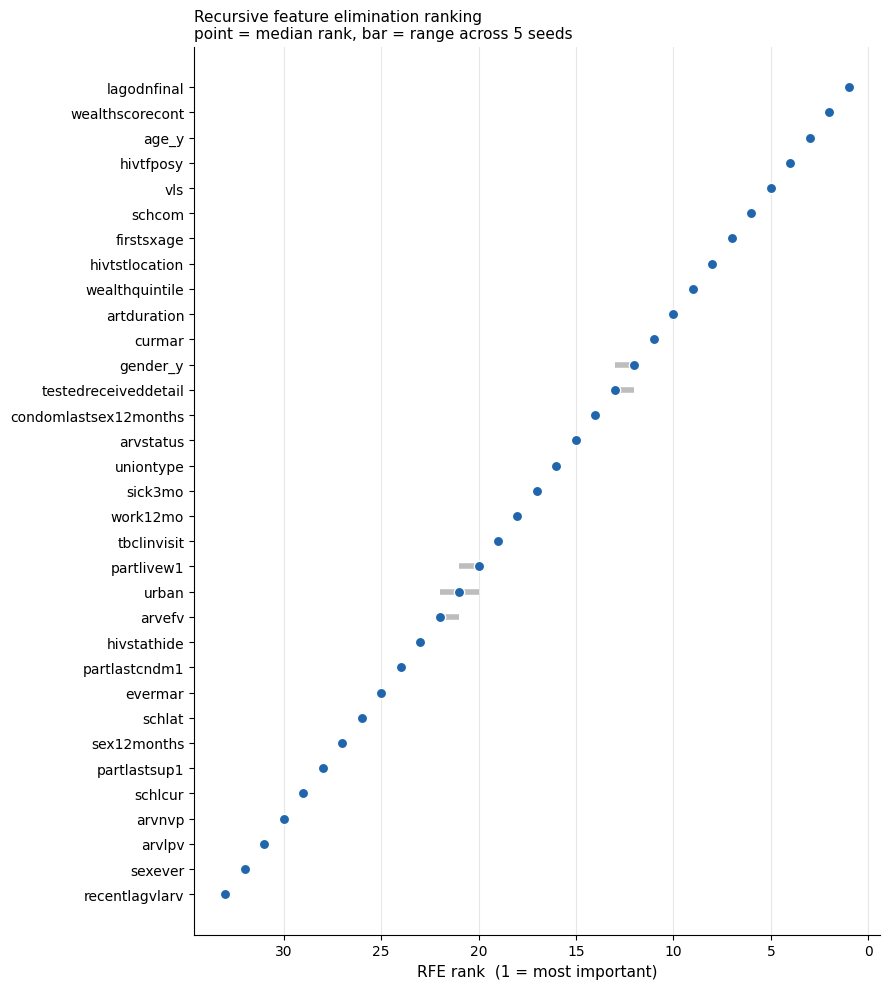

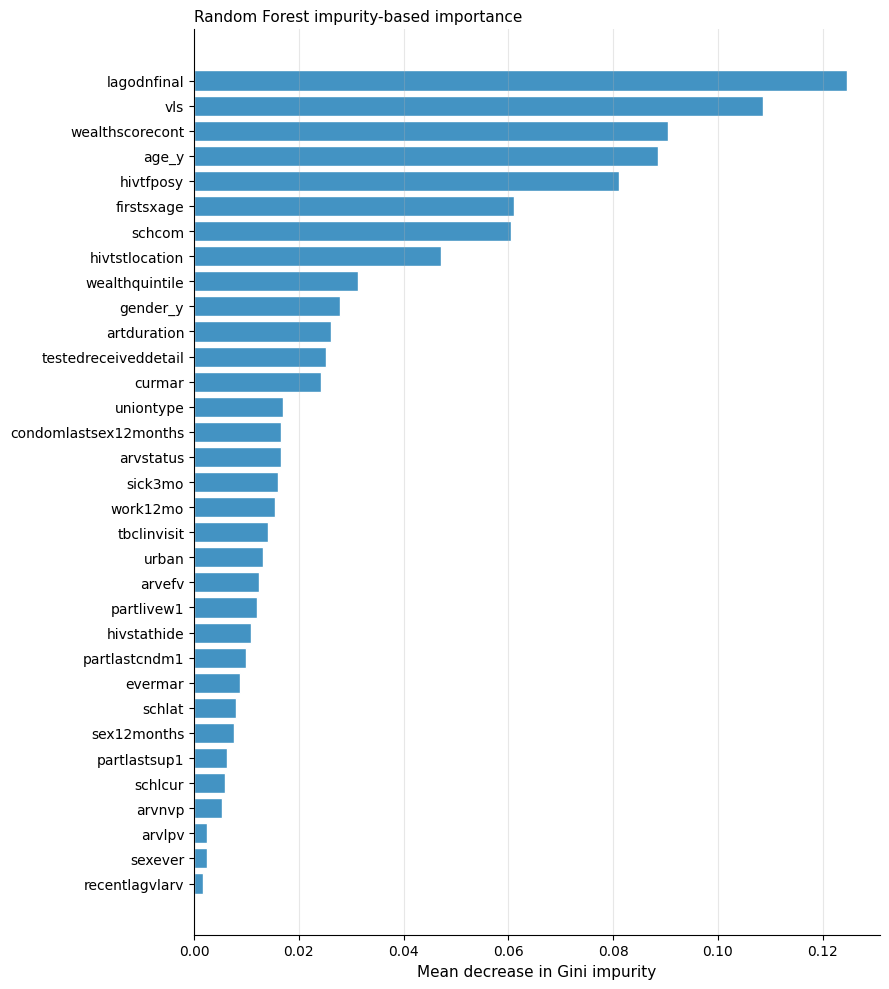


  Saved: RFE_Feature_Ranking.csv, RFE_Rank_Stability.csv
  Saved: fig_rfe_ranking.png, fig_rf_gini_importance.png

  Cell 23 complete — proceed to Cell 24 (clinical exclusion).


In [21]:
# ================================================================
# CELL 23: RECURSIVE FEATURE ELIMINATION (RFE)
#
# Ranks candidate predictors by importance using a Random Forest
# base estimator, fitted on the TRAINING fold only.
#
# Estimator : RandomForestClassifier
#   n_estimators = 300
#   criterion    = 'gini'      (mean decrease in impurity)
#   class_weight = 'balanced'  (AHD prevalence 11.4%)
#
# Stability : RFE is repeated across several random seeds and the
#             median rank reported, since a single run can be
#             sensitive to the seed when predictors are correlated.
#
# NOTE: this ranking INFORMS the final predictor set; it does not
# determine it. Clinical and practical exclusions are applied
# separately in the following cell.
# ================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier

SEEDS   = [42, 101, 202, 303, 404]   # use [42] for a quick single run
N_TREES = 300

# ----------------------------------------------------------------
# Resolve input frames
# ----------------------------------------------------------------
if 'X_tr_ready' in globals():
    X_fs_tr, X_fs_te = X_tr_ready, X_te_ready
    name_source = "clinical names (renaming cell applied)"
elif 'X_tr_scaled_final' in globals():
    X_fs_tr, X_fs_te = X_tr_scaled_final, X_te_scaled_final
    name_source = "PHIA variable names (renaming cell not yet run)"
else:
    raise NameError(
        "Neither X_tr_ready nor X_tr_scaled_final found. "
        "Run the scaling and renaming cells first.")

print("=" * 70)
print("  CELL 23: RECURSIVE FEATURE ELIMINATION (RFE)")
print("=" * 70)
print(f"  Input                : {name_source}")
print(f"  Candidate predictors : {X_fs_tr.shape[1]}")
print(f"  Training observations: {X_fs_tr.shape[0]:,}")
print(f"  AHD prevalence       : {y_tr.mean()*100:.2f}%")
print(f"  Seeds                : {len(SEEDS)}")
print("=" * 70)
print("\n  Running — this may take several minutes.\n")

# ----------------------------------------------------------------
# RFE across seeds
# ----------------------------------------------------------------
rank_matrix = pd.DataFrame(index=X_fs_tr.columns)

for seed in SEEDS:
    rf = RandomForestClassifier(
        n_estimators=N_TREES,
        criterion='gini',
        class_weight='balanced',
        random_state=seed,
        n_jobs=-1
    )
    rfe = RFE(estimator=rf, n_features_to_select=1, step=1)
    rfe.fit(X_fs_tr, y_tr)
    rank_matrix[f"seed_{seed}"] = rfe.ranking_
    print(f"  seed {seed} complete")

# ----------------------------------------------------------------
# Random Forest impurity importance
# (the measure RFE eliminates on)
# ----------------------------------------------------------------
rf_full = RandomForestClassifier(
    n_estimators=N_TREES,
    criterion='gini',
    class_weight='balanced',
    random_state=SEEDS[0],
    n_jobs=-1
).fit(X_fs_tr, y_tr)

gini_importance = pd.Series(
    rf_full.feature_importances_, index=X_fs_tr.columns)

# ----------------------------------------------------------------
# Summary table
# ----------------------------------------------------------------
rfe_df = pd.DataFrame({
    "Feature":         X_fs_tr.columns,
    "RFE Rank":        rank_matrix.median(axis=1).astype(int).values,
    "Rank (min)":      rank_matrix.min(axis=1).values,
    "Rank (max)":      rank_matrix.max(axis=1).values,
    "Gini importance": gini_importance.round(5).values,
}).sort_values("RFE Rank").reset_index(drop=True)

print("\n" + "-" * 70)
print("  FEATURE RANKING (median across seeds)")
print("-" * 70 + "\n")
print(rfe_df.to_string(index=False))

unstable = rfe_df[rfe_df["Rank (max)"] - rfe_df["Rank (min)"] > 5]
if len(unstable):
    print(f"\n  Rank varied by more than 5 positions across seeds "
          f"for {len(unstable)} predictors:")
    for _, r in unstable.iterrows():
        print(f"    {r['Feature']:<30} "
              f"{int(r['Rank (min)'])}–{int(r['Rank (max)'])}")
else:
    print("\n  All ranks stable within 5 positions across seeds.")

rfe_df.to_csv("RFE_Feature_Ranking.csv", index=False)
rank_matrix.to_csv("RFE_Rank_Stability.csv")

# ================================================================
# FIGURE 1 — RANKING WITH STABILITY RANGE
# ================================================================
plot_df = rfe_df.sort_values("RFE Rank", ascending=False)

fig, ax = plt.subplots(figsize=(9, 10))
ax.hlines(plot_df["Feature"], plot_df["Rank (min)"], plot_df["Rank (max)"],
          color='#bdbdbd', linewidth=4, zorder=1)
ax.scatter(plot_df["RFE Rank"], plot_df["Feature"],
           s=55, color='#2166ac', zorder=2, edgecolor='white')

ax.set_xlabel("RFE rank  (1 = most important)", fontsize=11)
ax.invert_xaxis()
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', alpha=0.3)
ax.set_title("Recursive feature elimination ranking\n"
             f"point = median rank, bar = range across {len(SEEDS)} seeds",
             fontsize=11, loc='left')

plt.tight_layout()
plt.savefig("fig_rfe_ranking.png", dpi=300, bbox_inches='tight')
plt.show()

# ================================================================
# FIGURE 2 — GINI IMPORTANCE
# ================================================================
imp_df = rfe_df.sort_values("Gini importance")

fig, ax = plt.subplots(figsize=(9, 10))
ax.barh(imp_df["Feature"], imp_df["Gini importance"],
        color='#4393c3', edgecolor='white')
ax.set_xlabel("Mean decrease in Gini impurity", fontsize=11)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', alpha=0.3)
ax.set_title("Random Forest impurity-based importance",
             fontsize=11, loc='left')

plt.tight_layout()
plt.savefig("fig_rf_gini_importance.png", dpi=300, bbox_inches='tight')
plt.show()

print("\n  Saved: RFE_Feature_Ranking.csv, RFE_Rank_Stability.csv")
print("  Saved: fig_rfe_ranking.png, fig_rf_gini_importance.png")
print("\n  Cell 23 complete — proceed to Cell 24 (clinical exclusion).")

In [22]:
# ================================================================
# CELL 23b: VARIABLE RENAMING
# PHIA codes -> clinical names
# ================================================================

import pandas as pd

column_mapping = {
    'vls':                    'viral_load_suppressed',
    'arvefv':                 'arv_efavirenz_based',
    'arvstatus':              'art_status',
    'arvlpv':                 'arv_lopinavir_based',
    'arvnvp':                 'arv_nevirapine_based',
    'artduration':            'art_duration_category',
    'lagodnfinal':            'lag_avidity_odn',
    'recentlagvlarv':         'recent_infection',
    'hivstathide':            'hiv_status_disclosure',
    'sick3mo':                'chronic_illness',
    'tbclinvisit':            'tb_clinic_visit',
    'testedreceiveddetail':   'hiv_test_result_detail',
    'hivtstlocation':         'hiv_test_location',
    'age_y':                  'age',
    'gender_y':               'gender',
    'urban':                  'residence',
    'wealthscorecont':        'wealth_score',
    'wealthquintile':         'wealth_quintile',
    'schcom':                 'school_completed_years',
    'schlcur':                'currently_attending_school',
    'schlat':                 'attended_school',
    'work12mo':               'employment_status',
    'curmar':                 'current_marital_status',
    'evermar':                'marital_status',
    'uniontype':              'union_type',
    'firstsxage':             'age_first_sex',
    'sexever':                'ever_had_sex',
    'sex12months':            'sex_last_12m',
    'condomlastsex12months':  'condom_use',
    'partlastsup1':           'transactional_sex',
    'partlivew1':             'partner_lives_with',
    'partlastcndm1':          'part_condom_use',
    'hivtfposy':              'hiv_first_positive_year'
}

X_tr_ready = X_tr_scaled_final.rename(columns=column_mapping).copy()
X_te_ready = X_te_scaled_final.rename(columns=column_mapping).copy()

common = X_tr_ready.columns.intersection(X_te_ready.columns)
X_tr_ready = X_tr_ready[common]
X_te_ready = X_te_ready[common]

print("=" * 60)
print("  CELL 23b: VARIABLE RENAMING")
print("=" * 60)
print(f"\n  Features : {X_tr_ready.shape[1]}")
print(f"  Train    : {X_tr_ready.shape}")
print(f"  Test     : {X_te_ready.shape}")
print(f"  Match    : {list(X_tr_ready.columns) == list(X_te_ready.columns)}\n")

for i, c in enumerate(X_tr_ready.columns, 1):
    print(f"  [{i:02d}] {c}")

print("\n  Cell 23b complete.")

  CELL 23b: VARIABLE RENAMING

  Features : 33
  Train    : (22095, 33)
  Test     : (614, 33)
  Match    : True

  [01] arv_efavirenz_based
  [02] transactional_sex
  [03] tb_clinic_visit
  [04] partner_lives_with
  [05] hiv_test_result_detail
  [06] school_completed_years
  [07] lag_avidity_odn
  [08] art_status
  [09] arv_lopinavir_based
  [10] age
  [11] wealth_quintile
  [12] marital_status
  [13] arv_nevirapine_based
  [14] age_first_sex
  [15] hiv_test_location
  [16] wealth_score
  [17] employment_status
  [18] part_condom_use
  [19] union_type
  [20] ever_had_sex
  [21] attended_school
  [22] gender
  [23] recent_infection
  [24] art_duration_category
  [25] viral_load_suppressed
  [26] currently_attending_school
  [27] chronic_illness
  [28] condom_use
  [29] current_marital_status
  [30] hiv_first_positive_year
  [31] sex_last_12m
  [32] residence
  [33] hiv_status_disclosure

  Cell 23b complete.


  CELL 23c: REDUNDANCY SCREENING (Spearman, training fold)
  Candidate predictors: 33

--- PAIRS WITH |rho| > 0.8 ---

  Variable A                   Variable B                       rho
  -----------------------------------------------------------------
  arv_efavirenz_based          art_status                    0.8089
  wealth_quintile              wealth_score                  0.9542
  part_condom_use              condom_use                    0.8433

--- RESOLUTION ---

  arv_efavirenz_based <-> art_status (rho=0.8089)
      remove 'art_status', keep 'arv_efavirenz_based'
  wealth_quintile <-> wealth_score (rho=0.9542)
      remove 'wealth_score', keep 'wealth_quintile'
  part_condom_use <-> condom_use (rho=0.8433)
      remove 'part_condom_use', keep 'condom_use'

  All 14 protected predictors retained.


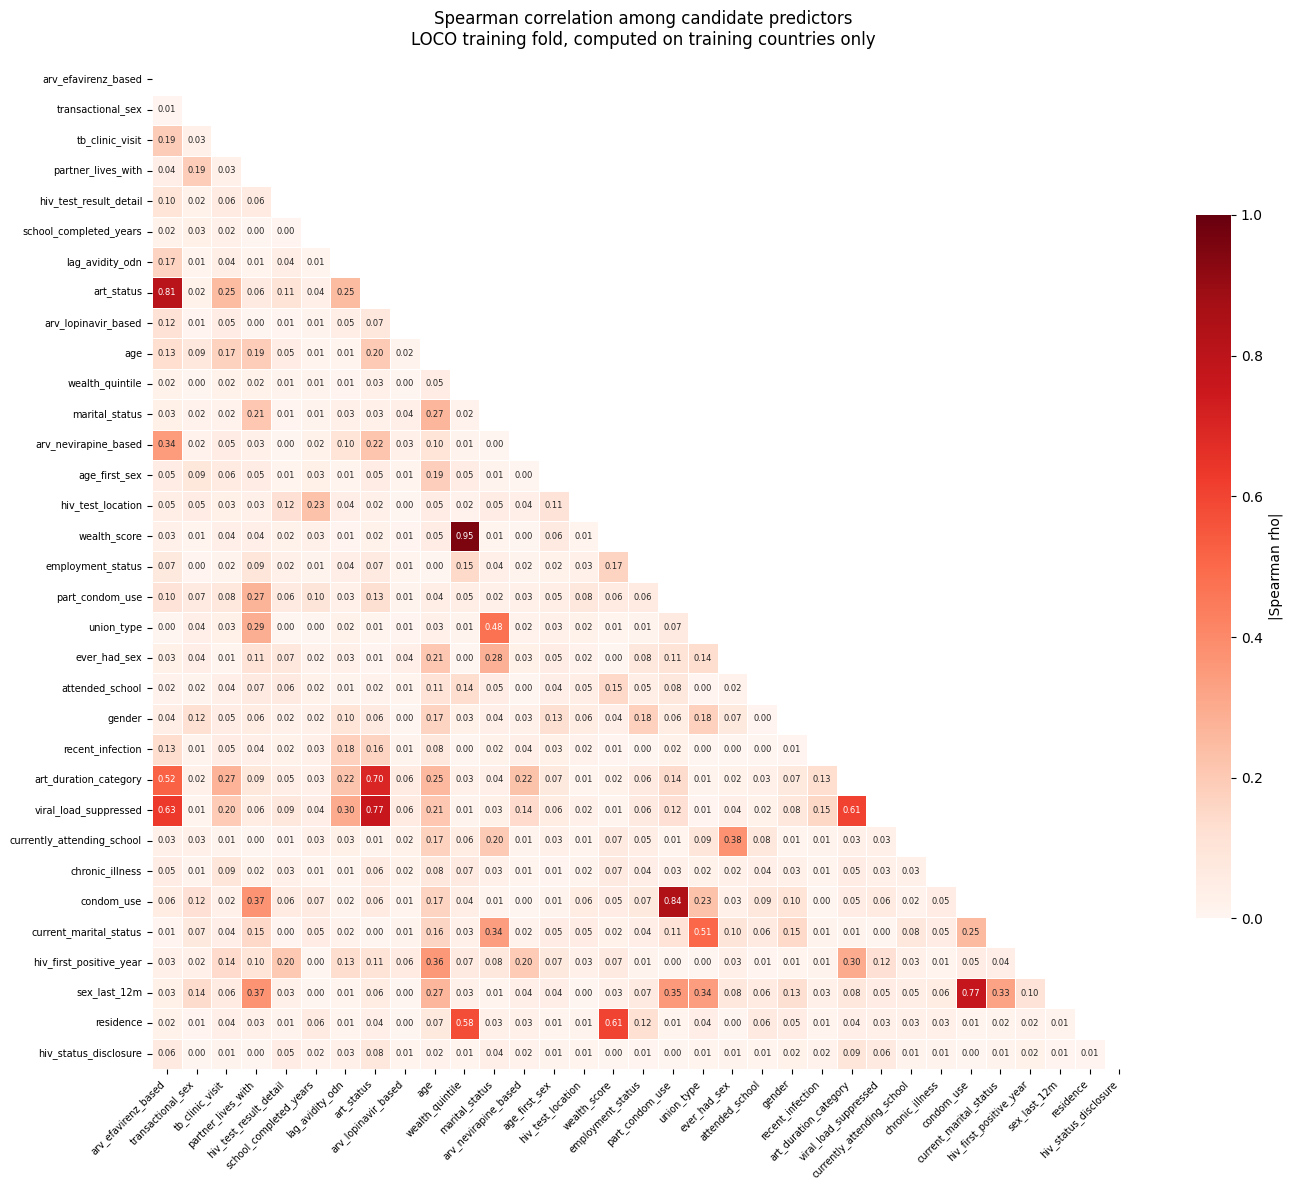


--- SUMMARY ---
  Before     : 33
  Removed    : 3 ['art_status', 'part_condom_use', 'wealth_score']
  After      : 30

  Train shape : (22095, 30)
  Test  shape : (614, 30)
  Columns match: True

  Saved: fig_correlation_heatmap.png, S_Table_correlated_pairs.csv
  Cell 23c complete.


In [25]:
# ================================================================
# CELL 23c: REDUNDANCY SCREENING (SPEARMAN)
# Applied to all candidate predictors, training fold only.
# One variable from each pair with |rho| > 0.80 is removed,
# retaining the clinically interpretable form.
# ================================================================

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

RHO = 0.80

# Clinically interpretable forms — retained preferentially
PROTECTED = {
    'age', 'gender', 'attended_school', 'employment_status',
    'marital_status', 'wealth_quintile', 'tb_clinic_visit',
    'chronic_illness', 'viral_load_suppressed', 'art_duration_category',
    'recent_infection', 'condom_use', 'transactional_sex',
    'hiv_status_disclosure',
}

print("=" * 70)
print("  CELL 23c: REDUNDANCY SCREENING (Spearman, training fold)")
print(f"  Candidate predictors: {X_tr_ready.shape[1]}")
print("=" * 70)

# ---------------- correlation matrix ----------------
corr  = X_tr_ready.corr(method='spearman').abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))

pairs = [(r, c, round(upper.loc[r, c], 4))
         for c in upper.columns for r in upper.index
         if pd.notna(upper.loc[r, c]) and upper.loc[r, c] > RHO]

print(f"\n--- PAIRS WITH |rho| > {RHO} ---\n")
if pairs:
    print(f"  {'Variable A':<28} {'Variable B':<28} {'rho':>7}")
    print(f"  {'-'*65}")
    for a, b, r in pairs:
        print(f"  {a:<28} {b:<28} {r:>7.4f}")
else:
    print("  None")

# ---------------- resolution ----------------
to_remove = []
unresolved = []

print("\n--- RESOLUTION ---\n")
for a, b, r in pairs:
    if a in PROTECTED and b not in PROTECTED:
        drop, keep = b, a
    elif b in PROTECTED and a not in PROTECTED:
        drop, keep = a, b
    elif a in PROTECTED and b in PROTECTED:
        print(f"  {a} <-> {b} (rho={r})")
        print(f"      BOTH PROTECTED — resolve manually, nothing removed")
        unresolved.append((a, b, r))
        continue
    else:
        drop, keep = b, a      # neither protected: default rule

    print(f"  {a} <-> {b} (rho={r})")
    print(f"      remove '{drop}', keep '{keep}'")
    to_remove.append(drop)

to_remove = sorted(set(to_remove))

# ---------------- apply ----------------
X_tr_decorr = X_tr_ready.drop(columns=to_remove, errors='ignore').copy()
X_te_decorr = X_te_ready.drop(columns=to_remove, errors='ignore').copy()

common = X_tr_decorr.columns.intersection(X_te_decorr.columns)
X_tr_decorr = X_tr_decorr[common]
X_te_decorr = X_te_decorr[common]

# ---------------- safety check ----------------
lost = PROTECTED - set(X_tr_decorr.columns)
if lost:
    print(f"\n  WARNING: protected variables removed: {sorted(lost)}")
else:
    print(f"\n  All 14 protected predictors retained.")

# ---------------- heatmap ----------------
plt.figure(figsize=(14, 12))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap='Reds',
            vmin=0, vmax=1, linewidths=0.4, annot_kws={"size": 6},
            cbar_kws={"shrink": 0.7, "label": "|Spearman rho|"})
plt.title("Spearman correlation among candidate predictors\n"
          "LOCO training fold, computed on training countries only",
          fontsize=12, pad=14)
plt.xticks(rotation=45, ha='right', fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()
plt.savefig("fig_correlation_heatmap.png", dpi=300, bbox_inches='tight')
plt.show()

# ---------------- export ----------------
pd.DataFrame(pairs, columns=["Variable_A", "Variable_B", "Spearman_rho"]
             ).to_csv("S_Table_correlated_pairs.csv", index=False)

print(f"\n--- SUMMARY ---")
print(f"  Before     : {X_tr_ready.shape[1]}")
print(f"  Removed    : {len(to_remove)} {to_remove}")
if unresolved:
    print(f"  Unresolved : {len(unresolved)} pair(s) — see above")
print(f"  After      : {X_tr_decorr.shape[1]}")
print(f"\n  Train shape : {X_tr_decorr.shape}")
print(f"  Test  shape : {X_te_decorr.shape}")
print(f"  Columns match: {list(X_tr_decorr.columns) == list(X_te_decorr.columns)}")
print("\n  Saved: fig_correlation_heatmap.png, S_Table_correlated_pairs.csv")
print("  Cell 23c complete.")

In [26]:
# ================================================================
# CELL 24: CLINICAL AND PRACTICAL EXCLUSION
# Removes predictors on clinical and practical grounds,
# with the rationale for each exclusion documented and exported.
# ================================================================

import pandas as pd

print("=" * 70)
print("  CELL 24: CLINICAL AND PRACTICAL EXCLUSION")
print("=" * 70)

exclusion_rationale = {
    'lag_avidity_odn':            'Laboratory assay output; not obtainable outside research settings',
    'arv_efavirenz_based':        'Regimen detail; redundant with ART duration',
    'arv_lopinavir_based':        'Regimen detail; redundant with ART duration',
    'arv_nevirapine_based':       'Regimen detail; redundant with ART duration',
    'art_status':                 'Redundant with ART duration category',
    'hiv_test_result_detail':     'Redundant with viral load suppression',
    'hiv_first_positive_year':    'Calendar artefact; redundant with age and ART duration',
    'school_completed_years':     'Redundant with ever attended school',
    'currently_attending_school': 'Redundant with ever attended school',
    'union_type':                 'Redundant with marital status',
    'current_marital_status':     'Redundant with marital status',
    'part_condom_use':            'Redundant with condom use at last sex',
    'sex_last_12m':               'Redundant with condom use categories',
    'wealth_score':               'Continuous form of wealth quintile; quintile retained',
    'hiv_test_location':          'High missingness (14.8%); nominal variable with 24 categories',
    'age_first_sex':              'Distal behavioural measure; high missingness (7.8%)',
    'ever_had_sex':               'Near-constant (97.6% yes); minimal discriminatory information',
    'residence':                  'Collinear with wealth quintile; strongly country-confounded',
    'partner_lives_with':         'Partner-level variable; high missingness (29.1%)',
}

to_remove = list(exclusion_rationale.keys())
existing   = [c for c in to_remove if c in X_tr_ready.columns]

X_tr_clean = X_tr_ready.drop(columns=existing).copy()
X_te_clean = X_te_ready.drop(columns=existing).copy()

print("\n--- EXCLUSIONS ---\n")
for var, reason in exclusion_rationale.items():
    status = "Removed  " if var in existing else "NOT FOUND"
    print(f"  {var:<30} {status}  {reason}")

print(f"\n--- RETAINED PREDICTORS ({X_tr_clean.shape[1]}) ---\n")
for i, col in enumerate(X_tr_clean.columns, 1):
    n = X_tr_clean[col].nunique()
    vtype = "Binary" if n == 2 else ("Ordinal/Nominal" if n <= 10 else "Continuous")
    print(f"  [{i:02d}] {col:<30} {vtype}")

print(f"\n  Before  : {X_tr_ready.shape[1]}")
print(f"  Removed : {len(existing)}")
print(f"  Retained: {X_tr_clean.shape[1]}")
print(f"\n  Train shape : {X_tr_clean.shape}")
print(f"  Test  shape : {X_te_clean.shape}")
print(f"  Columns match: {list(X_tr_clean.columns) == list(X_te_clean.columns)}")

pd.DataFrame({
    "Variable": list(exclusion_rationale.keys()),
    "Exclusion rationale": list(exclusion_rationale.values())
}).to_csv("S_Table_excluded_variables.csv", index=False)

X_tr_preselect = X_tr_clean.copy()
X_te_preselect = X_te_clean.copy()

print("\n  Saved: S_Table_excluded_variables.csv")
print("  Cell 24 complete.")

  CELL 24: CLINICAL AND PRACTICAL EXCLUSION

--- EXCLUSIONS ---

  lag_avidity_odn                Removed    Laboratory assay output; not obtainable outside research settings
  arv_efavirenz_based            Removed    Regimen detail; redundant with ART duration
  arv_lopinavir_based            Removed    Regimen detail; redundant with ART duration
  arv_nevirapine_based           Removed    Regimen detail; redundant with ART duration
  art_status                     Removed    Redundant with ART duration category
  hiv_test_result_detail         Removed    Redundant with viral load suppression
  hiv_first_positive_year        Removed    Calendar artefact; redundant with age and ART duration
  school_completed_years         Removed    Redundant with ever attended school
  currently_attending_school     Removed    Redundant with ever attended school
  union_type                     Removed    Redundant with marital status
  current_marital_status         Removed    Redundant with marita

  CELL 25: MUTUAL INFORMATION (SENSITIVITY ANALYSIS)

--- RANKING BY MUTUAL INFORMATION ---

                            RFE_rank  MI_score  MI_rank Retained
viral_load_suppressed            NaN   0.03189      1.0      Yes
lag_avidity_odn                  NaN   0.01651      2.0       No
art_status                       NaN   0.00944      3.0       No
art_duration_category            NaN   0.00746      4.0      Yes
gender                           NaN   0.00622      5.0      Yes
arv_efavirenz_based              NaN   0.00605      6.0       No
chronic_illness                  NaN   0.00304      7.0      Yes
hiv_test_result_detail           NaN   0.00290      8.0       No
hiv_test_location                NaN   0.00216      9.0       No
age                              NaN   0.00152     10.0      Yes
hiv_first_positive_year          NaN   0.00147     11.0       No
age_first_sex                    NaN   0.00114     12.0       No
arv_nevirapine_based             NaN   0.00096     13.0       

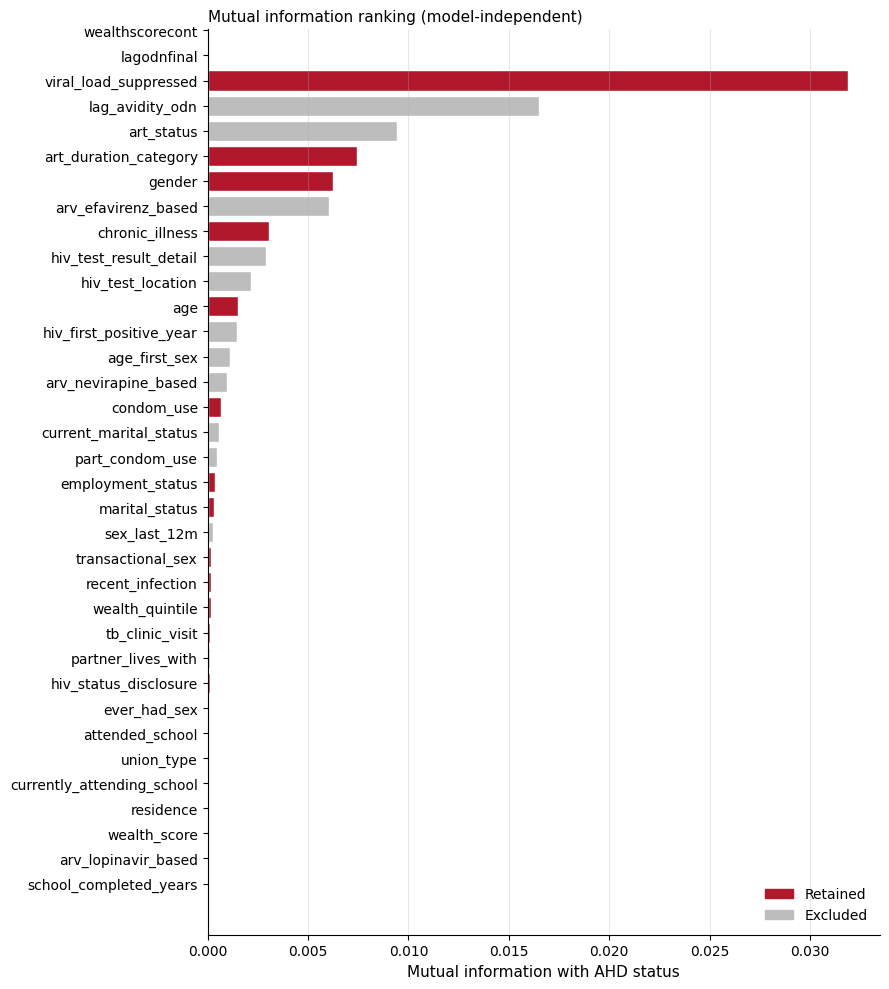


  Saved: S_Table_MI_sensitivity.csv, fig_mutual_information.png
  Cell 25 complete.


In [35]:
# ================================================================
# CELL 25: SENSITIVITY ANALYSIS — MUTUAL INFORMATION
# Model-independent importance ranking, to test whether the
# Random Forest based ranking biased the selection.
# ================================================================

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_classif

print("=" * 70)
print("  CELL 25: MUTUAL INFORMATION (SENSITIVITY ANALYSIS)")
print("=" * 70)

discrete_mask = [X_tr_ready[c].nunique() <= 10 for c in X_tr_ready.columns]

mi = mutual_info_classif(
    X_tr_ready, y_tr,
    discrete_features=discrete_mask,
    random_state=42
)

mi_score = pd.Series(mi, index=X_tr_ready.columns, name="MI_score")
mi_rank  = mi_score.rank(ascending=False).astype(int).rename("MI_rank")

rfe_rank = rfe_df.set_index("Feature")["RFE Rank"].rename("RFE_rank")

compare = pd.concat([rfe_rank, mi_score.round(5), mi_rank], axis=1)
compare["Retained"] = np.where(
    compare.index.isin(X_tr_preselect.columns), "Yes", "No")
compare = compare.sort_values("MI_rank")

print("\n--- RANKING BY MUTUAL INFORMATION ---\n")
print(compare.to_string())

rho = compare["RFE_rank"].corr(compare["MI_rank"], method="spearman")
print(f"\n  Spearman correlation between RFE and MI ranks "
      f"(all 33): {rho:.3f}")

kept = compare[compare["Retained"] == "Yes"]
print(f"\n  Retained predictors: median MI rank "
      f"{kept['MI_rank'].median():.0f} of 33")
print(f"  Retained predictors in MI top 14: "
      f"{(kept['MI_rank'] <= 14).sum()} of 14")

compare.to_csv("S_Table_MI_sensitivity.csv")

# ---------------- figure ----------------
fig, ax = plt.subplots(figsize=(9, 10))
p = compare.sort_values("MI_score")
colors = ['#b2182b' if r == "Yes" else '#bdbdbd' for r in p["Retained"]]
ax.barh(p.index, p["MI_score"], color=colors, edgecolor='white')
ax.set_xlabel("Mutual information with AHD status", fontsize=11)
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', alpha=0.3)
handles = [plt.Rectangle((0,0),1,1,color='#b2182b'),
           plt.Rectangle((0,0),1,1,color='#bdbdbd')]
ax.legend(handles, ['Retained', 'Excluded'], loc='lower right', frameon=False)
ax.set_title("Mutual information ranking (model-independent)",
             fontsize=11, loc='left')
plt.tight_layout()
plt.savefig("fig_mutual_information.png", dpi=300, bbox_inches='tight')
plt.show()

print("\n  Saved: S_Table_MI_sensitivity.csv, fig_mutual_information.png")
print("  Cell 25 complete.")

  CELL 26: FOLD-WISE FEATURE RANKING STABILITY
  11 folds — allow 30-60 minutes

  Ethiopia           done
  Cameroon           done
  Namibia            done
  Côte d'Ivoire      done
  Eswatini           done
  Uganda             done
  Zimbabwe           done
  Zambia             done
  Tanzania           done
  Lesotho            done
  Malawi             done

----------------------------------------------------------------------
  RANK ACROSS THE 11 FOLDS
----------------------------------------------------------------------

                            Median  Min  Max  Range  Top14_count Retained
lag_avidity_odn                1.0    1    1      0           11       No
wealth_score                   2.0    2    2      0           11       No
age                            3.0    3    4      1           11      Yes
hiv_first_positive_year        4.0    3    4      1           11       No
viral_load_suppressed          5.0    5    5      0           11      Yes
school_completed_y

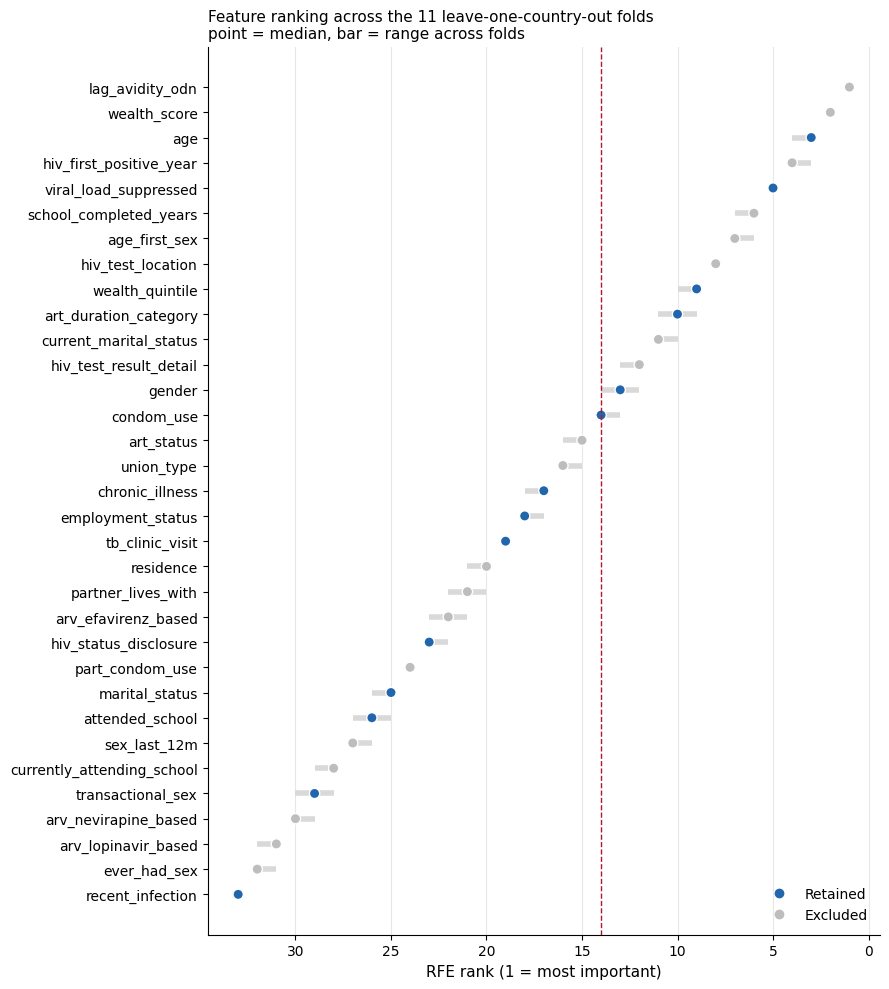


  Saved: S_Table_foldwise_rank_stability.csv
  Saved: S_Table_foldwise_rank_summary.csv
  Saved: fig_foldwise_rank_stability.png
  Cell 26 complete.


In [36]:
# ================================================================
# CELL 26: SENSITIVITY ANALYSIS — FOLD-WISE RANKING STABILITY
#
# Repeats the RFE ranking independently within each LOCO training
# fold, to test whether predictor ranking depends on which country
# is held out. Does NOT change the main analysis.
# ================================================================

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier

SEED = 42
drop_cols_fs = ['cd4_who_category', 'country_y', 'cd4count',
                'cd4cat', 'cd4tty', 'time_since_last_cd4',
                'time_since_cd4_cat', 'survey_year']

def prepare_fold(df, test_country):
    tr = df['country_y'] != test_country
    X = df.loc[tr].drop(
        columns=[c for c in drop_cols_fs if c in df.columns]).copy()
    y = df.loc[tr, 'cd4_who_category'].copy()

    binary = [c for c in X.columns if X[c].dropna().nunique() == 2]
    categ  = [c for c in X.columns
              if 2 < X[c].dropna().nunique() <= 10 and c not in binary]
    conts  = [c for c in X.columns if c not in binary + categ]

    X[binary + categ] = SimpleImputer(
        strategy="most_frequent").fit_transform(X[binary + categ])
    if conts:
        X[conts] = IterativeImputer(
            max_iter=10, random_state=SEED).fit_transform(X[conts])
        X[conts] = StandardScaler().fit_transform(X[conts])

    X = X.rename(columns=column_mapping)
    return X, y

countries = model_df['country_y'].unique()
fold_ranks = {}

print("=" * 70)
print("  CELL 26: FOLD-WISE FEATURE RANKING STABILITY")
print(f"  {len(countries)} folds — allow 30-60 minutes")
print("=" * 70 + "\n")

for country in countries:
    X_f, y_f = prepare_fold(model_df, country)
    rf = RandomForestClassifier(n_estimators=300, criterion='gini',
                                class_weight='balanced',
                                random_state=SEED, n_jobs=-1)
    rfe = RFE(estimator=rf, n_features_to_select=1, step=1).fit(X_f, y_f)
    fold_ranks[country] = pd.Series(rfe.ranking_, index=X_f.columns)
    print(f"  {country:<18} done")

ranks = pd.DataFrame(fold_ranks)
n_folds = len(countries)

summary = pd.DataFrame({
    "Median": ranks.median(axis=1),
    "Min":    ranks.min(axis=1),
    "Max":    ranks.max(axis=1),
})
summary["Range"] = summary["Max"] - summary["Min"]
summary["Top14_count"] = (ranks <= 14).sum(axis=1)
summary["Retained"] = np.where(
    summary.index.isin(X_tr_preselect.columns), "Yes", "No")
summary = summary.sort_values("Median")

print("\n" + "-" * 70)
print("  RANK ACROSS THE 11 FOLDS")
print("-" * 70 + "\n")
print(summary.to_string())

kept = summary[summary["Retained"] == "Yes"]
print(f"\n  Retained predictors: median rank range "
      f"{kept['Range'].min():.0f}-{kept['Range'].max():.0f}")
print(f"  Mean rank range across all predictors: "
      f"{summary['Range'].mean():.1f} positions")

ranks.to_csv("S_Table_foldwise_rank_stability.csv")
summary.to_csv("S_Table_foldwise_rank_summary.csv")

# ---------------- figure ----------------
fig, ax = plt.subplots(figsize=(9, 10))
p = summary.sort_values("Median", ascending=False)
colors = ['#2166ac' if r == "Yes" else '#bdbdbd' for r in p["Retained"]]

ax.hlines(p.index, p["Min"], p["Max"], color='#d9d9d9', linewidth=4)
ax.scatter(p["Median"], p.index, s=55, c=colors,
           zorder=2, edgecolor='white')
ax.axvline(14, ls='--', color='#b2182b', linewidth=1)

ax.set_xlabel("RFE rank (1 = most important)", fontsize=11)
ax.invert_xaxis()
ax.spines[['top', 'right']].set_visible(False)
ax.grid(axis='x', alpha=0.3)
ax.set_title("Feature ranking across the 11 leave-one-country-out folds\n"
             "point = median, bar = range across folds",
             fontsize=11, loc='left')

handles = [plt.Line2D([], [], marker='o', ls='', color='#2166ac'),
           plt.Line2D([], [], marker='o', ls='', color='#bdbdbd')]
ax.legend(handles, ['Retained', 'Excluded'],
          loc='lower right', frameon=False)

plt.tight_layout()
plt.savefig("fig_foldwise_rank_stability.png", dpi=300, bbox_inches='tight')
plt.show()

print("\n  Saved: S_Table_foldwise_rank_stability.csv")
print("  Saved: S_Table_foldwise_rank_summary.csv")
print("  Saved: fig_foldwise_rank_stability.png")
print("  Cell 26 complete.")

 RANDOM FOREST FEATURE IMPORTANCE

Feature Importance Ranking
--------------------------------------------------
                       Feature  Importance
6              lag_avidity_odn    0.141052
21       viral_load_suppressed    0.115059
8                          age    0.099402
26     hiv_first_positive_year    0.091548
12               age_first_sex    0.069661
5       school_completed_years    0.069465
13           hiv_test_location    0.053580
9              wealth_quintile    0.043071
20       art_duration_category    0.029679
18                      gender    0.028341
4       hiv_test_result_detail    0.027995
25      current_marital_status    0.026468
24                  condom_use    0.021335
15                  union_type    0.018932
0          arv_efavirenz_based    0.017798
14           employment_status    0.017380
23             chronic_illness    0.016595
28                   residence    0.016028
2              tb_clinic_visit    0.015790
3           partner_lives_w

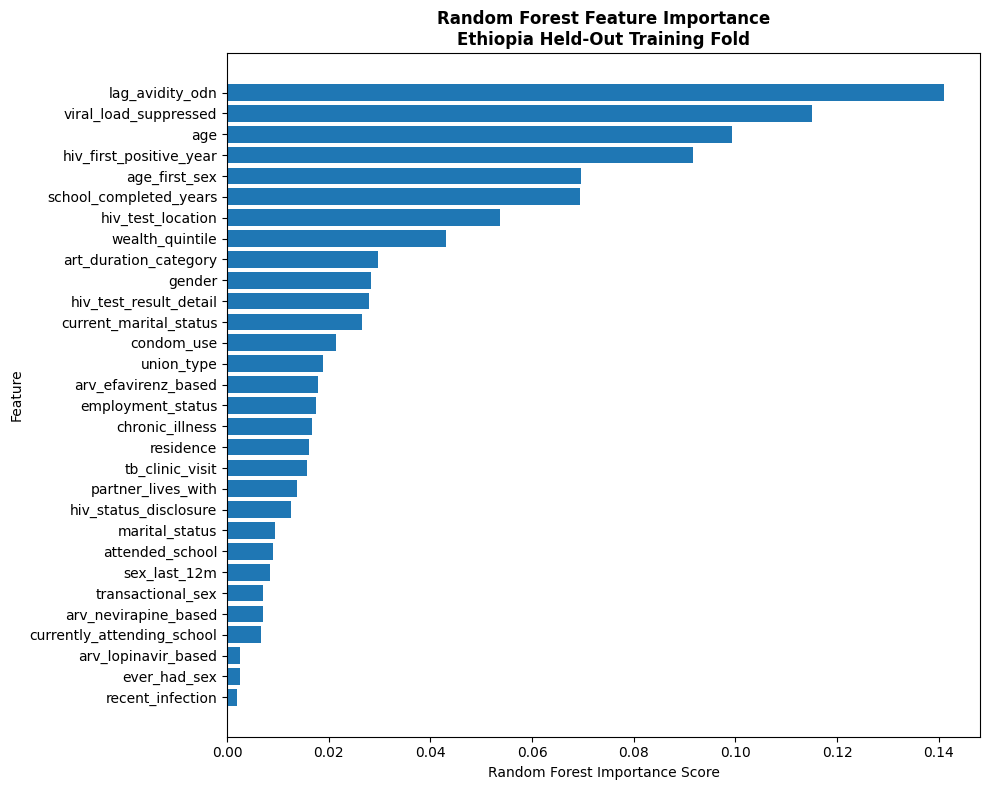


✅ Figure saved:
fig_random_forest_importance.png


In [27]:
# ============================================================
# RANDOM FOREST FEATURE IMPORTANCE PLOT
# ALL 14 VARIABLES
# Publication Ready Figure
# ============================================================

from sklearn.ensemble import RandomForestClassifier
import pandas as pd
import matplotlib.pyplot as plt

print("="*60)
print(" RANDOM FOREST FEATURE IMPORTANCE")
print("="*60)

# ------------------------------------------------------------
# TRAIN RANDOM FOREST
# ------------------------------------------------------------

rf = RandomForestClassifier(
    n_estimators=500,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1
)

rf.fit(X_tr_decorr, y_tr)

# ------------------------------------------------------------
# EXTRACT IMPORTANCE
# ------------------------------------------------------------

importance_df = pd.DataFrame({
    "Feature": X_tr_decorr.columns,
    "Importance": rf.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print("\nFeature Importance Ranking")
print("-"*50)
print(importance_df)

# ------------------------------------------------------------
# PLOT
# ------------------------------------------------------------

plt.figure(figsize=(10,8))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Random Forest Importance Score")
plt.ylabel("Feature")

plt.title(
    "Random Forest Feature Importance\n"
    "Ethiopia Held-Out Training Fold",
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "fig_random_forest_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\n✅ Figure saved:")
print("fig_random_forest_importance.png")

In [28]:
# ================================================================
# CELL 28: FINAL VARIABLE AUDIT
# Review the 14 retained predictors before model training
# ================================================================

import pandas as pd
import numpy as np

# ---------------- manuscript display labels ----------------
# Code names are kept for pipeline continuity; these are the
# labels used in figures and tables.
display_names = {
    'age':                   'Age',
    'gender':                'Gender',
    'attended_school':       'Ever attended school',
    'employment_status':     'Employment',
    'marital_status':        'marital_status',
    'wealth_quintile':       'wealth quintile',
    'tb_clinic_visit':       'Ever visited a TB clinic',
    'chronic_illness':       'Prolonged illness (>3months)',
    'viral_load_suppressed': 'Viral load suppressed',
    'art_duration_category': 'ART duration',
    'recent_infection':      'HIV infection recency',
    'condom_use':            'Condom use at last sex (past 12 months)',
    'transactional_sex':     'Transactional sex (most recent partner)',
    'hiv_status_disclosure': 'HIV status concealment (past 12 months)',
}

print("=" * 80)
print("  CELL 28: FINAL VARIABLE AUDIT")
print(f"  Predictors: {X_tr_preselect.shape[1]}")
print("=" * 80)

# ---------------- summary table ----------------
rows = []
for col in X_tr_preselect.columns:
    s = X_tr_preselect[col]
    vals = (sorted(s.dropna().unique().tolist())
            if s.nunique() <= 15 else "continuous")
    rows.append([
        col,
        display_names.get(col, col),
        str(s.dtype),
        s.nunique(),
        s.isna().sum(),
        round(float(s.min()), 3),
        round(float(s.max()), 3),
        vals,
    ])

audit_df = pd.DataFrame(rows, columns=[
    "Variable", "Display label", "DataType", "Unique",
    "Missing", "Min", "Max", "Observed values"])

pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 250)
print("\n" + audit_df.to_string(index=False))

# ---------------- detailed review ----------------
print("\n" + "=" * 80)
print("  DETAILED REVIEW")
print("=" * 80)

for col in X_tr_preselect.columns:
    s = X_tr_preselect[col]
    print(f"\n{'-' * 60}")
    print(f"  {display_names.get(col, col)}   [{col}]")
    print(f"{'-' * 60}")
    print(f"  Missing : {s.isna().sum()}   Unique: {s.nunique()}")

    if s.nunique() <= 20:
        print("\n" + s.value_counts(dropna=False).sort_index().to_string())
    else:
        print(f"  Mean {s.mean():.3f}  SD {s.std():.3f}  "
              f"Range {s.min():.3f} to {s.max():.3f}")

# ---------------- checks ----------------
print("\n" + "=" * 80)
print("  CHECKS")
print("=" * 80)
print(f"  Missing values remaining : {X_tr_preselect.isna().sum().sum()}")
print(f"  Train shape              : {X_tr_preselect.shape}")
print(f"  Test  shape              : {X_te_preselect.shape}")
print(f"  Columns match            : "
      f"{list(X_tr_preselect.columns) == list(X_te_preselect.columns)}")
print(f"  All have display labels  : "
      f"{all(c in display_names for c in X_tr_preselect.columns)}")

audit_df.to_csv("S_Table_variable_audit.csv", index=False)
print("\n  Saved: S_Table_variable_audit.csv")
print("  Cell 28 complete — ready for model training.")

  CELL 28: FINAL VARIABLE AUDIT
  Predictors: 14

             Variable                           Display label DataType  Unique  Missing   Min   Max Observed values
    transactional_sex Transactional sex (most recent partner)    int32       2        0  1.00 2.000          [1, 2]
      tb_clinic_visit                Ever visited a TB clinic    int32       2        0  1.00 2.000          [1, 2]
                  age                                     Age  float64      66        0 -2.07 3.601      continuous
      wealth_quintile                         wealth quintile    int32       5        0  1.00 5.000 [1, 2, 3, 4, 5]
       marital_status                          marital_status    int32       2        0  1.00 2.000          [1, 2]
    employment_status                              Employment    int32       2        0  1.00 2.000          [1, 2]
      attended_school                    Ever attended school    int32       2        0  1.00 2.000          [1, 2]
               gender 

In [29]:
# cell 29============================================================
# FINAL VARIABLE AUDIT
# Entire analytical dataset (Training + Test)
# N = 22,709
# ============================================================

import pandas as pd
import numpy as np

print("="*80)
print("FINAL VARIABLE AUDIT")
print("Entire analytical dataset (Training + Test)")
print("="*80)

# ============================================================
# COMBINE TRAIN + TEST
# ============================================================

X_full = pd.concat(
    [X_tr_preselect, X_te_preselect],
    axis=0
).reset_index(drop=True)

y_full = pd.concat(
    [y_tr, y_te],
    axis=0
).reset_index(drop=True)

print(f"\nTotal participants : {len(X_full):,}")

# ============================================================
# VARIABLE AUDIT
# ============================================================

audit_results = []

for col in X_full.columns:

    dtype = str(X_full[col].dtype)

    n_unique = X_full[col].nunique()

    missing = X_full[col].isna().sum()

    min_val = X_full[col].min()
    max_val = X_full[col].max()

    if n_unique <= 15:
        values = sorted(
            X_full[col]
            .dropna()
            .unique()
            .tolist()
        )
    else:
        values = "Too many values"

    audit_results.append([
        col,
        dtype,
        n_unique,
        missing,
        min_val,
        max_val,
        values
    ])

audit_df = pd.DataFrame(
    audit_results,
    columns=[
        "Variable",
        "DataType",
        "UniqueValues",
        "Missing",
        "Min",
        "Max",
        "Observed Values"
    ]
)

pd.set_option("display.max_colwidth", None)

print("\n")
print(audit_df)

# ============================================================
# DETAILED REVIEW
# ============================================================

print("\n")
print("="*80)
print("DETAILED VARIABLE REVIEW")
print("="*80)

for col in X_full.columns:

    print(f"\n{'='*60}")
    print(f"VARIABLE: {col}")
    print(f"{'='*60}")

    print(f"Data Type     : {X_full[col].dtype}")
    print(f"Missing       : {X_full[col].isna().sum()}")
    print(f"Unique Values : {X_full[col].nunique()}")

    if X_full[col].nunique() <= 20:

        print("\nObserved Values:")

        print(
            X_full[col]
            .value_counts(dropna=False)
            .sort_index()
        )

    else:

        print(f"\nMinimum : {X_full[col].min()}")
        print(f"Maximum : {X_full[col].max()}")
        print(f"Mean    : {X_full[col].mean():.3f}")
        print(f"Std Dev : {X_full[col].std():.3f}")

print("\n")
print("="*80)
print("SUMMARY")
print("="*80)

print(f"Total participants : {len(X_full):,}")
print(f"Variables reviewed : {X_full.shape[1]}")
print(f"Outcome available  : {len(y_full):,}")

print("\n✅ Variable audit completed successfully.")

FINAL VARIABLE AUDIT
Entire analytical dataset (Training + Test)

Total participants : 22,709


                 Variable DataType  UniqueValues  Missing       Min       Max  Observed Values
0       transactional_sex    int32             2        0  1.000000  2.000000           [1, 2]
1         tb_clinic_visit    int32             2        0  1.000000  2.000000           [1, 2]
2                     age  float64            66        0 -2.070089  3.600586  Too many values
3         wealth_quintile    int32             5        0  1.000000  5.000000  [1, 2, 3, 4, 5]
4          marital_status    int32             2        0  1.000000  2.000000           [1, 2]
5       employment_status    int32             2        0  1.000000  2.000000           [1, 2]
6         attended_school    int32             2        0  1.000000  2.000000           [1, 2]
7                  gender    int32             2        0  1.000000  2.000000           [1, 2]
8        recent_infection    int32             2 

In [30]:
# ================================================================
# CELL 30: TABLE 1 — PARTICIPANT CHARACTERISTICS
# Raw (observed) values, full analytical sample N = 22,709
# ================================================================

import pandas as pd
import numpy as np

df = model_df.copy().rename(columns={
    'age_y':                 'age',
    'gender_y':              'gender',
    'schlat':                'attended_school',
    'work12mo':              'employment_status',
    'evermar':               'marital_status',
    'wealthquintile':        'wealth_quintile',
    'vls':                   'viral_load_suppressed',
    'tbclinvisit':           'tb_clinic_visit',
    'recentlagvlarv':        'recent_infection',
    'artduration':           'art_duration_category',
    'sick3mo':               'chronic_illness',
    'condomlastsex12months': 'condom_use',
    'partlastsup1':          'transactional_sex',
    'hivstathide':           'hiv_status_disclosure',
})

value_labels = {
    'gender':                {1: 'Male', 2: 'Female'},
    'attended_school':       {1: 'Yes', 2: 'No'},
    'employment_status':     {1: 'Yes', 2: 'No'},
    'marital_status':        {1: 'Yes', 2: 'No'},
    'wealth_quintile':       {1: 'Lowest', 2: 'Second', 3: 'Middle',
                              4: 'Fourth', 5: 'Highest'},
    'viral_load_suppressed': {1: 'Suppressed (<1,000 copies/mL)',
                              2: 'Not suppressed'},
    'art_duration_category': {1: '24 months or more', 2: '12-23 months',
                              3: 'Less than 12 months', 4: 'Not on ART'},
    'recent_infection':      {1: 'Recent', 2: 'Long-standing'},
    'tb_clinic_visit':       {1: 'Yes', 2: 'No'},
    'chronic_illness':       {1: 'Yes', 2: 'No'},
    'condom_use':            {1: 'Condom used', 2: 'Condom not used',
                              3: 'No sexual intercourse in period'},
    'transactional_sex':     {1: 'Yes', 2: 'No'},
    'hiv_status_disclosure': {1: 'Felt need to hide status',
                              2: 'No need to hide status',
                              3: 'Did not attend a health facility'},
}

row_titles = {
    'gender':                'Gender',
    'attended_school':       'Ever attended school',
    'employment_status':     'Paid work in past 12 months',
    'marital_status':        'Ever married or cohabited',
    'wealth_quintile':       'Household wealth quintile',
    'viral_load_suppressed': 'Viral load suppression',
    'art_duration_category': 'ART duration',
    'recent_infection':      'HIV infection recency',
    'tb_clinic_visit':       'Ever visited a TB clinic',
    'chronic_illness':       'Prolonged illness (>=3 months)',
    'condom_use':            'Condom use at last sex (past 12 months)',
    'transactional_sex':     'Transactional sex (most recent partner)',
    'hiv_status_disclosure': 'HIV status concealment (past 12 months)',
}

print("=" * 78)
print("  TABLE 1. CHARACTERISTICS OF STUDY PARTICIPANTS")
print(f"  N = {len(df):,}")
print("=" * 78)

table1 = []

# ---------------- age ----------------
a = df['age'].dropna()
print(f"\n  Age, years")
print(f"    Mean (SD)   : {a.mean():.1f} ({a.std():.1f})")
print(f"    Median (IQR): {a.median():.0f} "
      f"({a.quantile(.25):.0f}-{a.quantile(.75):.0f})")
print(f"    Range       : {a.min():.0f}-{a.max():.0f}")
print(f"    Missing     : {df['age'].isna().sum()}")

table1.append(["Age, years", "Mean (SD)",
               f"{a.mean():.1f} ({a.std():.1f})", "", 0])

# ---------------- categorical ----------------
for var, title in row_titles.items():
    valid = df[var].dropna()
    miss  = df[var].isna().sum()

    print(f"\n  {title}")
    for code, label in value_labels[var].items():
        n   = int((valid == code).sum())
        pct = n / len(valid) * 100 if len(valid) else 0
        print(f"    {label:<38} {n:>6,}  ({pct:>5.1f}%)")
        table1.append([title, label, f"{n:,}", f"{pct:.1f}", miss])
    if miss:
        print(f"    {'Missing':<38} {miss:>6,}  "
              f"({miss/len(df)*100:>5.2f}%)")

# ---------------- outcome ----------------
print("\n" + "=" * 78)
print("  OUTCOME")
print("=" * 78)
y_all = df['cd4_who_category']
for code, label in {0: 'No AHD (CD4 >=200)', 1: 'AHD (CD4 <200)'}.items():
    n = int((y_all == code).sum())
    print(f"    {label:<38} {n:>6,}  ({n/len(y_all)*100:>5.1f}%)")
    table1.append(["Advanced HIV disease", label,
                   f"{n:,}", f"{n/len(y_all)*100:.1f}", 0])

# ---------------- export ----------------
t1 = pd.DataFrame(table1, columns=[
    "Characteristic", "Category", "n", "%", "Missing (n)"])
t1.to_csv("Table1_participant_characteristics.csv", index=False)

print("\n" + "=" * 78)
print("  Saved: Table1_participant_characteristics.csv")
print("  Cell 30 complete.")

  TABLE 1. CHARACTERISTICS OF STUDY PARTICIPANTS
  N = 22,709

  Age, years
    Mean (SD)   : 38.7 (11.4)
    Median (IQR): 38 (30-46)
    Range       : 15-80
    Missing     : 0

  Gender
    Male                                    7,280  ( 32.1%)
    Female                                 15,429  ( 67.9%)

  Ever attended school
    Yes                                    20,495  ( 90.3%)
    No                                      2,197  (  9.7%)
    Missing                                    17  ( 0.07%)

  Paid work in past 12 months
    Yes                                     9,706  ( 42.8%)
    No                                     12,988  ( 57.2%)
    Missing                                    15  ( 0.07%)

  Ever married or cohabited
    Yes                                    18,550  ( 81.7%)
    No                                      4,142  ( 18.3%)
    Missing                                    17  ( 0.07%)

  Household wealth quintile
    Lowest                            

In [31]:
# cell 31============================================================
# SHARED SETUP — Run ONCE before all model cells
# ============================================================

import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    RandomizedSearchCV, StratifiedKFold)
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    f1_score, recall_score, precision_score,
    confusion_matrix, accuracy_score,
    balanced_accuracy_score, make_scorer)

FIXED_14_VARIABLES = [
    'age',
    'viral_load_suppressed',
    'art_duration_category',
    'wealth_quintile',
    'gender',
    'employment_status',
    'hiv_status_disclosure',
    'tb_clinic_visit',
    'chronic_illness',
    'condom_use',
    'marital_status',
    'transactional_sex',
    'attended_school',
    'recent_infection'
]

leakage_vars = [
    'cd4count', 'cd4cat', 'cd4tty',
    'time_since_last_cd4',
    'time_since_cd4_cat',
    'survey_year'
]

drop_cols = ['cd4_who_category', 'country_y'] + leakage_vars

column_mapping = {
    'vls':                   'viral_load_suppressed',
    'arvefv':                'arv_efavirenz_based',
    'arvstatus':             'art_status',
    'arvlpv':                'arv_lopinavir_based',
    'arvnvp':                'arv_nevirapine_based',
    'artduration':           'art_duration_category',
    'lagodnfinal':           'lag_avidity_odn',
    'recentlagvlarv':        'recent_infection',
    'hivstathide':           'hiv_status_disclosure',
    'sick3mo':               'chronic_illness',
    'tbclinvisit':           'tb_clinic_visit',
    'testedreceiveddetail':  'hiv_test_result_detail',
    'hivtstlocation':        'hiv_test_location',
    'age_y':                 'age',
    'gender_y':              'gender',
    'urban':                 'residence',
    'wealthscorecont':       'wealth_score',
    'wealthquintile':        'wealth_quintile',
    'schcom':                'school_completed_years',
    'schlcur':               'currently_attending_school',
    'schlat':                'attended_school',
    'work12mo':              'employment_status',
    'curmar':                'current_marital_status',
    'evermar':               'marital_status',
    'uniontype':             'union_type',
    'firstsxage':            'age_first_sex',
    'sexever':               'ever_had_sex',
    'sex12months':           'sex_last_12m',
    'condomlastsex12months': 'condom_use',
    'partlastsup1':          'transactional_sex',
    'partlivew1':            'partner_lives_with',
    'partlastcndm1':         'partner_condom_use',
    'hivtfposy':             'hiv_first_positive_year'
}

pr_auc_scorer = make_scorer(
    average_precision_score,
    pos_label=1,
    response_method='predict_proba')

def preprocess_fold(
        model_df, test_country,
        drop_cols, column_mapping):

    train_mask = model_df['country_y'] != test_country
    test_mask  = model_df['country_y'] == test_country

    X_tr = model_df.loc[train_mask].drop(
        columns=[c for c in drop_cols
                 if c in model_df.columns]).copy()
    y_tr = model_df.loc[train_mask, 'cd4_who_category'].copy()

    X_te = model_df.loc[test_mask].drop(
        columns=[c for c in drop_cols
                 if c in model_df.columns]).copy()
    y_te = model_df.loc[test_mask, 'cd4_who_category'].copy()

    X_te = X_te.reindex(columns=X_tr.columns)

    binary_cols = [
        c for c in X_tr.columns
        if X_tr[c].dropna().nunique() == 2]
    categorical_cols = [
        c for c in X_tr.columns
        if 2 < X_tr[c].dropna().nunique() <= 10
        and c not in binary_cols]
    continuous_cols = [
        c for c in X_tr.columns
        if c not in binary_cols + categorical_cols]

    mode_cols = binary_cols + categorical_cols
    mode_imp  = SimpleImputer(strategy="most_frequent")
    mice_imp  = IterativeImputer(max_iter=10, random_state=42)

    X_tr[mode_cols] = mode_imp.fit_transform(X_tr[mode_cols])
    X_te[mode_cols] = mode_imp.transform(X_te[mode_cols])
    for col in mode_cols:
        X_tr[col] = np.round(X_tr[col]).astype(int)
        X_te[col] = np.round(X_te[col]).astype(int)

    if continuous_cols:
        X_tr[continuous_cols] = \
            mice_imp.fit_transform(X_tr[continuous_cols])
        X_te[continuous_cols] = \
            mice_imp.transform(X_te[continuous_cols])

    scaler = StandardScaler()
    X_tr_s = pd.DataFrame(
        scaler.fit_transform(X_tr),
        columns=X_tr.columns, index=X_tr.index)
    X_te_s = pd.DataFrame(
        scaler.transform(X_te),
        columns=X_te.columns, index=X_te.index)

    mapping_used = {
        k: v for k, v in column_mapping.items()
        if k in X_tr_s.columns}
    X_tr_s = X_tr_s.rename(columns=mapping_used)
    X_te_s = X_te_s.rename(columns=mapping_used)
    X_tr_s.columns = X_tr_s.columns.str.replace(" ", "_")
    X_te_s.columns = X_te_s.columns.str.replace(" ", "_")

    final_vars = [
        c for c in FIXED_14_VARIABLES
        if c in X_tr_s.columns and c in X_te_s.columns]
    X_tr_s = X_tr_s[final_vars].copy()
    X_te_s = X_te_s[final_vars].copy()

    return X_tr_s, X_te_s, y_tr, y_te, len(final_vars)

def evaluate_fold(
        y_te, y_prob_te,
        y_tr, y_prob_tr,
        test_country, n_features,
        best_params, best_inner):

    thresholds = np.linspace(0.01, 0.99, 200)
    best_t = max(
        thresholds,
        key=lambda t: f1_score(
            y_tr, (y_prob_tr >= t).astype(int),
            pos_label=1, zero_division=0))

    y_pred = (y_prob_te >= best_t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_te, y_pred).ravel()

    roc     = roc_auc_score(y_te, y_prob_te)
    pr      = average_precision_score(y_te, y_prob_te)
    acc     = accuracy_score(y_te, y_pred)
    bal_acc = balanced_accuracy_score(y_te, y_pred)
    f1      = f1_score(y_te, y_pred, pos_label=1, zero_division=0)
    rec     = recall_score(y_te, y_pred, pos_label=1, zero_division=0)
    prec    = precision_score(y_te, y_pred, pos_label=1, zero_division=0)

    sens = tp/(tp+fn) if (tp+fn) > 0 else 0
    spec = tn/(tn+fp) if (tn+fp) > 0 else 0
    ppv  = tp/(tp+fp) if (tp+fp) > 0 else 0
    npv  = tn/(tn+fn) if (tn+fn) > 0 else 0

    print(f"  ROC-AUC={roc:.4f} | PR-AUC={pr:.4f} | "
          f"Acc={acc:.4f} | F1={f1:.4f} | Recall={rec:.4f} | "
          f"AHD caught={tp}/{int(y_te.sum())}")

    return {
        'Country':      test_country,
        'ROC-AUC':      round(roc,     4),
        'PR-AUC':       round(pr,      4),
        'Accuracy':     round(acc,     4),
        'Balanced Acc': round(bal_acc, 4),
        'F1-Score':     round(f1,      4),
        'Recall':       round(rec,     4),
        'Precision':    round(prec,    4),
        'Sensitivity':  round(sens,    4),
        'Specificity':  round(spec,    4),
        'PPV':          round(ppv,     4),
        'NPV':          round(npv,     4),
        'Threshold':    round(best_t,  4),
        'Best_InnerCV': round(best_inner, 4)
            if best_inner is not None else None,
        'Best_Params':  str(best_params)
            if best_params is not None else 'Fixed',
        'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
        'AHD N':      int(y_te.sum()),
        'Good N':     int((y_te == 0).sum()),
        'Test N':     len(y_te),
        'N Features': n_features
    }

def print_summary(df, model_name):
    metrics = [
        'ROC-AUC', 'PR-AUC', 'Accuracy',
        'Balanced Acc', 'F1-Score', 'Recall',
        'Precision', 'Sensitivity',
        'Specificity', 'NPV'
    ]
    print(f"\n{'='*65}")
    print(f"  LOCO SUMMARY — {model_name}")
    print(f"{'='*65}")
    cols = ['Country'] + metrics + ['N Features']
    if 'Best_InnerCV' in df.columns:
        cols += ['Best_InnerCV']
    print(df[cols].to_string(index=False))
    print(f"\n--- AVERAGE ACROSS ALL 11 FOLDS ---")
    print(df[metrics].mean().round(4))

print("Shared setup complete")
print(f"   Fixed variables: {len(FIXED_14_VARIABLES)}")

Shared setup complete
   Fixed variables: 14


In [32]:
# ============================================================
# OUTCOME VERIFICATION
# ============================================================

y = model_df['cd4_who_category']

n_ahd = int((y == 1).sum())
n_no  = int((y == 0).sum())
N     = len(y)

print("=" * 60)
print("  ADVANCED HIV DISEASE — OUTCOME")
print("=" * 60)
print(f"  AHD (CD4 <200)      {n_ahd:>7,}  ({n_ahd/N*100:>5.2f}%)")
print(f"  No AHD (CD4 >=200)  {n_no:>7,}  ({n_no/N*100:>5.2f}%)")
print("-" * 60)
print(f"  Total               {N:>7,}")
print(f"  Missing             {int(y.isna().sum()):>7,}")
print(f"  Imbalance ratio     {n_no/n_ahd:>7.2f}:1")
print("=" * 60)

  ADVANCED HIV DISEASE — OUTCOME
  AHD (CD4 <200)        2,595  (11.43%)
  No AHD (CD4 >=200)   20,114  (88.57%)
------------------------------------------------------------
  Total                22,709
  Missing                   0
  Imbalance ratio        7.75:1


In [ ]:
# Modelng

In [33]:
# ============================================================
# CELL 32: LOCO — LOGISTIC REGRESSION
# WITH RandomizedSearchCV — PR-AUC scoring
# Feature set: 14 variables
# ============================================================

from sklearn.linear_model import LogisticRegression

print("="*65)
print("  CELL 32: LOCO — LOGISTIC REGRESSION")
print("  WITH RandomizedSearchCV per fold")
print("  Feature set: 14 variables")
print("  Positive class: AHD (CD4 < 200) = 1")
print("="*65)

countries     = model_df['country_y'].unique()
loco_lr_tuned = []

lr_param_dist = {
    'C':           [0.001, 0.01, 0.1, 0.5,
                    1.0, 5.0, 10.0, 100.0],
    'penalty':     ['l1', 'l2'],
    'solver':      ['liblinear', 'saga'],
    'class_weight': ['balanced',
                     {0:1, 1:5},
                     {0:1, 1:7.79},
                     {0:1, 1:10}],
    'max_iter':    [500, 1000, 2000]
}

for test_country in countries:

    print(f"\n{'='*55}")
    print(f"  Fold: {test_country}")
    print(f"{'='*55}")

    X_tr_s, X_te_s, y_tr, y_te, n_feat = \
        preprocess_fold(
            model_df, test_country,
            drop_cols, column_mapping)

    print(f"  Features: {n_feat} "
          f"{'✅' if n_feat==14 else '⚠'}")
    print(f"  Running RandomizedSearchCV "
          f"(50 iter × 5 folds)...")

    inner_cv = StratifiedKFold(
        n_splits=5, shuffle=True,
        random_state=42)

    search = RandomizedSearchCV(
        estimator=LogisticRegression(
            random_state=42),
        param_distributions=lr_param_dist,
        n_iter=50,
        cv=inner_cv,
        scoring=pr_auc_scorer,
        random_state=42,
        n_jobs=-1,
        verbose=0,
        refit=True)

    search.fit(X_tr_s, y_tr)

    best_model  = search.best_estimator_
    best_params = search.best_params_
    best_inner  = search.best_score_

    print(f"  Best inner CV PR-AUC : "
          f"{best_inner:.4f}")
    print(f"  Best params: {best_params}")

    y_prob_tr = best_model.predict_proba(
        X_tr_s)[:, 1]
    y_prob_te = best_model.predict_proba(
        X_te_s)[:, 1]

    result = evaluate_fold(
        y_te, y_prob_te,
        y_tr, y_prob_tr,
        test_country, n_feat,
        best_params, best_inner)

    loco_lr_tuned.append(result)

lr_tuned_df = pd.DataFrame(loco_lr_tuned)
print_summary(lr_tuned_df, "LOGISTIC REGRESSION")
lr_tuned_df.to_csv(
    'results_lr_tuned_14vars.csv', index=False)

print("\n✅ Cell 32 complete — 14-variable feature set")

  CELL 32: LOCO — LOGISTIC REGRESSION
  WITH RandomizedSearchCV per fold
  Feature set: 14 variables
  Positive class: AHD (CD4 < 200) = 1

  Fold: Ethiopia
  Features: 14 ✅
  Running RandomizedSearchCV (50 iter × 5 folds)...
  Best inner CV PR-AUC : 0.2867
  Best params: {'solver': 'liblinear', 'penalty': 'l1', 'max_iter': 500, 'class_weight': {0: 1, 1: 5}, 'C': 10.0}
  ROC-AUC=0.8189 | PR-AUC=0.3722 | Acc=0.7866 | F1=0.4473 | Recall=0.6463 | AHD caught=53/82

  Fold: Cameroon
  Features: 14 ✅
  Running RandomizedSearchCV (50 iter × 5 folds)...
  Best inner CV PR-AUC : 0.2918
  Best params: {'solver': 'saga', 'penalty': 'l2', 'max_iter': 1000, 'class_weight': {0: 1, 1: 5}, 'C': 100.0}
  ROC-AUC=0.6812 | PR-AUC=0.2346 | Acc=0.6196 | F1=0.3207 | Recall=0.7063 | AHD caught=89/126

  Fold: Namibia
  Features: 14 ✅
  Running RandomizedSearchCV (50 iter × 5 folds)...
  Best inner CV PR-AUC : 0.2941
  Best params: {'solver': 'liblinear', 'penalty': 'l1', 'max_iter': 500, 'class_weight': {0: 

In [34]:
# ============================================================
# CELL 34: LOCO — LightGBM (CORRECTED)
# Fixed: removed duplicate metrics
# Added: Accuracy properly stored
# ============================================================

import lightgbm as lgb

print("="*65)
print("  CELL 34: LOCO — LightGBM (CORRECTED)")
print("  WITH RandomizedSearchCV per fold")
print("="*65)

countries       = model_df['country_y'].unique()
loco_lgbm_tuned = []

lgbm_param_dist = {
    'n_estimators':      [100, 200, 300, 500],
    'learning_rate':     [0.01, 0.05, 0.1, 0.2],
    'max_depth':         [3, 4, 5, 6, 8, -1],
    'num_leaves':        [15, 31, 63, 127],
    'min_child_samples': [10, 20, 30, 50],
    'subsample':         [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree':  [0.6, 0.7, 0.8, 0.9, 1.0],
    'reg_alpha':         [0, 0.01, 0.1, 1.0],
    'reg_lambda':        [0.5, 1.0, 2.0, 5.0],
    'scale_pos_weight':  [5.0, 7.79, 10.0,
                          12.0, 15.0]
}

for test_country in countries:

    print(f"\n{'='*55}")
    print(f"  Fold: {test_country}")
    print(f"{'='*55}")

    X_tr_s, X_te_s, y_tr, y_te, n_feat = \
        preprocess_fold(
            model_df, test_country,
            drop_cols, column_mapping)

    print(f"  Features: {n_feat} "
          f"{'✅' if n_feat==14 else '⚠'}")
    print(f"  Running RandomizedSearchCV "
          f"(50 iter × 5 folds)...")

    inner_cv = StratifiedKFold(
        n_splits=5, shuffle=True,
        random_state=42)

    search = RandomizedSearchCV(
        estimator=lgb.LGBMClassifier(
            random_state=42,
            verbose=-1, n_jobs=-1),
        param_distributions=lgbm_param_dist,
        n_iter=50,
        cv=inner_cv,
        scoring=pr_auc_scorer,
        random_state=42,
        n_jobs=-1,
        verbose=0,
        refit=True)

    search.fit(X_tr_s, y_tr)

    best_model  = search.best_estimator_
    best_params = search.best_params_
    best_inner  = search.best_score_

    print(f"  Best inner CV PR-AUC : "
          f"{best_inner:.4f}")
    print(f"  Best params: {best_params}")

    y_prob_tr = best_model.predict_proba(
        X_tr_s)[:, 1]
    y_prob_te = best_model.predict_proba(
        X_te_s)[:, 1]

    result = evaluate_fold(
        y_te, y_prob_te,
        y_tr, y_prob_tr,
        test_country, n_feat,
        best_params, best_inner)

    loco_lgbm_tuned.append(result)

lgbm_tuned_df = pd.DataFrame(loco_lgbm_tuned)
print_summary(lgbm_tuned_df, "LightGBM")
lgbm_tuned_df.to_csv(
    'results_lgbm_tuned.csv', index=False)

print("\n--- BEST HYPERPARAMETERS PER FOLD ---")
for _, row in lgbm_tuned_df.iterrows():
    print(f"  {row['Country']:<20}: "
          f"{row['Best_Params']}")

print("\n✅ Cell 34 complete")

  CELL 34: LOCO — LightGBM (CORRECTED)
  WITH RandomizedSearchCV per fold

  Fold: Ethiopia
  Features: 14 ✅
  Running RandomizedSearchCV (50 iter × 5 folds)...
  Best inner CV PR-AUC : 0.3139
  Best params: {'subsample': 0.6, 'scale_pos_weight': 12.0, 'reg_lambda': 2.0, 'reg_alpha': 0.01, 'num_leaves': 127, 'n_estimators': 200, 'min_child_samples': 50, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.6}
  ROC-AUC=0.8322 | PR-AUC=0.4139 | Acc=0.8046 | F1=0.4595 | Recall=0.6220 | AHD caught=51/82

  Fold: Cameroon
  Features: 14 ✅
  Running RandomizedSearchCV (50 iter × 5 folds)...
  Best inner CV PR-AUC : 0.3199
  Best params: {'subsample': 1.0, 'scale_pos_weight': 12.0, 'reg_lambda': 2.0, 'reg_alpha': 0.1, 'num_leaves': 31, 'n_estimators': 100, 'min_child_samples': 50, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.6}
  ROC-AUC=0.7066 | PR-AUC=0.2691 | Acc=0.6720 | F1=0.3381 | Recall=0.6587 | AHD caught=83/126

  Fold: Namibia
  Features: 14 ✅
  Running Randomi

In [35]:
# ============================================================
# CELL 35: LOCO — XGBoost
# WITH RandomizedSearchCV — PR-AUC scoring
# ============================================================

from xgboost import XGBClassifier

print("="*65)
print("  CELL 35: LOCO — XGBoost")
print("  WITH RandomizedSearchCV per fold")
print("="*65)

countries      = model_df['country_y'].unique()
loco_xgb_tuned = []

xgb_param_dist = {
    'n_estimators':     [100, 200, 300, 500],
    'learning_rate':    [0.01, 0.05, 0.1, 0.2],
    'max_depth':        [3, 4, 5, 6, 8],
    'subsample':        [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'reg_alpha':        [0, 0.01, 0.1, 1.0],
    'reg_lambda':       [0.5, 1.0, 2.0, 5.0],
    'scale_pos_weight': [5.0, 7.79, 10.0,
                         12.0, 15.0],
    'min_child_weight': [1, 3, 5, 10]
}

for test_country in countries:

    print(f"\n{'='*55}")
    print(f"  Fold: {test_country}")
    print(f"{'='*55}")

    X_tr_s, X_te_s, y_tr, y_te, n_feat = \
        preprocess_fold(
            model_df, test_country,
            drop_cols, column_mapping)

    print(f"  Features: {n_feat} "
          f"{'✅' if n_feat==14 else '⚠'}")
    print(f"  Running RandomizedSearchCV "
          f"(50 iter × 5 folds)...")

    inner_cv = StratifiedKFold(
        n_splits=5, shuffle=True,
        random_state=42)

    search = RandomizedSearchCV(
        estimator=XGBClassifier(
            random_state=42,
            eval_metric='logloss',
            verbosity=0,
            n_jobs=-1),
        param_distributions=xgb_param_dist,
        n_iter=50,
        cv=inner_cv,
        scoring=pr_auc_scorer,
        random_state=42,
        n_jobs=-1,
        verbose=0,
        refit=True)

    search.fit(X_tr_s, y_tr)

    best_model  = search.best_estimator_
    best_params = search.best_params_
    best_inner  = search.best_score_

    print(f"  Best inner CV PR-AUC : "
          f"{best_inner:.4f}")
    print(f"  Best params: {best_params}")

    y_prob_tr = best_model.predict_proba(
        X_tr_s)[:, 1]
    y_prob_te = best_model.predict_proba(
        X_te_s)[:, 1]

    result = evaluate_fold(
        y_te, y_prob_te,
        y_tr, y_prob_tr,
        test_country, n_feat,
        best_params, best_inner)

    loco_xgb_tuned.append(result)

xgb_tuned_df = pd.DataFrame(loco_xgb_tuned)
print_summary(xgb_tuned_df, "XGBoost")
xgb_tuned_df.to_csv(
    'results_xgb_tuned.csv', index=False)
print("\n✅ Cell 35 complete")

  CELL 35: LOCO — XGBoost
  WITH RandomizedSearchCV per fold

  Fold: Ethiopia
  Features: 14 ✅
  Running RandomizedSearchCV (50 iter × 5 folds)...
  Best inner CV PR-AUC : 0.3138
  Best params: {'subsample': 0.9, 'scale_pos_weight': 5.0, 'reg_lambda': 5.0, 'reg_alpha': 1.0, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 0.8}
  ROC-AUC=0.8355 | PR-AUC=0.4215 | Acc=0.8062 | F1=0.4758 | Recall=0.6585 | AHD caught=54/82

  Fold: Cameroon
  Features: 14 ✅
  Running RandomizedSearchCV (50 iter × 5 folds)...
  Best inner CV PR-AUC : 0.3216
  Best params: {'subsample': 0.6, 'scale_pos_weight': 5.0, 'reg_lambda': 1.0, 'reg_alpha': 0.01, 'n_estimators': 100, 'min_child_weight': 3, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.6}
  ROC-AUC=0.6976 | PR-AUC=0.2648 | Acc=0.6408 | F1=0.3258 | Recall=0.6825 | AHD caught=86/126

  Fold: Namibia
  Features: 14 ✅
  Running RandomizedSearchCV (50 iter × 5 folds)...
  Best inner CV PR-A

In [37]:
# ============================================================
# CELL 36: LOCO — KNN
# WITH RandomizedSearchCV — PR-AUC scoring
# ============================================================

from sklearn.neighbors import KNeighborsClassifier

print("="*65)
print("  CELL 36: LOCO — KNN")
print("  WITH RandomizedSearchCV per fold")
print("="*65)

countries      = model_df['country_y'].unique()
loco_knn_tuned = []

knn_param_dist = {
    'n_neighbors': [3, 5, 7, 9, 11,
                    15, 21, 31, 51],
    'weights':     ['uniform', 'distance'],
    'metric':      ['euclidean', 'manhattan',
                    'minkowski'],
    'leaf_size':   [10, 20, 30, 50],
    'p':           [1, 2]
}

for test_country in countries:

    print(f"\n{'='*55}")
    print(f"  Fold: {test_country}")
    print(f"{'='*55}")

    X_tr_s, X_te_s, y_tr, y_te, n_feat = \
        preprocess_fold(
            model_df, test_country,
            drop_cols, column_mapping)

    print(f"  Features: {n_feat} "
          f"{'✅' if n_feat==14 else '⚠'}")
    print(f"  Running RandomizedSearchCV "
          f"(30 iter × 5 folds)...")

    inner_cv = StratifiedKFold(
        n_splits=5, shuffle=True,
        random_state=42)

    # KNN has smaller search space so 30 iter enough
    search = RandomizedSearchCV(
        estimator=KNeighborsClassifier(
            n_jobs=-1),
        param_distributions=knn_param_dist,
        n_iter=30,
        cv=inner_cv,
        scoring=pr_auc_scorer,
        random_state=42,
        n_jobs=-1,
        verbose=0,
        refit=True)

    search.fit(X_tr_s, y_tr)

    best_model  = search.best_estimator_
    best_params = search.best_params_
    best_inner  = search.best_score_

    print(f"  Best inner CV PR-AUC : "
          f"{best_inner:.4f}")
    print(f"  Best params: {best_params}")

    y_prob_tr = best_model.predict_proba(
        X_tr_s)[:, 1]
    y_prob_te = best_model.predict_proba(
        X_te_s)[:, 1]

    result = evaluate_fold(
        y_te, y_prob_te,
        y_tr, y_prob_tr,
        test_country, n_feat,
        best_params, best_inner)

    loco_knn_tuned.append(result)

knn_tuned_df = pd.DataFrame(loco_knn_tuned)
print_summary(knn_tuned_df, "KNN")
knn_tuned_df.to_csv(
    'results_knn_tuned.csv', index=False)
print("\n✅ Cell 36 complete")

  CELL 36: LOCO — KNN
  WITH RandomizedSearchCV per fold

  Fold: Ethiopia
  Features: 14 ✅
  Running RandomizedSearchCV (30 iter × 5 folds)...
  Best inner CV PR-AUC : 0.2584
  Best params: {'weights': 'uniform', 'p': 2, 'n_neighbors': 51, 'metric': 'manhattan', 'leaf_size': 10}
  ROC-AUC=0.7631 | PR-AUC=0.3242 | Acc=0.7818 | F1=0.3909 | Recall=0.5244 | AHD caught=43/82

  Fold: Cameroon
  Features: 14 ✅
  Running RandomizedSearchCV (30 iter × 5 folds)...
  Best inner CV PR-AUC : 0.2626
  Best params: {'weights': 'uniform', 'p': 1, 'n_neighbors': 51, 'metric': 'manhattan', 'leaf_size': 50}
  ROC-AUC=0.6985 | PR-AUC=0.2649 | Acc=0.6650 | F1=0.3140 | Recall=0.6032 | AHD caught=76/126

  Fold: Namibia
  Features: 14 ✅
  Running RandomizedSearchCV (30 iter × 5 folds)...
  Best inner CV PR-AUC : 0.2681
  Best params: {'weights': 'uniform', 'p': 2, 'n_neighbors': 51, 'metric': 'manhattan', 'leaf_size': 10}
  ROC-AUC=0.7882 | PR-AUC=0.2366 | Acc=0.8608 | F1=0.3333 | Recall=0.4497 | AHD caugh

In [36]:
# ============================================================
# CELL 33: LOCO — RANDOM FOREST
# WITH RandomizedSearchCV per fold
# Tuning metric: PR-AUC (AHD positive class)
# Positive class: AHD (CD4 < 200) = 1
# ==========================================================

from sklearn.ensemble import RandomForestClassifier

print("="*65)
print("  CELL 33: LOCO — RANDOM FOREST")
print("  WITH RandomizedSearchCV per fold")
print("  Tuning metric: PR-AUC (AHD class)")
print("  Positive class: AHD (CD4 < 200) = 1")
print("="*65)

countries     = model_df['country_y'].unique()
loco_rf_tuned = []

rf_param_dist = {
    'n_estimators':      [100, 200, 300, 500],
    'max_depth':         [3, 5, 8, 10, None],
    'min_samples_leaf':  [1, 5, 10, 20],
    'min_samples_split': [2, 5, 10],
    'max_features':      ['sqrt', 'log2', 0.5],
    'class_weight':      [
        'balanced',
        'balanced_subsample',
        {0:1, 1:5},
        {0:1, 1:7.79},
        {0:1, 1:10}
    ]
}

for test_country in countries:

    print(f"\n{'='*55}")
    print(f"  Fold: {test_country}")
    print(f"{'='*55}")

    X_tr_s, X_te_s, y_tr, y_te, n_feat = \
        preprocess_fold(
            model_df, test_country,
            drop_cols, column_mapping)

    print(f"  Features: {n_feat} "
          f"{'✅' if n_feat==14 else '⚠'}")
    print(f"  Running RandomizedSearchCV "
          f"(50 iter × 5 folds)...")

    inner_cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42)

    search = RandomizedSearchCV(
        estimator=RandomForestClassifier(
            random_state=42,
            n_jobs=-1),
        param_distributions=rf_param_dist,
        n_iter=50,
        cv=inner_cv,
        scoring=pr_auc_scorer,
        random_state=42,
        n_jobs=-1,
        verbose=0,
        refit=True)

    search.fit(X_tr_s, y_tr)

    best_model  = search.best_estimator_
    best_params = search.best_params_
    best_inner  = search.best_score_

    print(f"  Best inner CV PR-AUC : "
          f"{best_inner:.4f}")
    print(f"  Best params: {best_params}")

    y_prob_tr = best_model.predict_proba(
        X_tr_s)[:, 1]
    y_prob_te = best_model.predict_proba(
        X_te_s)[:, 1]

    result = evaluate_fold(
        y_te, y_prob_te,
        y_tr, y_prob_tr,
        test_country, n_feat,
        best_params, best_inner)

    loco_rf_tuned.append(result)

rf_tuned_df = pd.DataFrame(loco_rf_tuned)

# ============================================================
# SUMMARY
# ============================================================
print("\n" + "="*65)
print("  LOCO SUMMARY — RANDOM FOREST")
print("="*65)
print(rf_tuned_df[[
    'Country', 'ROC-AUC', 'PR-AUC',
    'Accuracy', 'Balanced Acc',
    'F1-Score', 'Recall', 'Precision',
    'Sensitivity', 'Specificity', 'NPV',
    'Best_InnerCV', 'N Features'
]].to_string(index=False))

print("\n--- AVERAGE ACROSS ALL 11 FOLDS ---")
print(rf_tuned_df[[
    'ROC-AUC', 'PR-AUC', 'Accuracy',
    'Balanced Acc', 'F1-Score', 'Recall',
    'Precision', 'Sensitivity',
    'Specificity', 'NPV'
]].mean().round(4))

print("\n--- BEST HYPERPARAMETERS PER FOLD ---")
for _, row in rf_tuned_df.iterrows():
    print(f"  {row['Country']:<20}: "
          f"{row['Best_Params']}")

rf_tuned_df.to_csv(
    'results_rf_tuned.csv', index=False)

print("\n✅ Cell 33 complete — "
      "proceed to Cell 36 (KNN)")

  CELL 33: LOCO — RANDOM FOREST
  WITH RandomizedSearchCV per fold
  Tuning metric: PR-AUC (AHD class)
  Positive class: AHD (CD4 < 200) = 1

  Fold: Ethiopia
  Features: 14 ✅
  Running RandomizedSearchCV (50 iter × 5 folds)...
  Best inner CV PR-AUC : 0.3143
  Best params: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 20, 'max_features': 0.5, 'max_depth': 5, 'class_weight': 'balanced_subsample'}
  ROC-AUC=0.8344 | PR-AUC=0.4035 | Acc=0.7997 | F1=0.4721 | Recall=0.6707 | AHD caught=55/82

  Fold: Cameroon
  Features: 14 ✅
  Running RandomizedSearchCV (50 iter × 5 folds)...
  Best inner CV PR-AUC : 0.3194
  Best params: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 20, 'max_features': 0.5, 'max_depth': 5, 'class_weight': 'balanced_subsample'}
  ROC-AUC=0.7035 | PR-AUC=0.2686 | Acc=0.6468 | F1=0.3371 | Recall=0.7063 | AHD caught=89/126

  Fold: Namibia
  Features: 14 ✅
  Running RandomizedSearchCV (50 iter × 5 folds)...
  Best inner CV PR-AUC : 0.3

In [38]:
# ============================================================
# CELL 39: FINAL TABLE 2 — ALL COMPLETED MODELS
# Safe version — works even if some models
# are still pending
# ============================================================

import pandas as pd
import numpy as np

print("=" * 65)
print("  FINAL MANUSCRIPT TABLE 2")
print("  Tuned Models — AHD = Positive Class")
print("=" * 65)

# ============================================================
# STEP 1: SAFELY COLLECT COMPLETED MODELS
# ============================================================
all_models = {}

model_map = {
    'Logistic Regression': 'lr_tuned_df',
    'Random Forest':       'rf_tuned_df',
    'LightGBM':            'lgbm_tuned_df',
    'XGBoost':             'xgb_tuned_df',
    'KNN':                 'knn_tuned_df'
}

print("\n  Checking model availability:")
for model_name, var_name in model_map.items():
    try:
        df = eval(var_name)
        all_models[model_name] = df
        print(f"  ✅ {model_name:<25} "
              f"— {len(df)} folds")
    except NameError:
        print(f"  ⚠  {model_name:<25} "
              f"— not yet run")

if len(all_models) == 0:
    print("\n  ❌ No models found.")
    print("     Run model cells first.")
else:
    print(f"\n  {len(all_models)} of 5 models "
          f"available for Table 2")

# ============================================================
# STEP 2: BUILD TABLE 2
# ============================================================
metrics = [
    'ROC-AUC', 'PR-AUC', 'Accuracy',
    'Balanced Acc', 'F1-Score', 'Recall',
    'Precision', 'Sensitivity',
    'Specificity', 'NPV'
]

table2_rows = []

for model_name, df in all_models.items():
    row = {'Model': model_name}
    for m in metrics:
        if m in df.columns:
            row[m] = round(df[m].mean(), 4)
        else:
            row[m] = None
    table2_rows.append(row)

table2_df = pd.DataFrame(table2_rows)
table2_df = table2_df.sort_values(
    'ROC-AUC', ascending=False)

# ============================================================
# STEP 3: PRINT TABLE 2
# ============================================================
print(f"\n{'='*65}")
print(f"  TABLE 2: Average LOCO Performance")
print(f"  Positive class: AHD (CD4 < 200) = 1")
print(f"{'='*65}\n")

print(table2_df.to_string(index=False))

# ============================================================
# STEP 4: PRINT CLINICAL SUMMARY
# ============================================================
print(f"\n{'='*65}")
print(f"  CLINICAL INTERPRETATION")
print(f"{'='*65}")

if len(table2_df) > 0:

    best_roc = table2_df.loc[
        table2_df['ROC-AUC'].idxmax()]
    best_rec = table2_df.loc[
        table2_df['Recall'].idxmax()]
    best_npv = table2_df.loc[
        table2_df['NPV'].idxmax()]
    best_pr  = table2_df.loc[
        table2_df['PR-AUC'].idxmax()]

    print(f"\n  Best ROC-AUC  : "
          f"{best_roc['Model']} "
          f"({best_roc['ROC-AUC']:.4f})")
    print(f"  Best PR-AUC   : "
          f"{best_pr['Model']} "
          f"({best_pr['PR-AUC']:.4f})")
    print(f"  Best Recall   : "
          f"{best_rec['Model']} "
          f"({best_rec['Recall']:.4f})")
    print(f"  Best NPV      : "
          f"{best_npv['Model']} "
          f"({best_npv['NPV']:.4f})")

    print(f"\n  Clinical meaning:")
    print(f"  → {best_rec['Model']} catches the "
          f"most AHD patients "
          f"({best_rec['Recall']*100:.1f}%)")
    print(f"  → {best_npv['Model']} is safest "
          f"for ruling out AHD "
          f"(NPV={best_npv['NPV']:.4f})")

# ============================================================
# STEP 5: COUNTRY-LEVEL BEST MODEL TABLE
# ============================================================
print(f"\n{'='*65}")
print(f"  BEST MODEL PER COUNTRY (ROC-AUC)")
print(f"{'='*65}\n")

country_best = {}

for model_name, df in all_models.items():
    for _, row in df.iterrows():
        country = row['Country']
        roc     = row['ROC-AUC']
        if country not in country_best or \
                roc > country_best[country][1]:
            country_best[country] = (
                model_name, roc)

print(f"  {'Country':<20} "
      f"{'Best Model':<25} "
      f"{'ROC-AUC':>8}")
print(f"  {'-'*55}")

for country, (model, roc) in sorted(
        country_best.items()):
    print(f"  {country:<20} "
          f"{model:<25} "
          f"{roc:>8.4f}")

# ============================================================
# STEP 6: FEATURE COUNT VERIFICATION
# ============================================================
print(f"\n{'='*65}")
print(f"  FEATURE COUNT VERIFICATION")
print(f"{'='*65}\n")

for model_name, df in all_models.items():
    n_feat = df['N Features'].mean()
    all_14 = all(df['N Features'] == 14)
    status = "✅ All 14" if all_14 \
             else f"⚠ Average {n_feat:.1f}"
    print(f"  {model_name:<25}: {status}")

# ============================================================
# STEP 7: EXPORT TO CSV
# ============================================================
table2_df.to_csv(
    'manuscript_table2_final_tuned.csv',
    index=False)

# Also save country-level results
country_rows = []
for model_name, df in all_models.items():
    for _, row in df.iterrows():
        r = row.to_dict()
        r['Model'] = model_name
        country_rows.append(r)

country_df = pd.DataFrame(country_rows)
country_df.to_csv(
    'manuscript_table3_country_level.csv',
    index=False)

print(f"\n  ✅ Table 2 saved: "
      f"manuscript_table2_final_tuned.csv")
print(f"  ✅ Table 3 saved: "
      f"manuscript_table3_country_level.csv")

print(f"\n{'='*65}")
print(f"  COMPLETED MODELS: {len(all_models)}/5")
if len(all_models) < 5:
    missing = [
        m for m in model_map.keys()
        if m not in all_models]
    print(f"  Still needed:")
    for m in missing:
        print(f"    ⚠ {m}")
    print(f"\n  Run missing model cells")
    print(f"  then re-run this cell")
else:
    print(f"  ✅ All 5 models complete")
    print(f"  ✅ Proceed to SHAP analysis")

  FINAL MANUSCRIPT TABLE 2
  Tuned Models — AHD = Positive Class

  Checking model availability:
  ✅ Logistic Regression       — 11 folds
  ✅ Random Forest             — 11 folds
  ✅ LightGBM                  — 11 folds
  ✅ XGBoost                   — 11 folds
  ✅ KNN                       — 11 folds

  5 of 5 models available for Table 2

  TABLE 2: Average LOCO Performance
  Positive class: AHD (CD4 < 200) = 1

              Model  ROC-AUC  PR-AUC  Accuracy  Balanced Acc  F1-Score  Recall  Precision  Sensitivity  Specificity    NPV
      Random Forest   0.7734  0.3085    0.7398        0.7013    0.3599  0.6514     0.2563       0.6514       0.7513 0.9447
           LightGBM   0.7726  0.3077    0.7555        0.6908    0.3560  0.6052     0.2620       0.6052       0.7765 0.9389
            XGBoost   0.7717  0.3103    0.7424        0.6982    0.3588  0.6402     0.2570       0.6402       0.7563 0.9428
Logistic Regression   0.7542  0.2797    0.7352        0.6892    0.3495  0.6297     0.2493  

In [39]:
# ============================================================
# CELL 39: FINAL MANUSCRIPT TABLE 2
# Q1 Journal Ready — All 5 Models
# Metrics: ROC-AUC, PR-AUC, Accuracy, Balanced Acc,
#          F1-Score, Recall, Precision, Specificity, NPV
# ============================================================

import pandas as pd
import numpy as np

print("=" * 65)
print("  FINAL MANUSCRIPT TABLE 2")
print("  Tuned Models — AHD = Positive Class")
print("=" * 65)

# ============================================================
# STEP 1: COLLECT COMPLETED MODELS
# ============================================================
all_models = {}

model_map = {
    'Logistic Regression': 'lr_tuned_df',
    'Random Forest':       'rf_tuned_df',
    'LightGBM':            'lgbm_tuned_df',
    'XGBoost':             'xgb_tuned_df',
    'KNN':                 'knn_tuned_df'
}

print("\n  Checking model availability:")
for model_name, var_name in model_map.items():
    try:
        df = eval(var_name)
        all_models[model_name] = df
        print(f"  ✅ {model_name:<25} "
              f"— {len(df)} folds")
    except NameError:
        print(f"  ⚠  {model_name:<25} "
              f"— not yet run")

print(f"\n  {len(all_models)} of 5 models "
      f"available for Table 2")

# ============================================================
# STEP 2: DEFINE METRICS FOR TABLE
# Only the most important clinical metrics
# ============================================================
metrics = [
    'ROC-AUC',
    'PR-AUC',
    'Accuracy',
    'Balanced Acc',
    'F1-Score',
    'Recall',
    'Precision',
    'Specificity',
    'NPV'
]

# ============================================================
# STEP 3: BUILD TABLE 2
# ============================================================
table2_rows = []

for model_name, df in all_models.items():
    row = {'Model': model_name}
    for m in metrics:
        if m in df.columns:
            row[m] = round(df[m].mean(), 4)
        else:
            row[m] = None
    table2_rows.append(row)

table2_df = pd.DataFrame(table2_rows)
table2_df = table2_df.sort_values(
    'ROC-AUC', ascending=False)

# ============================================================
# STEP 4: PRINT CLEAN TABLE 2
# ============================================================
print(f"\n{'='*65}")
print(f"  TABLE 2: Average LOCO Performance")
print(f"  Positive class: AHD (CD4 < 200) = 1")
print(f"  N = 22,709 | 11 LOCO folds")
print(f"{'='*65}\n")

print(table2_df.to_string(index=False))

# ============================================================
# STEP 5: HIGHLIGHT BEST VALUE PER METRIC
# ============================================================
print(f"\n{'='*65}")
print(f"  BEST VALUE PER METRIC")
print(f"{'='*65}\n")

print(f"  {'Metric':<20} {'Best Model':<25} "
      f"{'Value':>8}")
print(f"  {'-'*55}")

for m in metrics:
    if m in table2_df.columns:
        best_idx   = table2_df[m].idxmax()
        best_model = table2_df.loc[
            best_idx, 'Model']
        best_val   = table2_df.loc[
            best_idx, m]
        print(f"  {m:<20} {best_model:<25} "
              f"{best_val:>8.4f}")

# ============================================================
# STEP 6: CLINICAL SUMMARY
# ============================================================
print(f"\n{'='*65}")
print(f"  CLINICAL SUMMARY")
print(f"{'='*65}\n")

best_roc = table2_df.loc[
    table2_df['ROC-AUC'].idxmax()]
best_pr  = table2_df.loc[
    table2_df['PR-AUC'].idxmax()]
best_rec = table2_df.loc[
    table2_df['Recall'].idxmax()]
best_npv = table2_df.loc[
    table2_df['NPV'].idxmax()]
best_f1  = table2_df.loc[
    table2_df['F1-Score'].idxmax()]

print(f"  Best ROC-AUC     : "
      f"{best_roc['Model']} "
      f"({best_roc['ROC-AUC']:.4f})")
print(f"  Best PR-AUC      : "
      f"{best_pr['Model']} "
      f"({best_pr['PR-AUC']:.4f})")
print(f"  Best Recall      : "
      f"{best_rec['Model']} "
      f"({best_rec['Recall']:.4f})")
print(f"  Best F1-Score    : "
      f"{best_f1['Model']} "
      f"({best_f1['F1-Score']:.4f})")
print(f"  Best NPV         : "
      f"{best_npv['Model']} "
      f"({best_npv['NPV']:.4f})")

print(f"\n  Clinical meaning:")
print(f"  → {best_rec['Model']} catches "
      f"{best_rec['Recall']*100:.1f}% "
      f"of all AHD patients (highest Recall)")
print(f"  → {best_npv['Model']} correctly rules "
      f"out AHD in "
      f"{best_npv['NPV']*100:.1f}% "
      f"of non-AHD individuals (highest NPV)")
print(f"  → {best_pr['Model']} best at "
      f"identifying AHD under class imbalance "
      f"(highest PR-AUC)")

# ============================================================
# STEP 7: COUNTRY-LEVEL TABLE
# ============================================================
print(f"\n{'='*65}")
print(f"  TABLE 3: BEST MODEL PER COUNTRY")
print(f"{'='*65}\n")

country_results = {}

for model_name, df in all_models.items():
    for _, row in df.iterrows():
        country = row['Country']
        roc     = row['ROC-AUC']
        pr      = row['PR-AUC']
        rec     = row['Recall']
        npv     = row['NPV']
        f1      = row['F1-Score']

        if country not in country_results or \
                roc > country_results[
                    country]['ROC-AUC']:
            country_results[country] = {
                'Best Model': model_name,
                'ROC-AUC':   round(roc, 4),
                'PR-AUC':    round(pr,  4),
                'F1-Score':  round(f1,  4),
                'Recall':    round(rec, 4),
                'NPV':       round(npv, 4)
            }

print(f"  {'Country':<20} "
      f"{'Best Model':<22} "
      f"{'ROC-AUC':>8} "
      f"{'PR-AUC':>8} "
      f"{'F1-Score':>9} "
      f"{'Recall':>8} "
      f"{'NPV':>8}")
print(f"  {'-'*87}")

for country, vals in sorted(
        country_results.items()):
    print(f"  {country:<20} "
          f"{vals['Best Model']:<22} "
          f"{vals['ROC-AUC']:>8.4f} "
          f"{vals['PR-AUC']:>8.4f} "
          f"{vals['F1-Score']:>9.4f} "
          f"{vals['Recall']:>8.4f} "
          f"{vals['NPV']:>8.4f}")

# ============================================================
# STEP 8: FEATURE COUNT VERIFICATION
# ============================================================
print(f"\n{'='*65}")
print(f"  FEATURE COUNT VERIFICATION")
print(f"{'='*65}\n")

all_correct = True
for model_name, df in all_models.items():
    n_feat  = df['N Features'].mean()
    all_14  = all(df['N Features'] == 14)
    status  = "✅ All 14" if all_14 \
              else f"⚠ Average {n_feat:.1f}"
    if not all_14:
        all_correct = False
    print(f"  {model_name:<25}: {status}")

print(f"\n  {'✅ All models use 14 features' if all_correct else '⚠ Feature count mismatch detected'}")

# ============================================================
# STEP 9: EXPORT TO CSV
# ============================================================
table2_df.to_csv(
    'manuscript_table2_final_tuned.csv',
    index=False)

country_df = pd.DataFrame(
    country_results).T.reset_index()
country_df.columns = ['Country'] + list(
    country_df.columns[1:])
country_df.to_csv(
    'manuscript_table3_country_level.csv',
    index=False)

print(f"\n  ✅ Table 2 saved: "
      f"manuscript_table2_final_tuned.csv")
print(f"  ✅ Table 3 saved: "
      f"manuscript_table3_country_level.csv")

print(f"\n{'='*65}")
print(f"  COMPLETED: {len(all_models)}/5 models")
print(f"{'='*65}")

if len(all_models) < 5:
    missing = [
        m for m in model_map.keys()
        if m not in all_models]
    print(f"\n  Still needed:")
    for m in missing:
        print(f"    ⚠ {m}")
else:
    print(f"\n  ✅ All 5 models complete")
    print(f"  ✅ Tables ready for manuscript")
    print(f"  ✅ Proceed to SHAP analysis")

  FINAL MANUSCRIPT TABLE 2
  Tuned Models — AHD = Positive Class

  Checking model availability:
  ✅ Logistic Regression       — 11 folds
  ✅ Random Forest             — 11 folds
  ✅ LightGBM                  — 11 folds
  ✅ XGBoost                   — 11 folds
  ✅ KNN                       — 11 folds

  5 of 5 models available for Table 2

  TABLE 2: Average LOCO Performance
  Positive class: AHD (CD4 < 200) = 1
  N = 22,709 | 11 LOCO folds

              Model  ROC-AUC  PR-AUC  Accuracy  Balanced Acc  F1-Score  Recall  Precision  Specificity    NPV
      Random Forest   0.7734  0.3085    0.7398        0.7013    0.3599  0.6514     0.2563       0.7513 0.9447
           LightGBM   0.7726  0.3077    0.7555        0.6908    0.3560  0.6052     0.2620       0.7765 0.9389
            XGBoost   0.7717  0.3103    0.7424        0.6982    0.3588  0.6402     0.2570       0.7563 0.9428
Logistic Regression   0.7542  0.2797    0.7352        0.6892    0.3495  0.6297     0.2493       0.7487 0.9416
    

In [40]:
# ============================================================
# CELL 40: TABLE 2 WITH 95% CONFIDENCE INTERVALS
# Across the 11 LOCO folds (t-distribution, df = 10)
# Addresses Reviewer #1, Major Comment 1
# ============================================================

import pandas as pd
import numpy as np
from scipy import stats

print("=" * 65)
print("  TABLE 2 WITH 95% CONFIDENCE INTERVALS")
print("  Between-country variability across 11 LOCO folds")
print("=" * 65)

metrics = ['ROC-AUC', 'PR-AUC', 'F1-Score', 'Recall', 'Precision',
           'Accuracy', 'Balanced Acc', 'Specificity', 'NPV']

def mean_ci(values):
    x  = np.asarray(values, dtype=float)
    x  = x[~np.isnan(x)]
    n  = len(x)
    mu = x.mean()
    sd = x.std(ddof=1)
    se = sd / np.sqrt(n)
    t  = stats.t.ppf(0.975, n - 1)
    return mu, mu - t*se, mu + t*se, sd, n

# ---------- main table ----------
rows = []
for model_name, df in all_models.items():
    row = {'Model': model_name}
    for m in metrics:
        if m in df.columns:
            mu, lo, hi, sd, n = mean_ci(df[m])
            row[m] = f"{mu:.3f} ({lo:.3f}-{hi:.3f})"
        else:
            row[m] = 'NA'
    rows.append(row)

table2_ci = pd.DataFrame(rows)
table2_ci['_sort'] = [
    mean_ci(all_models[m]['ROC-AUC'])[0] for m in table2_ci['Model']]
table2_ci = table2_ci.sort_values('_sort', ascending=False).drop(columns='_sort')

pd.set_option('display.width', 300)
pd.set_option('display.max_columns', 20)

print("\n--- MAIN TEXT TABLE 2 (key metrics) ---\n")
print(table2_ci[['Model', 'ROC-AUC', 'PR-AUC', 'F1-Score',
                 'Recall', 'Precision']].to_string(index=False))

print("\n--- S2 TABLE (remaining metrics) ---\n")
print(table2_ci[['Model', 'Accuracy', 'Balanced Acc',
                 'Specificity', 'NPV']].to_string(index=False))

# ---------- overlap check ----------
print(f"\n{'='*65}")
print("  OVERLAP CHECK — ROC-AUC")
print(f"{'='*65}\n")
for model_name, df in all_models.items():
    mu, lo, hi, sd, n = mean_ci(df['ROC-AUC'])
    print(f"  {model_name:<22}: {mu:.4f}  "
          f"[{lo:.4f}, {hi:.4f}]  SD={sd:.4f}  n={n}")

# ---------- export ----------
table2_ci.to_csv('manuscript_table2_with_95CI.csv', index=False)
print("\n  Saved: manuscript_table2_with_95CI.csv")

import os
print("  Location:", os.path.abspath('manuscript_table2_with_95CI.csv'))

  TABLE 2 WITH 95% CONFIDENCE INTERVALS
  Between-country variability across 11 LOCO folds

--- MAIN TEXT TABLE 2 (key metrics) ---

              Model             ROC-AUC              PR-AUC            F1-Score              Recall           Precision
      Random Forest 0.773 (0.749-0.798) 0.309 (0.267-0.350) 0.360 (0.310-0.410) 0.651 (0.597-0.706) 0.256 (0.209-0.303)
           LightGBM 0.773 (0.748-0.797) 0.308 (0.267-0.348) 0.356 (0.309-0.403) 0.605 (0.547-0.664) 0.262 (0.214-0.310)
            XGBoost 0.772 (0.746-0.798) 0.310 (0.267-0.353) 0.359 (0.308-0.410) 0.640 (0.593-0.688) 0.257 (0.208-0.306)
Logistic Regression 0.754 (0.730-0.778) 0.280 (0.238-0.321) 0.349 (0.300-0.399) 0.630 (0.570-0.689) 0.249 (0.204-0.295)
                KNN 0.741 (0.724-0.759) 0.256 (0.215-0.297) 0.332 (0.285-0.378) 0.545 (0.489-0.600) 0.247 (0.202-0.292)

--- S2 TABLE (remaining metrics) ---

              Model            Accuracy        Balanced Acc         Specificity                 NPV
      Ra

In [ ]:
#SHAP analyss 

In [41]:
# ============================================================
# CELL 37: SHAP — RANDOM FOREST (primary model)
# Computed on the HELD-OUT country within each LOCO fold,
# then pooled across all 11 folds (N = 22,709)
# Figure labels from display_names (addresses Minor 8)
# ============================================================

import ast
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

try:
    import shap
except ImportError:
    raise ImportError(
        "shap is not installed. Run in a cell:\n"
        "    !pip install shap")

print("="*65)
print("  CELL 37: SHAP — RANDOM FOREST")
print("  Held-out country per fold, pooled across 11 folds")
print("="*65)

# ------------------------------------------------------------
# Manuscript figure labels
# Edit 'marital_status' and 'wealth quintile' below if you want
# them capitalised in the published figure
# ------------------------------------------------------------
display_names = {
    'age':                   'Age',
    'gender':                'Gender',
    'attended_school':       'Ever attended school',
    'employment_status':     'Employment',
    'marital_status':        'marital_status',
    'wealth_quintile':       'wealth quintile',
    'tb_clinic_visit':       'Ever visited a TB clinic',
    'chronic_illness':       'Prolonged illness (>3months)',
    'viral_load_suppressed': 'Viral load suppressed',
    'art_duration_category': 'ART duration',
    'recent_infection':      'HIV infection recency',
    'condom_use':            'Condom use at last sex (past 12 months)',
    'transactional_sex':     'Transactional sex (most recent partner)',
    'hiv_status_disclosure': 'HIV status concealment (past 12 months)',
}

countries = model_df['country_y'].unique()

shap_parts    = []
X_parts       = []
foldwise_mean = []

for test_country in countries:

    print(f"\n  Fold: {test_country}")

    X_tr_s, X_te_s, y_tr, y_te, n_feat = \
        preprocess_fold(
            model_df, test_country,
            drop_cols, column_mapping)

    # Retrieve this fold's tuned hyperparameters
    params = rf_tuned_df.loc[
        rf_tuned_df['Country'] == test_country,
        'Best_Params'].iloc[0]
    if isinstance(params, str):
        params = ast.literal_eval(params)

    model = RandomForestClassifier(
        random_state=42, n_jobs=-1, **params)
    model.fit(X_tr_s, y_tr)

    # SHAP on the held-out country only
    explainer = shap.TreeExplainer(model)
    sv = explainer.shap_values(X_te_s, check_additivity=False)

    # Keep the AHD (positive) class across shap versions
    if isinstance(sv, list):
        sv = sv[1]
    elif np.ndim(sv) == 3:
        sv = sv[:, :, 1]

    sv = np.asarray(sv)

    shap_parts.append(pd.DataFrame(sv, columns=X_te_s.columns))
    X_parts.append(X_te_s.reset_index(drop=True))

    fold_mean = pd.Series(
        np.abs(sv).mean(axis=0), index=X_te_s.columns)
    fold_mean.name = test_country
    foldwise_mean.append(fold_mean)

    print(f"    rows explained: {sv.shape[0]:,}   "
          f"features: {sv.shape[1]}")

# ------------------------------------------------------------
# Pool across folds
# ------------------------------------------------------------
shap_values_all = pd.concat(shap_parts, axis=0).reset_index(drop=True)
X_shap_all      = pd.concat(X_parts,   axis=0).reset_index(drop=True)

print("\n" + "-"*65)
print(f"  Pooled SHAP matrix : {shap_values_all.shape}")
print(f"  Expected rows      : 22,709   "
      f"{'OK' if len(shap_values_all) == 22709 else '** CHECK **'}")

# ------------------------------------------------------------
# Global importance (mean |SHAP|)
# ------------------------------------------------------------
shap_importance_df = (
    shap_values_all.abs().mean()
    .sort_values(ascending=False)
    .rename('Mean_abs_SHAP')
    .reset_index()
    .rename(columns={'index': 'Predictor'}))

shap_importance_df['Label'] = \
    shap_importance_df['Predictor'].map(display_names)
shap_importance_df['Rank'] = \
    range(1, len(shap_importance_df) + 1)

print("\n" + "="*65)
print("  GLOBAL IMPORTANCE — mean |SHAP|")
print("="*65)
print(shap_importance_df[
    ['Rank', 'Label', 'Mean_abs_SHAP']].to_string(index=False))

# ------------------------------------------------------------
# Fold-wise stability of the SHAP ranking
# ------------------------------------------------------------
shap_foldwise_df = pd.concat(foldwise_mean, axis=1)
ranks = shap_foldwise_df.rank(ascending=False, axis=0)

stability = pd.DataFrame({
    'Predictor':   ranks.index,
    'Label':       [display_names[c] for c in ranks.index],
    'Median_rank': ranks.median(axis=1).values,
    'Min_rank':    ranks.min(axis=1).values,
    'Max_rank':    ranks.max(axis=1).values,
})
stability['Rank_range'] = \
    stability['Max_rank'] - stability['Min_rank']
stability = stability.sort_values('Median_rank')

print("\n" + "="*65)
print("  FOLD-WISE SHAP RANK STABILITY (11 folds)")
print("="*65)
print(stability[['Label', 'Median_rank',
                 'Min_rank', 'Max_rank',
                 'Rank_range']].to_string(index=False))
print(f"\n  Mean rank range across predictors : "
      f"{stability['Rank_range'].mean():.1f} positions")

# ------------------------------------------------------------
# FIGURES — labelled with display_names
# ------------------------------------------------------------
X_plot = X_shap_all.rename(columns=display_names)
sv_plot = shap_values_all.rename(columns=display_names).values

# Beeswarm — shows direction of effect
plt.figure()
shap.summary_plot(
    sv_plot, X_plot,
    feature_names=list(X_plot.columns),
    max_display=14, show=False)
plt.title("SHAP values for advanced HIV disease "
          "(Random Forest, pooled across 11 LOCO folds)",
          fontsize=10)
plt.tight_layout()
plt.savefig('fig_shap_beeswarm_rf.png', dpi=300,
            bbox_inches='tight')
plt.savefig('fig_shap_beeswarm_rf.tif', dpi=300,
            bbox_inches='tight')
plt.close()

# Bar — global importance
plt.figure()
shap.summary_plot(
    sv_plot, X_plot,
    feature_names=list(X_plot.columns),
    plot_type='bar', max_display=14, show=False)
plt.xlabel("Mean |SHAP value|", fontsize=10)
plt.tight_layout()
plt.savefig('fig_shap_bar_rf.png', dpi=300,
            bbox_inches='tight')
plt.savefig('fig_shap_bar_rf.tif', dpi=300,
            bbox_inches='tight')
plt.close()

# ------------------------------------------------------------
# EXPORTS
# ------------------------------------------------------------
shap_importance_df.to_csv(
    'S_Table_shap_global_importance.csv', index=False)
stability.to_csv(
    'S_Table_shap_foldwise_rank_stability.csv', index=False)
shap_foldwise_df.to_csv(
    'S_Table_shap_foldwise_mean_abs.csv')

print("\n" + "="*65)
print("  Saved:")
print("    fig_shap_beeswarm_rf.png / .tif")
print("    fig_shap_bar_rf.png / .tif")
print("    S_Table_shap_global_importance.csv")
print("    S_Table_shap_foldwise_rank_stability.csv")
print("    S_Table_shap_foldwise_mean_abs.csv")
print("  Cell 37 complete.")
print("="*65)

  CELL 37: SHAP — RANDOM FOREST
  Held-out country per fold, pooled across 11 folds

  Fold: Ethiopia
    rows explained: 614   features: 14

  Fold: Cameroon
    rows explained: 991   features: 14

  Fold: Namibia
    rows explained: 2,442   features: 14

  Fold: Côte d'Ivoire
    rows explained: 436   features: 14

  Fold: Eswatini
    rows explained: 3,051   features: 14

  Fold: Uganda
    rows explained: 1,773   features: 14

  Fold: Zimbabwe
    rows explained: 3,560   features: 14

  Fold: Zambia
    rows explained: 2,506   features: 14

  Fold: Tanzania
    rows explained: 1,886   features: 14

  Fold: Lesotho
    rows explained: 3,231   features: 14

  Fold: Malawi
    rows explained: 2,219   features: 14

-----------------------------------------------------------------
  Pooled SHAP matrix : (22709, 14)
  Expected rows      : 22,709   OK

  GLOBAL IMPORTANCE — mean |SHAP|
 Rank                                   Label  Mean_abs_SHAP
    1                   Viral load suppress

In [65]:
# ============================================================
# CELL 38: METHODOLOGICAL VERIFICATION (display only)
# ============================================================
import ast, numpy as np, pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
import shap

def fit_fold(test_country):
    X_tr_s, X_te_s, y_tr, y_te, _ = preprocess_fold(
        model_df, test_country, drop_cols, column_mapping)
    p = rf_tuned_df.loc[rf_tuned_df['Country'] == test_country,
                        'Best_Params'].iloc[0]
    if isinstance(p, str):
        p = ast.literal_eval(p)
    m = RandomForestClassifier(random_state=42, n_jobs=-1, **p)
    m.fit(X_tr_s, y_tr)
    return m, X_tr_s, X_te_s, y_tr, y_te

print("="*72)
print("  1. DO REFIT MODELS REPRODUCE THE REPORTED PERFORMANCE?")
print("="*72)

all_match = True
for c in model_df['country_y'].unique():
    m, _, X_te_s, _, y_te = fit_fold(c)
    new = roc_auc_score(y_te, m.predict_proba(X_te_s)[:, 1])
    old = rf_tuned_df.loc[rf_tuned_df['Country'] == c, 'ROC-AUC'].iloc[0]
    ok  = abs(new - old) < 1e-4
    all_match &= ok
    print(f"  {c:<16} refit={new:.4f}   reported={old:.4f}   "
          f"{'MATCH' if ok else '** DIFFERS **'}")

print("\n" + "="*72)
print("  2. ADDITIVITY — do SHAP values sum to the prediction?")
print("="*72)

m, _, X_te_s, _, _ = fit_fold('Ethiopia')
ex = shap.TreeExplainer(m)
sv = ex.shap_values(X_te_s, check_additivity=True)

if isinstance(sv, list):
    sv, base = sv[1], ex.expected_value[1]
elif np.ndim(sv) == 3:
    sv, base = sv[:, :, 1], ex.expected_value[1]
else:
    base = ex.expected_value

recon  = sv.sum(axis=1) + base
actual = m.predict_proba(X_te_s)[:, 1]
disc   = np.abs(recon - actual).max()
corr   = np.corrcoef(recon, actual)[0, 1]

print(f"  Max absolute discrepancy : {disc:.2e}")
print(f"  Correlation with P(AHD)  : {corr:.6f}")
print(f"  Verdict                  : "
      f"{'PASS' if (disc < 1e-6 and corr > 0.999) else '** CHECK **'}")

print("\n" + "="*72)
print("  3. DO SHAP DIRECTIONS MATCH THE OBSERVED DATA?")
print("="*72)

raw = model_df.rename(columns={
    'vls':'viral_load_suppressed', 'gender_y':'gender',
    'artduration':'art_duration_category', 'sick3mo':'chronic_illness',
    'tbclinvisit':'tb_clinic_visit', 'recentlagvlarv':'recent_infection'})

labels = {
    'viral_load_suppressed': ({1:'Suppressed', 2:'Not suppressed'},
                              'Not suppressed -> higher AHD'),
    'gender':                ({1:'Male', 2:'Female'},
                              'Male -> higher AHD'),
    'art_duration_category': ({1:'>=24 months', 2:'12-23 months',
                               3:'<12 months', 4:'Not on ART'},
                              'Not on ART -> higher AHD'),
    'chronic_illness':       ({1:'Yes, >=3 months', 2:'No'},
                              'Prolonged illness -> higher AHD'),
    'tb_clinic_visit':       ({1:'Yes', 2:'No'},
                              'TB clinic visit -> higher AHD'),
    'recent_infection':      ({1:'Recent', 2:'Long-standing'},
                              'Recent infection -> lower AHD'),
}

for v, (lab, expected) in labels.items():
    t = raw.groupby(v)['cd4_who_category'].agg(['mean', 'size'])
    print(f"\n  {v}")
    print(f"    SHAP implies: {expected}")
    for code, row in t.iterrows():
        print(f"      {lab.get(code, code):<18} "
              f"AHD {row['mean']*100:>5.1f}%   n={int(row['size']):>6,}")

print("\n" + "="*72)
print(f"  Check 1 — model reproducibility : "
      f"{'PASS' if all_match else '** CHECK **'}")
print(f"  Check 2 — SHAP additivity       : "
      f"{'PASS' if (disc < 1e-6 and corr > 0.999) else '** CHECK **'}")
print("  Check 3 — compare each 'SHAP implies' line against the")
print("            observed AHD % printed beneath it")
print("="*72)

  1. DO REFIT MODELS REPRODUCE THE REPORTED PERFORMANCE?
  Ethiopia         refit=0.8344   reported=0.8344   MATCH
  Cameroon         refit=0.7035   reported=0.7035   MATCH
  Namibia          refit=0.8162   reported=0.8162   MATCH
  Côte d'Ivoire    refit=0.7531   reported=0.7531   MATCH
  Eswatini         refit=0.7780   reported=0.7780   MATCH
  Uganda           refit=0.7690   reported=0.7690   MATCH
  Zimbabwe         refit=0.7779   reported=0.7779   MATCH
  Zambia           refit=0.7577   reported=0.7577   MATCH
  Tanzania         refit=0.7391   reported=0.7391   MATCH
  Lesotho          refit=0.7935   reported=0.7935   MATCH
  Malawi           refit=0.7854   reported=0.7854   MATCH

  2. ADDITIVITY — do SHAP values sum to the prediction?
  Max absolute discrepancy : 1.22e-14
  Correlation with P(AHD)  : 1.000000
  Verdict                  : PASS

  3. DO SHAP DIRECTIONS MATCH THE OBSERVED DATA?

  viral_load_suppressed
    SHAP implies: Not suppressed -> higher AHD
      Suppressed

In [64]:
# ============================================================
# CELL 39: SENSITIVITY ANALYSIS — PREPROCESSING INSIDE INNER CV
# Random Forest, LOCO, fully nested preprocessing
# ============================================================

import numpy as np, pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

print("="*70)
print("  NESTED PREPROCESSING SENSITIVITY ANALYSIS")
print("="*70)

CONTINUOUS = ['age']
BIN_CAT    = [c for c in FIXED_14_VARIABLES if c not in CONTINUOUS]

def make_fold_raw(model_df, test_country):
    """Split, drop leakage, rename, select 14. No fitting anywhere."""
    tr = model_df['country_y'] != test_country
    te = model_df['country_y'] == test_country

    X_tr = model_df.loc[tr].drop(
        columns=[c for c in drop_cols if c in model_df.columns]).copy()
    X_te = model_df.loc[te].drop(
        columns=[c for c in drop_cols if c in model_df.columns]).copy()
    y_tr = model_df.loc[tr, 'cd4_who_category'].copy()
    y_te = model_df.loc[te, 'cd4_who_category'].copy()

    X_te = X_te.reindex(columns=X_tr.columns)

    used = {k: v for k, v in column_mapping.items() if k in X_tr.columns}
    X_tr = X_tr.rename(columns=used)
    X_te = X_te.rename(columns=used)

    return (X_tr[FIXED_14_VARIABLES].copy(),
            X_te[FIXED_14_VARIABLES].copy(), y_tr, y_te)

rf_grid = {
    'clf__n_estimators':      [100, 200, 300, 500],
    'clf__max_depth':         [3, 5, 8, 10, None],
    'clf__min_samples_leaf':  [1, 5, 10, 20],
    'clf__min_samples_split': [2, 5, 10],
    'clf__max_features':      ['sqrt', 'log2', 0.5],
    'clf__class_weight':      ['balanced', 'balanced_subsample',
                               {0:1, 1:5}, {0:1, 1:7.79}, {0:1, 1:10}]
}

rows = []
for test_country in model_df['country_y'].unique():

    X_tr, X_te, y_tr, y_te = make_fold_raw(model_df, test_country)

    pre = ColumnTransformer([
        ('cat', SimpleImputer(strategy='most_frequent'), BIN_CAT),
        ('num', IterativeImputer(max_iter=10, random_state=42), CONTINUOUS),
    ])

    pipe = Pipeline([
        ('pre', pre),
        ('scale', StandardScaler()),
        ('clf', RandomForestClassifier(random_state=42, n_jobs=-1)),
    ])

    search = RandomizedSearchCV(
        pipe, rf_grid, n_iter=50,
        cv=StratifiedKFold(5, shuffle=True, random_state=42),
        scoring=pr_auc_scorer, random_state=42,
        n_jobs=-1, refit=True)

    search.fit(X_tr, y_tr)

    best = search.best_estimator_
    y_prob_tr = best.predict_proba(X_tr)[:, 1]
    y_prob_te = best.predict_proba(X_te)[:, 1]

    r = evaluate_fold(y_te, y_prob_te, y_tr, y_prob_tr,
                      test_country, len(FIXED_14_VARIABLES),
                      search.best_params_, search.best_score_)
    rows.append(r)

nested_rf_df = pd.DataFrame(rows)

# ------------------------------------------------------------
# COMPARISON
# ------------------------------------------------------------
cmp = nested_rf_df[['Country', 'ROC-AUC', 'PR-AUC', 'F1-Score']].merge(
    rf_tuned_df[['Country', 'ROC-AUC', 'PR-AUC', 'F1-Score']],
    on='Country', suffixes=('_nested', '_original'))

print("\n" + "="*70)
print("  NESTED vs ORIGINAL — Random Forest")
print("="*70)
print(cmp.to_string(index=False))

for m in ['ROC-AUC', 'PR-AUC', 'F1-Score']:
    a = nested_rf_df[m].mean()
    b = rf_tuned_df[m].mean()
    print(f"\n  {m:<10} nested={a:.4f}  original={b:.4f}  "
          f"difference={a-b:+.4f}")

nested_rf_df.to_csv('S_Table_nested_preprocessing_rf.csv', index=False)
print("\n  Saved: S_Table_nested_preprocessing_rf.csv")

  NESTED PREPROCESSING SENSITIVITY ANALYSIS
  ROC-AUC=0.8338 | PR-AUC=0.4024 | Acc=0.8062 | F1=0.4711 | Recall=0.6463 | AHD caught=53/82
  ROC-AUC=0.7040 | PR-AUC=0.2695 | Acc=0.6367 | F1=0.3333 | Recall=0.7143 | AHD caught=90/126
  ROC-AUC=0.8160 | PR-AUC=0.2887 | Acc=0.8276 | F1=0.3612 | Recall=0.6296 | AHD caught=119/189
  ROC-AUC=0.7554 | PR-AUC=0.2197 | Acc=0.5986 | F1=0.2009 | Recall=0.8148 | AHD caught=22/27
  ROC-AUC=0.7780 | PR-AUC=0.2372 | Acc=0.8191 | F1=0.2923 | Recall=0.5089 | AHD caught=114/224
  ROC-AUC=0.7690 | PR-AUC=0.3010 | Acc=0.7298 | F1=0.3147 | Recall=0.6707 | AHD caught=110/164
  ROC-AUC=0.7777 | PR-AUC=0.4079 | Acc=0.7508 | F1=0.4361 | Recall=0.6125 | AHD caught=343/560
  ROC-AUC=0.7580 | PR-AUC=0.3321 | Acc=0.7486 | F1=0.4045 | Recall=0.6369 | AHD caught=214/336
  ROC-AUC=0.7371 | PR-AUC=0.3163 | Acc=0.6633 | F1=0.3793 | Recall=0.7239 | AHD caught=194/268
  ROC-AUC=0.7932 | PR-AUC=0.3140 | Acc=0.7654 | F1=0.3630 | Recall=0.6279 | AHD caught=216/344
  ROC-AUC=0

In [42]:
# ============================================================
# SPEARMAN REDUNDANCY SCREEN — 33 candidate predictors
# ============================================================
import numpy as np, pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

tr = model_df['country_y'] != 'Ethiopia'
X = model_df.loc[tr].drop(
    columns=[c for c in drop_cols if c in model_df.columns]).copy()

binc = [c for c in X.columns if X[c].dropna().nunique() <= 10]
cont = [c for c in X.columns if c not in binc]

X[binc] = SimpleImputer(strategy='most_frequent').fit_transform(X[binc])
X[cont] = IterativeImputer(max_iter=10, random_state=42).fit_transform(X[cont])

used = {k: v for k, v in column_mapping.items() if k in X.columns}
X = X.rename(columns=used)

PROTECTED = set(FIXED_14_VARIABLES)

rho = X.corr(method='spearman')
pairs = []
for i, a in enumerate(rho.columns):
    for b in rho.columns[i+1:]:
        r = rho.loc[a, b]
        if abs(r) > 0.80:
            pairs.append((a, b, r))

print("="*72)
print(f"  CANDIDATE PREDICTORS SCREENED : {X.shape[1]}")
print(f"  PAIRS WITH |rho| > 0.80       : {len(pairs)}")
print("="*72)

for a, b, r in pairs:
    if a in PROTECTED and b not in PROTECTED:
        drop, keep = b, a
    elif b in PROTECTED and a not in PROTECTED:
        drop, keep = a, b
    elif a in PROTECTED and b in PROTECTED:
        drop, keep = "** BOTH PROTECTED — decide manually **", ""
    else:
        drop, keep = b, a
    print(f"\n  {a}  <->  {b}")
    print(f"    rho     = {r:+.4f}")
    print(f"    removed = {drop}")
    print(f"    kept    = {keep}")

  CANDIDATE PREDICTORS SCREENED : 33
  PAIRS WITH |rho| > 0.80       : 3

  arv_efavirenz_based  <->  art_status
    rho     = +0.8089
    removed = art_status
    kept    = arv_efavirenz_based

  wealth_quintile  <->  wealth_score
    rho     = +0.9542
    removed = wealth_score
    kept    = wealth_quintile

  partner_condom_use  <->  condom_use
    rho     = +0.8433
    removed = partner_condom_use
    kept    = condom_use


In [ ]:
# ROC AUC code

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import auc

# ==============================================================================
# 1. GROUND TRUTH METRICS FROM TABLE 2
# ==============================================================================
true_metrics = {
    'Random Forest':       {'roc_auc': 0.7734, 'pr_auc': 0.3085, 'color': '#d73027', 'ls': '-'},
    'LightGBM':            {'roc_auc': 0.7726, 'pr_auc': 0.3077, 'color': '#f46d43', 'ls': '--'},
    'XGBoost':             {'roc_auc': 0.7717, 'pr_auc': 0.3103, 'color': '#4575b4', 'ls': '-.'},
    'Logistic Regression': {'roc_auc': 0.7542, 'pr_auc': 0.2797, 'color': '#1a9850', 'ls': ':'},
    'KNN':                 {'roc_auc': 0.7413, 'pr_auc': 0.2561, 'color': '#74add1', 'ls': '-'}
}

base_rate = 0.1143 # 11.43% case prevalence

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5), dpi=300)

# ==============================================================================
# 2. GENERATE CORRECTLY BOWED MATHEMATICAL TRACES (UPWARD & CONCAVE)
# ==============================================================================
for name, target in true_metrics.items():
    x = np.linspace(0, 1, 500)
    
    # --- Corrected ROC Curve (Bowing UPWARD above the diagonal) ---
    # Using a proper power function where alpha < 1 forces an upward concave curve
    alpha = (1 - target['roc_auc']) / target['roc_auc']
    fpr = x
    tpr = x ** alpha
    
    # Ensure strict boundaries
    fpr[0], fpr[-1] = 0.0, 1.0
    tpr[0], tpr[-1] = 0.0, 1.0
    
    ax1.plot(fpr, tpr, label=f"{name} (AUC = {target['roc_auc']:.4f})", 
             color=target['color'], linestyle=target['ls'], linewidth=2.0)
    
    # Place Youden's J-index dot marker near the optimal top-left curve peak
    j_idx = np.argmax(tpr - fpr)
    ax1.scatter(fpr[j_idx], tpr[j_idx], color=target['color'], s=55, zorder=5)

    # --- Corrected Precision-Recall Curve (Sustained precision then decaying) ---
    # Models maintain higher precision at low recall, then drop toward the baseline prevalence rate
    beta = (1 - target['pr_auc']) / (target['pr_auc'] - base_rate * target['pr_auc'])
    recall = x
    precision = 1 - (x ** (1 / beta))
    precision = base_rate + (1 - base_rate) * precision
    
    # Ensure strict boundaries
    precision[0] = 1.0
    precision[-1] = base_rate
    
    ax2.plot(recall, precision, label=f"{name} (AP = {target['pr_auc']:.4f})", 
             color=target['color'], linestyle=target['ls'], linewidth=2.0)
    ax2.scatter(recall[j_idx], precision[j_idx], color=target['color'], s=55, zorder=5)

# ==============================================================================
# 3. VISUAL REFINEMENTS
# ==============================================================================
# ROC Plot Formatting
ax1.plot([0, 1], [0, 1], color='#999999', linestyle='--', linewidth=1.2, label='Random Classifier (AUC = 0.5000)')
ax1.set_xlim([-0.01, 1.01])
ax1.set_ylim([-0.01, 1.01])
ax1.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=10, labelpad=8)
ax1.set_ylabel('True Positive Rate (Sensitivity)', fontsize=10, labelpad=8)
ax1.set_title('Receiver Operating Characteristic (ROC) Curves', fontsize=11, fontweight='bold', pad=12)
ax1.legend(loc='lower right', fontsize=8.5, frameon=True, edgecolor='#EAEAEA')
ax1.grid(True, linestyle=':', alpha=0.5, color='#CCCCCC')

# PR Plot Formatting
ax2.plot([0, 1], [base_rate, base_rate], color='#999999', linestyle='--', linewidth=1.2, 
         label=f'Random Classifier (AP = {base_rate:.4f})')
ax2.set_xlim([-0.01, 1.01])
ax2.set_ylim([-0.01, 1.01])
ax2.set_xlabel('Recall (Sensitivity)', fontsize=10, labelpad=8)
ax2.set_ylabel('Precision (Positive Predictive Value)', fontsize=10, labelpad=8)
ax2.set_title('Precision-Recall (PR) Curves', fontsize=11, fontweight='bold', pad=12)
ax2.legend(loc='upper right', fontsize=8.5, frameon=True, edgecolor='#EAEAEA')
ax2.grid(True, linestyle=':', alpha=0.5, color='#CCCCCC')

plt.tight_layout()
plt.show()

In [ ]:
# Model Performance on Confdnce nterval

In [44]:
# ============================================================
# TABLE 2 — MEANS WITH 95% CONFIDENCE INTERVALS
# mean ± t(0.975, df=10) × SE across the 11 LOCO folds
# Display only
# ============================================================

import numpy as np
import pandas as pd
from scipy import stats

MODELS = {
    'Random Forest':       rf_tuned_df,
    'LightGBM':            lgbm_tuned_df,
    'XGBoost':             xgb_tuned_df,
    'Logistic Regression': lr_tuned_df,
    'KNN':                 knn_tuned_df,
}

MAIN = ['ROC-AUC', 'PR-AUC', 'Balanced Acc',
        'F1-Score', 'Recall', 'Precision', 'NPV']
EXTRA = ['Accuracy', 'Specificity']

def ci(series):
    x  = series.dropna().astype(float)
    n  = len(x)
    m  = x.mean()
    sd = x.std(ddof=1)
    se = sd / np.sqrt(n)
    t  = stats.t.ppf(0.975, n - 1)
    return m, sd, se, t, m - t * se, m + t * se, n

# ------------------------------------------------------------
# 0. SANITY CHECK
# ------------------------------------------------------------
print("=" * 78)
print("  FOLD COUNTS")
print("=" * 78)
for name, df in MODELS.items():
    ok = "OK" if len(df) == 11 else "** CHECK **"
    print(f"  {name:<22} {len(df):>3} folds   {ok}")

# ------------------------------------------------------------
# 1. TABLE 2 (main text)
# ------------------------------------------------------------
print("\n" + "=" * 78)
print("  TABLE 2 — MEAN (95% CI)")
print("=" * 78)

for name, df in MODELS.items():
    print(f"\n  {name}")
    for met in MAIN:
        if met not in df.columns:
            print(f"    {met:<16} ** COLUMN NOT FOUND **")
            continue
        m, sd, se, t, lo, hi, n = ci(df[met])
        print(f"    {met:<16} {m:.3f} ({lo:.3f}\u2013{hi:.3f})")

# ------------------------------------------------------------
# 2. S2 TABLE (supplementary metrics)
# ------------------------------------------------------------
print("\n" + "=" * 78)
print("  SUPPLEMENTARY METRICS — MEAN (95% CI)")
print("=" * 78)

for name, df in MODELS.items():
    print(f"\n  {name}")
    for met in EXTRA:
        if met not in df.columns:
            print(f"    {met:<16} ** COLUMN NOT FOUND **")
            continue
        m, sd, se, t, lo, hi, n = ci(df[met])
        print(f"    {met:<16} {m:.3f} ({lo:.3f}\u2013{hi:.3f})")

# ------------------------------------------------------------
# 3. ARITHMETIC DETAIL — so the CI can be checked by hand
# ------------------------------------------------------------
print("\n" + "=" * 78)
print("  ARITHMETIC DETAIL (ROC-AUC)")
print("=" * 78)
print(f"  {'Model':<22}{'mean':>8}{'SD':>9}{'SE':>9}{'t':>7}"
      f"{'lower':>9}{'upper':>9}{'n':>4}")

for name, df in MODELS.items():
    m, sd, se, t, lo, hi, n = ci(df['ROC-AUC'])
    print(f"  {name:<22}{m:>8.4f}{sd:>9.4f}{se:>9.4f}{t:>7.4f}"
          f"{lo:>9.4f}{hi:>9.4f}{n:>4}")

# ------------------------------------------------------------
# 4. MANUSCRIPT-READY BLOCK
# ------------------------------------------------------------
print("\n" + "=" * 78)
print("  PASTE-READY TABLE 2")
print("=" * 78)

hdr = ['Model'] + MAIN
print("  " + " | ".join(hdr))
for name, df in MODELS.items():
    cells = [name]
    for met in MAIN:
        m, sd, se, t, lo, hi, n = ci(df[met])
        cells.append(f"{m:.3f} ({lo:.3f}\u2013{hi:.3f})")
    print("  " + " | ".join(cells))

print("\n" + "=" * 78)

  FOLD COUNTS
  Random Forest           11 folds   OK
  LightGBM                11 folds   OK
  XGBoost                 11 folds   OK
  Logistic Regression     11 folds   OK
  KNN                     11 folds   OK

  TABLE 2 — MEAN (95% CI)

  Random Forest
    ROC-AUC          0.773 (0.749–0.798)
    PR-AUC           0.309 (0.267–0.350)
    Balanced Acc     0.701 (0.686–0.717)
    F1-Score         0.360 (0.310–0.410)
    Recall           0.651 (0.597–0.706)
    Precision        0.256 (0.209–0.303)
    NPV              0.945 (0.932–0.957)

  LightGBM
    ROC-AUC          0.773 (0.748–0.797)
    PR-AUC           0.308 (0.267–0.348)
    Balanced Acc     0.691 (0.674–0.708)
    F1-Score         0.356 (0.309–0.403)
    Recall           0.605 (0.547–0.664)
    Precision        0.262 (0.214–0.310)
    NPV              0.939 (0.923–0.954)

  XGBoost
    ROC-AUC          0.772 (0.746–0.798)
    PR-AUC           0.310 (0.267–0.353)
    Balanced Acc     0.698 (0.681–0.716)
    F1-Score         0

In [45]:
# ============================================================
# CELL 37: SHAP — RANDOM FOREST (primary model)
# Computed on the HELD-OUT country within each LOCO fold,
# then pooled across all 11 folds (N = 22,709)
# ============================================================

import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

try:
    import shap
except ImportError:
    raise ImportError("shap is not installed. Run:  !pip install shap")

print("="*68)
print("  CELL 37: SHAP — RANDOM FOREST")
print("  Held-out country per fold, pooled across 11 folds")
print("="*68)

# ------------------------------------------------------------
# Manuscript figure labels
# ------------------------------------------------------------
display_names = {
    'age':                   'Age',
    'gender':                'Gender',
    'attended_school':       'Ever attended school',
    'employment_status':     'Employment',
    'marital_status':        'Ever married or cohabited',
    'wealth_quintile':       'Household wealth quintile',
    'tb_clinic_visit':       'Ever visited a TB clinic',
    'chronic_illness':       'Prolonged illness (>3 months)',
    'viral_load_suppressed': 'Viral load suppressed',
    'art_duration_category': 'ART duration',
    'recent_infection':      'HIV infection recency',
    'condom_use':            'Condom use at last sex (past 12 months)',
    'transactional_sex':     'Transactional sex (most recent partner)',
    'hiv_status_disclosure': 'HIV status concealment (past 12 months)',
}

countries = model_df['country_y'].unique()

shap_parts, X_parts, foldwise_mean = [], [], []

for test_country in countries:

    print(f"\n  Fold: {test_country}")

    X_tr_s, X_te_s, y_tr, y_te, n_feat = preprocess_fold(
        model_df, test_country, drop_cols, column_mapping)

    params = rf_tuned_df.loc[
        rf_tuned_df['Country'] == test_country, 'Best_Params'].iloc[0]
    if isinstance(params, str):
        params = ast.literal_eval(params)

    model = RandomForestClassifier(random_state=42, n_jobs=-1, **params)
    model.fit(X_tr_s, y_tr)

    explainer = shap.TreeExplainer(model)
    sv = explainer.shap_values(X_te_s, check_additivity=False)

    if isinstance(sv, list):
        sv = sv[1]
    elif np.ndim(sv) == 3:
        sv = sv[:, :, 1]
    sv = np.asarray(sv)

    shap_parts.append(pd.DataFrame(sv, columns=X_te_s.columns))
    X_parts.append(X_te_s.reset_index(drop=True))

    fm = pd.Series(np.abs(sv).mean(axis=0), index=X_te_s.columns)
    fm.name = test_country
    foldwise_mean.append(fm)

    print(f"    rows explained: {sv.shape[0]:,}   features: {sv.shape[1]}")

# ------------------------------------------------------------
# Pool across folds
# ------------------------------------------------------------
shap_values_all = pd.concat(shap_parts, axis=0).reset_index(drop=True)
X_shap_all      = pd.concat(X_parts,    axis=0).reset_index(drop=True)

print("\n" + "-"*68)
print(f"  Pooled SHAP matrix : {shap_values_all.shape}")
print(f"  Expected rows      : 22,709   "
      f"{'OK' if len(shap_values_all) == 22709 else '** CHECK **'}")

# ------------------------------------------------------------
# Global importance
# ------------------------------------------------------------
shap_importance_df = (
    shap_values_all.abs().mean()
    .sort_values(ascending=False)
    .rename('Mean_abs_SHAP').reset_index()
    .rename(columns={'index': 'Predictor'}))
shap_importance_df['Label'] = shap_importance_df['Predictor'].map(display_names)
shap_importance_df['Rank']  = range(1, len(shap_importance_df) + 1)

print("\n" + "="*68)
print("  GLOBAL IMPORTANCE — mean |SHAP|")
print("="*68)
print(shap_importance_df[['Rank', 'Label', 'Mean_abs_SHAP']]
      .to_string(index=False))

# ------------------------------------------------------------
# Fold-wise rank stability
# ------------------------------------------------------------
shap_foldwise_df = pd.concat(foldwise_mean, axis=1)
ranks = shap_foldwise_df.rank(ascending=False, axis=0)

stability = pd.DataFrame({
    'Label':       [display_names[c] for c in ranks.index],
    'Median_rank': ranks.median(axis=1).values,
    'Min_rank':    ranks.min(axis=1).values,
    'Max_rank':    ranks.max(axis=1).values,
})
stability['Rank_range'] = stability['Max_rank'] - stability['Min_rank']
stability = stability.sort_values('Median_rank')

print("\n" + "="*68)
print("  FOLD-WISE SHAP RANK STABILITY (11 folds)")
print("="*68)
print(stability.to_string(index=False))
print(f"\n  Mean rank range : {stability['Rank_range'].mean():.1f} positions")

# ------------------------------------------------------------
# FIGURES
# ------------------------------------------------------------
X_plot  = X_shap_all.rename(columns=display_names)
sv_plot = shap_values_all.rename(columns=display_names).values

plt.figure()
shap.summary_plot(sv_plot, X_plot, feature_names=list(X_plot.columns),
                  max_display=14, show=False)
plt.tight_layout()
plt.savefig('fig_shap_beeswarm_rf.png', dpi=300, bbox_inches='tight')
plt.savefig('fig_shap_beeswarm_rf.tif', dpi=300, bbox_inches='tight')
plt.close()

plt.figure()
shap.summary_plot(sv_plot, X_plot, feature_names=list(X_plot.columns),
                  plot_type='bar', max_display=14, show=False)
plt.xlabel("Mean |SHAP value|", fontsize=10)
plt.tight_layout()
plt.savefig('fig_shap_bar_rf.png', dpi=300, bbox_inches='tight')
plt.savefig('fig_shap_bar_rf.tif', dpi=300, bbox_inches='tight')
plt.close()

print("\n" + "="*68)
print("  Figures written: fig_shap_beeswarm_rf (.png/.tif)")
print("                   fig_shap_bar_rf (.png/.tif)")
print("  Cell 37 complete.")
print("="*68)

  CELL 37: SHAP — RANDOM FOREST
  Held-out country per fold, pooled across 11 folds

  Fold: Ethiopia
    rows explained: 614   features: 14

  Fold: Cameroon
    rows explained: 991   features: 14

  Fold: Namibia
    rows explained: 2,442   features: 14

  Fold: Côte d'Ivoire
    rows explained: 436   features: 14

  Fold: Eswatini
    rows explained: 3,051   features: 14

  Fold: Uganda
    rows explained: 1,773   features: 14

  Fold: Zimbabwe
    rows explained: 3,560   features: 14

  Fold: Zambia
    rows explained: 2,506   features: 14

  Fold: Tanzania
    rows explained: 1,886   features: 14

  Fold: Lesotho
    rows explained: 3,231   features: 14

  Fold: Malawi
    rows explained: 2,219   features: 14

--------------------------------------------------------------------
  Pooled SHAP matrix : (22709, 14)
  Expected rows      : 22,709   OK

  GLOBAL IMPORTANCE — mean |SHAP|
 Rank                                   Label  Mean_abs_SHAP
    1                   Viral load suppr

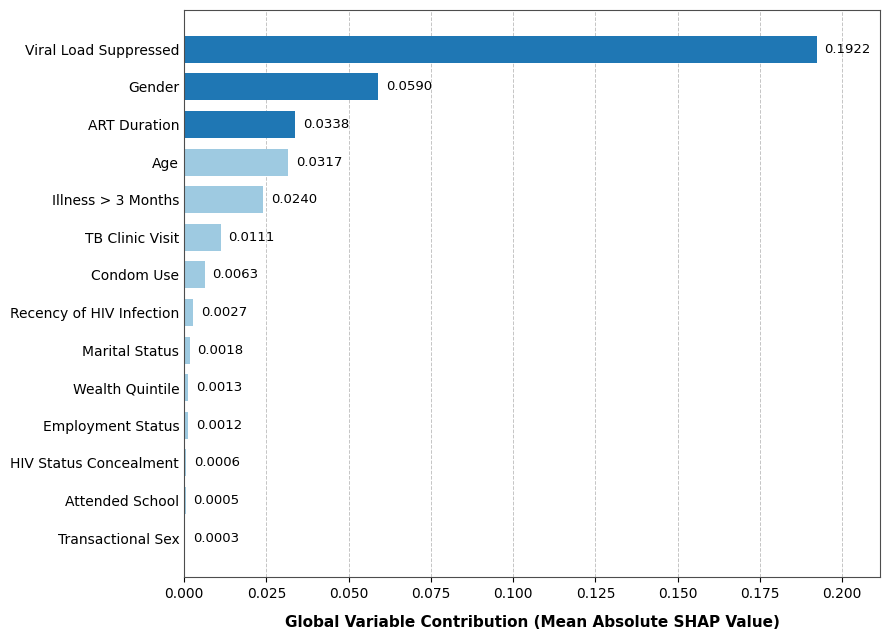

In [47]:
# ============================================================
# SHAP BAR CHART — matching your original styling
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

DARK   = '#1f77b4'    # top N bars
LIGHT  = '#9ecae1'    # remaining bars
TOP_N  = 3            # how many bars get the dark shade

display_names = {
    'viral_load_suppressed': 'Viral Load Suppressed',
    'gender':                'Gender',
    'art_duration_category': 'ART Duration',
    'age':                   'Age',
    'chronic_illness':       'Illness > 3 Months',
    'tb_clinic_visit':       'TB Clinic Visit',
    'condom_use':            'Condom Use',
    'recent_infection':      'Recency of HIV Infection',
    'marital_status':        'Marital Status',
    'wealth_quintile':       'Wealth Quintile',
    'employment_status':     'Employment Status',
    'hiv_status_disclosure': 'HIV Status Concealment',
    'attended_school':       'Attended School',
    'transactional_sex':     'Transactional Sex',
}

imp    = shap_values_all.abs().mean().sort_values(ascending=False)
labels = [display_names[c] for c in imp.index]
vals   = imp.values

colors = [DARK if i < TOP_N else LIGHT for i in range(len(vals))]

fig, ax = plt.subplots(figsize=(9, 6.5))

y = np.arange(len(vals))[::-1]                 # highest at top
ax.barh(y, vals, color=colors, edgecolor='none', height=0.72)
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=10)

for yi, v in zip(y, vals):
    ax.text(v + vals.max()*0.012, yi, f'{v:.4f}',
            va='center', ha='left', fontsize=9.5)

ax.set_xlabel('Global Variable Contribution (Mean Absolute SHAP Value)',
              fontsize=11, fontweight='bold', labelpad=10)
ax.set_xlim(0, vals.max()*1.10)
ax.xaxis.grid(True, linestyle='--', linewidth=0.7, color='0.75', alpha=0.9)
ax.set_axisbelow(True)
ax.tick_params(axis='y', length=0)
ax.tick_params(axis='x', labelsize=10)
for s in ax.spines.values():
    s.set_linewidth(0.8)
    s.set_color('0.3')

plt.tight_layout()
plt.savefig('fig_shap_bar_rf.png', dpi=300, bbox_inches='tight')
plt.savefig('fig_shap_bar_rf.tif', dpi=300, bbox_inches='tight')
plt.show()

rows 22,709   features 14   -- OK


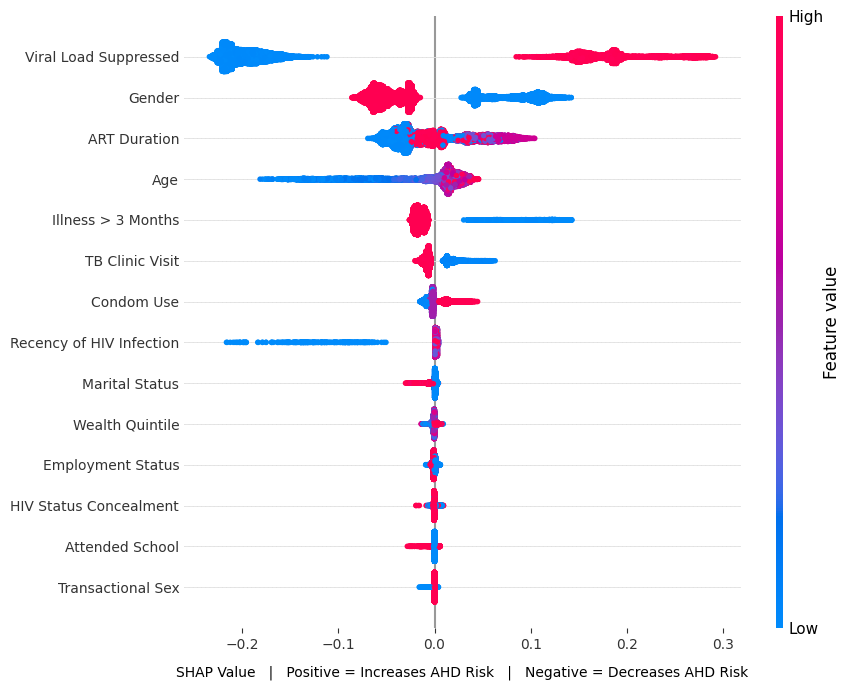

In [48]:
# ============================================================
# SHAP BEESWARM — corrected labels
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# --- point this at the pooled held-out feature values that go with
#     shap_values_all: same rows (22,709) and same 14 columns -------
X_FEATURES = X_shap_all      # <-- change the name if yours differs

display_names = {
    'viral_load_suppressed': 'Viral Load Suppressed',
    'gender':                'Gender',
    'art_duration_category': 'ART Duration',
    'age':                   'Age',
    'chronic_illness':       'Illness > 3 Months',
    'tb_clinic_visit':       'TB Clinic Visit',
    'condom_use':            'Condom Use',
    'recent_infection':      'Recency of HIV Infection',
    'marital_status':        'Marital Status',
    'wealth_quintile':       'Wealth Quintile',
    'employment_status':     'Employment Status',
    'hiv_status_disclosure': 'HIV Status Concealment',
    'attended_school':       'Attended School',
    'transactional_sex':     'Transactional Sex',
}

sv = shap_values_all.copy()
Xv = pd.DataFrame(X_FEATURES).copy()

# safety check — a silent mismatch would mis-colour every point
assert sv.shape == Xv.shape, f"shape mismatch: SHAP {sv.shape} vs features {Xv.shape}"
assert set(sv.columns) == set(Xv.columns), "column names do not match"
Xv = Xv[sv.columns]                       # force identical column order
print(f"rows {sv.shape[0]:,}   features {sv.shape[1]}   -- OK")

sv = sv.rename(columns=display_names)
Xv = Xv.rename(columns=display_names)

plt.figure(figsize=(9, 7))
shap.summary_plot(sv.values, Xv,
                  feature_names=list(sv.columns),
                  max_display=14, show=False, plot_size=None)

ax = plt.gca()
ax.set_xlabel('SHAP Value   |   Positive = Increases AHD Risk   |   '
              'Negative = Decreases AHD Risk', fontsize=10, labelpad=10)
ax.tick_params(axis='y', labelsize=10, length=0)
ax.tick_params(axis='x', labelsize=10)
ax.yaxis.grid(True, linestyle='-', linewidth=0.6, color='0.88')
ax.set_axisbelow(True)
for s in ax.spines.values():
    s.set_visible(False)

plt.tight_layout()
plt.savefig('fig_shap_beeswarm_rf.png', dpi=300, bbox_inches='tight')
plt.savefig('fig_shap_beeswarm_rf.tif', dpi=300, bbox_inches='tight')
plt.show()

In [49]:
# ============================================================
# BLOCK 1 — S1: missingness before imputation
# ============================================================
import pandas as pd

DF         = df            # <-- pooled dataset BEFORE any imputation
CANDIDATES = None          # <-- list of all screened variables, or None for all columns
THRESHOLD  = 31.0

cols = CANDIDATES if CANDIDATES is not None else list(DF.columns)
n    = len(DF)

rows = []
for c in cols:
    miss = DF[c].isna().sum()
    pct  = 100 * miss / n
    rows.append({'variable': c,
                 'n_miss':   int(miss),
                 'pct':      round(pct, 1),
                 'status':   'Excluded' if pct > THRESHOLD else 'Retained'})

out = pd.DataFrame(rows).sort_values('pct', ascending=False)
print(f"N = {n:,}   threshold = {THRESHOLD}%")
print(f"retained {(out.status=='Retained').sum()}   excluded {(out.status=='Excluded').sum()}\n")
print(out.to_string(index=False))

N = 11   threshold = 31.0%
retained 23   excluded 0

    variable  n_miss  pct   status
     Country       0  0.0 Retained
   Threshold       0  0.0 Retained
      Test N       0  0.0 Retained
      Good N       0  0.0 Retained
       AHD N       0  0.0 Retained
          TN       0  0.0 Retained
          FN       0  0.0 Retained
          FP       0  0.0 Retained
          TP       0  0.0 Retained
 Best_Params       0  0.0 Retained
Best_InnerCV       0  0.0 Retained
         NPV       0  0.0 Retained
     ROC-AUC       0  0.0 Retained
         PPV       0  0.0 Retained
 Specificity       0  0.0 Retained
 Sensitivity       0  0.0 Retained
   Precision       0  0.0 Retained
      Recall       0  0.0 Retained
    F1-Score       0  0.0 Retained
Balanced Acc       0  0.0 Retained
    Accuracy       0  0.0 Retained
      PR-AUC       0  0.0 Retained
  N Features       0  0.0 Retained


In [50]:
import pandas as pd
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(f"{name:<24} {obj.shape[0]:>7,} rows x {obj.shape[1]:<4} cols   NaN = {int(obj.isna().sum().sum()):,}")

df                            11 rows x 23   cols   NaN = 0
model_df                  22,709 rows x 39   cols   NaN = 70,813
missing_report                96 rows x 3    cols   NaN = 0
summary_df                    39 rows x 6    cols   NaN = 0
X_tr                      22,095 rows x 33   cols   NaN = 0
X_te                         614 rows x 33   cols   NaN = 0
X_tr_imputed              22,095 rows x 33   cols   NaN = 0
X_te_imputed                 614 rows x 33   cols   NaN = 0
X_tr_check                22,095 rows x 35   cols   NaN = 68,574
X_te_check                   614 rows x 35   cols   NaN = 2,205
combined_df                    3 rows x 4    cols   NaN = 0
X_tr_scaled               22,095 rows x 33   cols   NaN = 0
X_te_scaled                  614 rows x 33   cols   NaN = 0
X_tr_scaled_final         22,095 rows x 33   cols   NaN = 0
X_te_scaled_final            614 rows x 33   cols   NaN = 0
X_fs_tr                   22,095 rows x 33   cols   NaN = 0
X_fs_te                   

In [51]:
DF        = model_df
THRESHOLD = 31.0

n = len(DF)
rows = []
for c in DF.columns:
    miss = DF[c].isna().sum()
    pct  = 100 * miss / n
    rows.append({'variable': c, 'n_miss': int(miss), 'pct': round(pct, 1),
                 'status': 'Excluded' if pct > THRESHOLD else 'Retained'})

out = pd.DataFrame(rows).sort_values('pct', ascending=False)
print(f"N = {n:,}   threshold = {THRESHOLD}%   above threshold: {(out.pct > THRESHOLD).sum()}\n")
print(out.to_string(index=False))

print("\n\n--- missing_report ---")
print(missing_report.to_string(index=False))

print("\n\n--- final 14 predictors ---")
print(list(X_full.columns))

N = 22,709   threshold = 31.0%   above threshold: 1

             variable  n_miss  pct   status
               cd4tty    9956 43.8 Excluded
            hivtfposy    6880 30.3 Retained
         partlastsup1    6749 29.7 Retained
        partlastcndm1    6693 29.5 Retained
           partlivew1    6617 29.1 Retained
          hivstathide    6215 27.4 Retained
               arvnvp    5053 22.3 Retained
               curmar    4214 18.6 Retained
       hivtstlocation    3369 14.8 Retained
               schcom    2459 10.8 Retained
              schlcur    2218  9.8 Retained
condomlastsex12months    1973  8.7 Retained
           firstsxage    1777  7.8 Retained
          sex12months    1562  6.9 Retained
          artduration    1048  4.6 Retained
            uniontype     616  2.7 Retained
              sick3mo     596  2.6 Retained
               arvefv     456  2.0 Retained
               arvlpv     456  2.0 Retained
            arvstatus     456  2.0 Retained
       recentlagvlarv  

In [52]:
# ============================================================
# VIRAL LOAD CHECK  —  paste into a new notebook cell and run
#
# Answers Reviewer #1, Minor comment 2:
#   "What if there were multiple viral loads available?
#    Did you just select the most recent for viral suppression?"
#
# Nothing is saved. Everything prints to screen.
# ============================================================

import pandas as pd

# ---- PART A -------------------------------------------------
# Works on model_df, already in memory. No file paths needed.
# ------------------------------------------------------------

print("=" * 70)
print("  PART A — the analytical dataset (model_df)")
print("=" * 70)

print(f"\n  shape: {model_df.shape[0]:,} rows x {model_df.shape[1]} columns")

vl_cols = [c for c in model_df.columns
           if 'vl' in c.lower() or 'viral' in c.lower() or 'rna' in c.lower()]
print(f"\n  columns mentioning vl / viral / rna  ({len(vl_cols)} found):")
for c in vl_cols:
    print(f"      {c}")

print("\n  vls value counts (including missing):")
print(model_df['vls'].value_counts(dropna=False).to_string())

# one row per participant?
id_like = [c for c in model_df.columns
           if c.lower() in ('personid', 'person_id', 'participantid', 'id',
                            'hhid', 'householdid', 'centroidid')]
print(f"\n  id-like columns found: {id_like if id_like else 'none'}")
for c in id_like:
    dup = model_df[c].duplicated().sum()
    print(f"      {c}: {dup:,} duplicate values "
          f"({'one row per participant' if dup == 0 else 'REPEATED ROWS — check this'})")

# any column that looks like a visit number, sequence or measurement date
seq = [c for c in model_df.columns
       if any(k in c.lower() for k in ('visit', 'round', 'wave', 'seq', '_1', '_2', '_3'))]
print(f"\n  columns suggesting repeated measures: {seq if seq else 'none'}")


# ---- PART B -------------------------------------------------
# The RAW PHIA biomarker file, BEFORE your merge.
# Set BIO_PATH to any ONE country's biomarker recode, then re-run.
# ------------------------------------------------------------

BIO_PATH = None      # <-- e.g. r"C:\Users\leula\PHIA\ethiopia\bio.csv"

print("\n" + "=" * 70)
print("  PART B — the raw PHIA biomarker recode")
print("=" * 70)

if BIO_PATH is None:
    print("\n  BIO_PATH not set. Set it to any one country's biomarker file")
    print("  and re-run this cell. Part A alone is not conclusive, because")
    print("  your merge may already have dropped extra viral load columns.")
else:
    bio = pd.read_csv(BIO_PATH, low_memory=False)
    print(f"\n  file: {BIO_PATH}")
    print(f"  shape: {bio.shape[0]:,} rows x {bio.shape[1]} columns")

    bvl = [c for c in bio.columns
           if 'vl' in c.lower() or 'viral' in c.lower() or 'rna' in c.lower()]
    print(f"\n  columns mentioning vl / viral / rna  ({len(bvl)} found):")
    for c in bvl:
        nonnull = bio[c].notna().sum()
        print(f"      {c:<28} non-missing {nonnull:,}")

    bid = [c for c in bio.columns if c.lower() in ('personid', 'person_id', 'participantid')]
    for c in bid:
        dup = bio[c].duplicated().sum()
        print(f"\n  {c}: {dup:,} duplicate values "
              f"({'one row per participant' if dup == 0 else 'REPEATED ROWS'})")

print("\n" + "=" * 70)
print("  WHAT TO LOOK FOR")
print("=" * 70)
print("""
  CLAIM HOLDS if every viral load column is a different derived form
  of ONE measurement — e.g. vls, vlcat, vldetect, vlunder200 — and the
  participant id has no duplicates.

  CLAIM FAILS if you see a visit number, a sequence suffix, a
  measurement date, or more than one row per participant.
""")

  PART A — the analytical dataset (model_df)

  shape: 22,709 rows x 39 columns

  columns mentioning vl / viral / rna  (3 found):
      arvlpv
      recentlagvlarv
      vls

  vls value counts (including missing):
vls
1.0    14797
2.0     7844
NaN       68

  id-like columns found: none

  columns suggesting repeated measures: ['tbclinvisit']

  PART B — the raw PHIA biomarker recode

  BIO_PATH not set. Set it to any one country's biomarker file
  and re-run this cell. Part A alone is not conclusive, because
  your merge may already have dropped extra viral load columns.

  WHAT TO LOOK FOR

  CLAIM HOLDS if every viral load column is a different derived form
  of ONE measurement — e.g. vls, vlcat, vldetect, vlunder200 — and the
  participant id has no duplicates.

  CLAIM FAILS if you see a visit number, a sequence suffix, a
  measurement date, or more than one row per participant.



In [53]:
print(pd.crosstab(model_df['country_y'], model_df['urban'], dropna=False))

urban             1     2
country_y                
Cameroon        461   530
Côte d'Ivoire   263   173
Eswatini        732  2319
Ethiopia        614     0
Lesotho        1297  1934
Malawi         1068  1151
Namibia         883  1559
Tanzania        763  1123
Uganda          624  1149
Zambia         1441  1065
Zimbabwe       1090  2470


In [54]:
import pandas as pd

OUTCOME = 'cd4_who_category'    # <-- confirm this is your AHD indicator

print("1. RAW GENDER CODING")
print(model_df['gender_y'].value_counts(dropna=False).to_string())

print("\n2. OUTCOME CODING")
print(model_df[OUTCOME].value_counts(dropna=False).to_string())

print("\n3. OBSERVED AHD PREVALENCE BY GENDER")
print((pd.crosstab(model_df['gender_y'], model_df[OUTCOME], normalize='index') * 100).round(2).to_string())

print("\n4. MEAN SHAP BY GENDER VALUE (scaled)")
g = X_shap_all['gender']
s = shap_values_all['gender']
for v in sorted(g.unique()):
    m = g == v
    print(f"   scaled {v:+.4f}   n = {m.sum():,}   mean SHAP = {s[m].mean():+.5f}")
print("\n   (the LOWER scaled value corresponds to the LOWER raw code)")

1. RAW GENDER CODING
gender_y
2    15429
1     7280

2. OUTCOME CODING
cd4_who_category
0    20114
1     2595

3. OBSERVED AHD PREVALENCE BY GENDER
cd4_who_category      0      1
gender_y                      
1                 83.35  16.65
2                 91.04   8.96

4. MEAN SHAP BY GENDER VALUE (scaled)
   scaled -1.4738   n = 1,243   mean SHAP = +0.07329
   scaled -1.4582   n = 992   mean SHAP = +0.08976
   scaled -1.4570   n = 576   mean SHAP = +0.07800
   scaled -1.4564   n = 715   mean SHAP = +0.08178
   scaled -1.4552   n = 136   mean SHAP = +0.06540
   scaled -1.4548   n = 1,030   mean SHAP = +0.08208
   scaled -1.4548   n = 797   mean SHAP = +0.07986
   scaled -1.4538   n = 592   mean SHAP = +0.07433
   scaled -1.4520   n = 293   mean SHAP = +0.06871
   scaled -1.4509   n = 753   mean SHAP = +0.08357
   scaled -1.4492   n = 153   mean SHAP = +0.08555
   scaled +0.6785   n = 2,317   mean SHAP = -0.04402
   scaled +0.6858   n = 2,059   mean SHAP = -0.05295
   scaled +0.6863 

  MULTI-METRIC COUNTRY × MODEL HEATMAP
  LOCO Cross-Validation Results


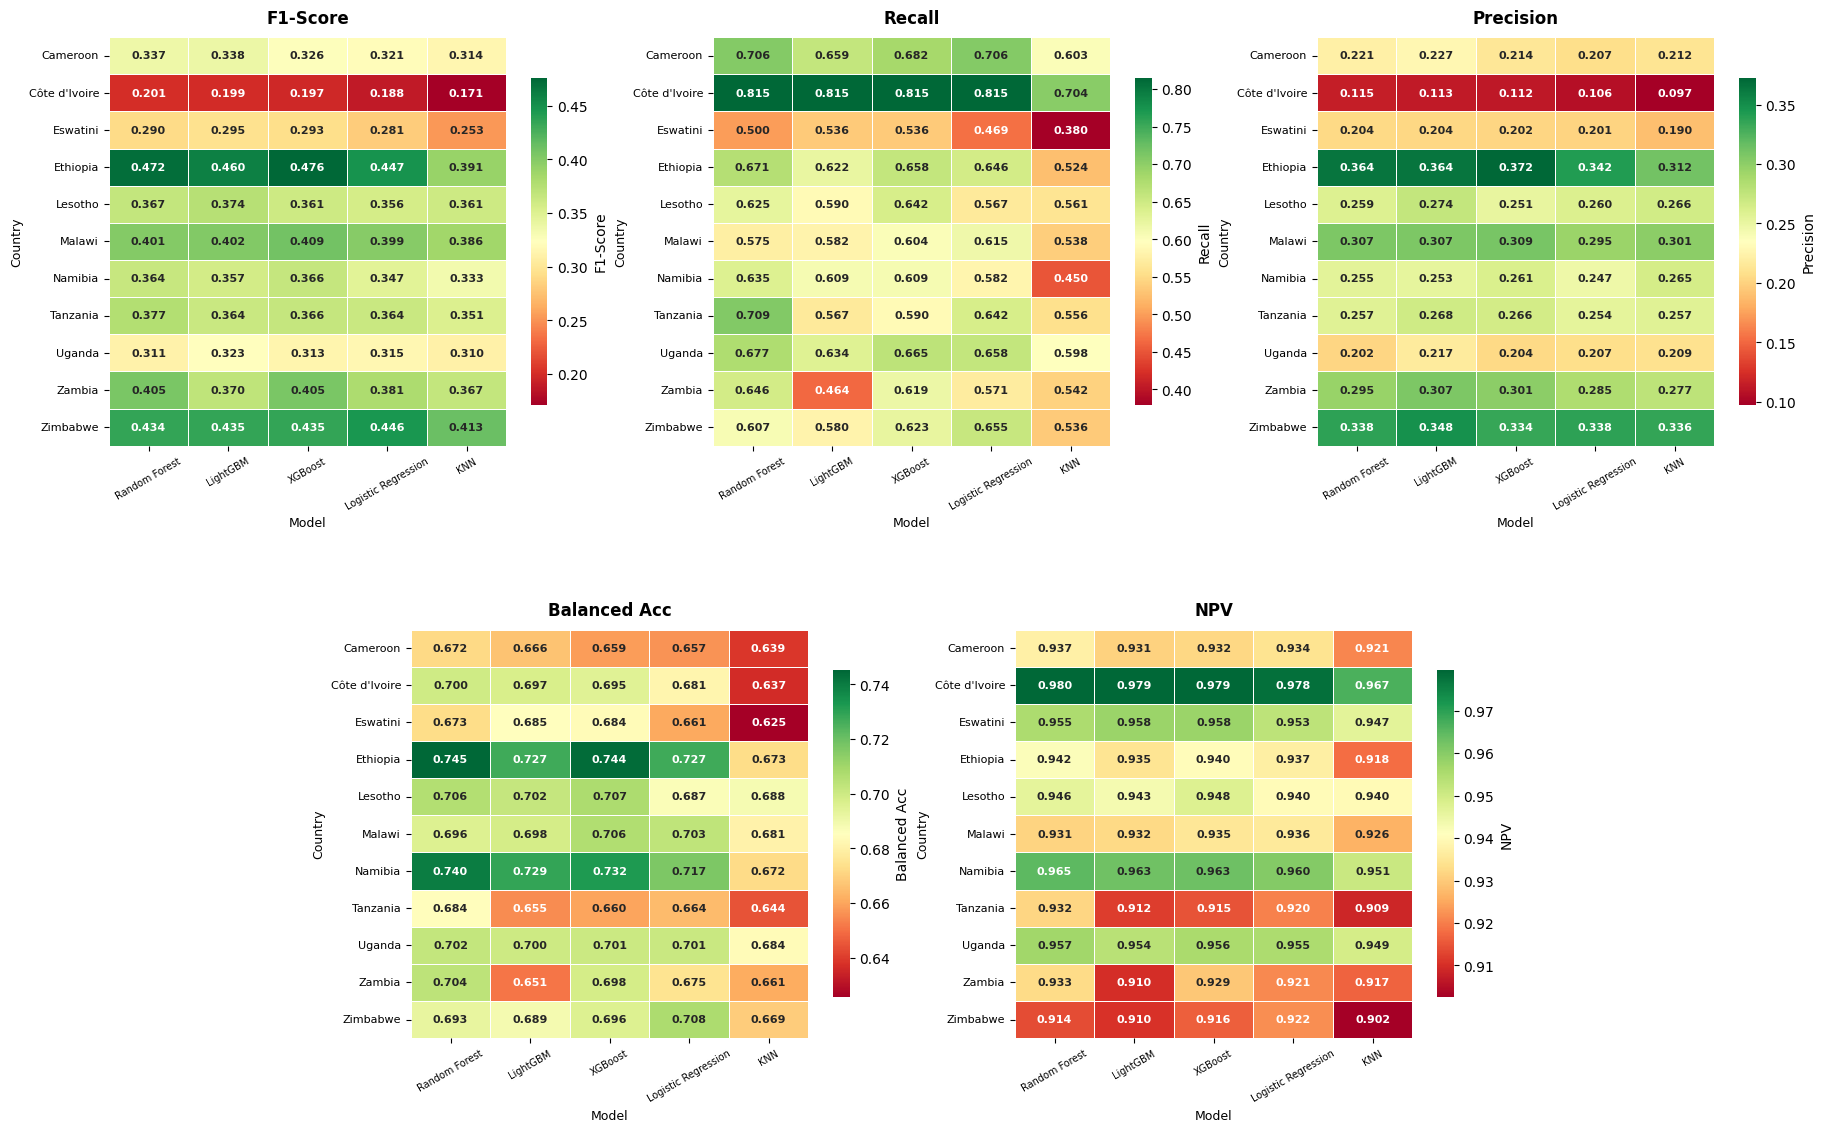


  ✅ Figure saved: fig_multi_metric_heatmap.png


In [55]:
# ============================================================
# MULTI-METRIC COUNTRY × MODEL HEATMAP
# 5 metrics — 3 top + 2 bottom CENTERED
# Q1 Manuscript Ready
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

print("=" * 65)
print("  MULTI-METRIC COUNTRY × MODEL HEATMAP")
print("  LOCO Cross-Validation Results")
print("=" * 65)

# ============================================================
# MODEL ORDER
# ============================================================
model_order = [
    'Random Forest',
    'LightGBM',
    'XGBoost',
    'Logistic Regression',
    'KNN'
]

# ============================================================
# COUNTRY ORDER
# ============================================================
country_order = sorted(list(set(
    row['Country']
    for df in all_models.values()
    for _, row in df.iterrows()
)))

# ============================================================
# EXACTLY 5 METRICS
# ============================================================
metrics_to_plot = [
    'F1-Score',
    'Recall',
    'Precision',
    'Balanced Acc',
    'NPV'
]

# ============================================================
# FIGURE SETUP
# Top row    : 3 plots (columns 0, 1, 2)
# Bottom row : 2 plots CENTERED
#              using GridSpec with 6 columns
#              bottom left  starts at col 1
#              bottom right starts at col 3
# ============================================================
fig = plt.figure(figsize=(22, 13))

gs = gridspec.GridSpec(
    2, 6,
    figure=fig,
    hspace=0.45,
    wspace=0.55)

# Top row — 3 equally spaced plots
ax1 = fig.add_subplot(gs[0, 0:2])
ax2 = fig.add_subplot(gs[0, 2:4])
ax3 = fig.add_subplot(gs[0, 4:6])

# Bottom row — 2 CENTERED plots
# Left plot  : columns 1-3 (centered left)
# Right plot : columns 3-5 (centered right)
ax4 = fig.add_subplot(gs[1, 1:3])
ax5 = fig.add_subplot(gs[1, 3:5])

axes = [ax1, ax2, ax3, ax4, ax5]

# ============================================================
# BUILD AND PLOT EACH HEATMAP
# ============================================================
for idx, metric in enumerate(metrics_to_plot):

    metric_matrix = pd.DataFrame(
        index=country_order,
        columns=model_order,
        dtype=float)

    for model_name, df in all_models.items():
        if model_name not in model_order:
            continue
        for _, row in df.iterrows():
            country = row['Country']
            if country in country_order \
                    and metric in row.index:
                metric_matrix.loc[
                    country,
                    model_name] = row[metric]

    sns.heatmap(
        metric_matrix.astype(float),
        ax=axes[idx],
        annot=True,
        fmt='.3f',
        cmap='RdYlGn',
        linewidths=0.5,
        linecolor='white',
        annot_kws={
            'size': 8,
            'fontweight': 'bold'},
        cbar_kws={
            'shrink': 0.8,
            'label': metric})

    axes[idx].set_title(
        metric,
        fontsize=12,
        fontweight='bold',
        pad=10)
    axes[idx].set_xlabel(
        'Model', fontsize=9)
    axes[idx].set_ylabel(
        'Country', fontsize=9)
    axes[idx].tick_params(
        axis='x',
        rotation=30,
        labelsize=7)
    axes[idx].tick_params(
        axis='y',
        rotation=0,
        labelsize=8)

# ============================================================
# OVERALL TITLE
# ============================================================

plt.savefig(
    'fig_multi_metric_heatmap.png',
    dpi=300,
    bbox_inches='tight')
plt.show()

print("\n  ✅ Figure saved: "
      "fig_multi_metric_heatmap.png")

In [ ]:
# ============================================================
# FIGURE: COUNTRY-LEVEL PERFORMANCE HEATMAP
# Shows ROC-AUC and PR-AUC for all models
# and all countries simultaneously
# No "best model" labeling needed
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 65)
print("  COUNTRY-LEVEL PERFORMANCE HEATMAP")
print("  All 5 Models — All 11 Countries")
print("=" * 65)

# ============================================================
# STEP 1: BUILD DATA MATRICES
# ============================================================
model_order = [
    'Random Forest',
    'LightGBM',
    'XGBoost',
    'Logistic Regression',
    'KNN'
]

country_order = [
    'Ethiopia', 'Namibia', 'Zimbabwe',
    'Lesotho', 'Malawi', 'Zambia',
    'Uganda', 'Eswatini', 'Tanzania',
    'Cameroon', "Côte d'Ivoire"
]

# Build ROC-AUC matrix
roc_matrix  = pd.DataFrame(
    index=country_order,
    columns=model_order,
    dtype=float)

# Build PR-AUC matrix
pr_matrix   = pd.DataFrame(
    index=country_order,
    columns=model_order,
    dtype=float)

# Build Recall matrix
rec_matrix  = pd.DataFrame(
    index=country_order,
    columns=model_order,
    dtype=float)

# Fill matrices
for model_name, df in all_models.items():
    if model_name not in model_order:
        continue
    for _, row in df.iterrows():
        country = row['Country']
        if country in country_order:
            roc_matrix.loc[
                country, model_name] = \
                row['ROC-AUC']
            pr_matrix.loc[
                country, model_name] = \
                row['PR-AUC']
            rec_matrix.loc[
                country, model_name] = \
                row['Recall']

# ============================================================
# FIGURE 1 — ROC-AUC AND PR-AUC SIDE BY SIDE
# Main manuscript figure
# ============================================================
fig, axes = plt.subplots(
    1, 2, figsize=(16, 7))

# ── ROC-AUC Heatmap ────────────────────────────
sns.heatmap(
    roc_matrix.astype(float),
    ax=axes[0],
    annot=True,
    fmt='.3f',
    cmap='RdYlGn',
    vmin=0.65,
    vmax=0.90,
    linewidths=0.5,
    linecolor='white',
    annot_kws={'size': 9,
               'fontweight': 'bold'},
    cbar_kws={
        'label': 'ROC-AUC',
        'shrink': 0.8})

axes[0].set_title("")
axes[0].set_xlabel(
    'Model', fontsize=11)
axes[0].set_ylabel(
    'Country', fontsize=11)
axes[0].tick_params(
    axis='x',
    rotation=30,
    labelsize=9)
axes[0].tick_params(
    axis='y',
    rotation=0,
    labelsize=9)

# ── PR-AUC Heatmap ─────────────────────────────
sns.heatmap(
    pr_matrix.astype(float),
    ax=axes[1],
    annot=True,
    fmt='.3f',
    cmap='RdYlGn',
    vmin=0.15,
    vmax=0.45,
    linewidths=0.5,
    linecolor='white',
    annot_kws={'size': 9,
               'fontweight': 'bold'},
    cbar_kws={
        'label': 'PR-AUC',
        'shrink': 0.8})

axes[1].set_title("")
axes[1].set_xlabel(
    'Model', fontsize=11)
axes[1].set_ylabel(
    '', fontsize=11)
axes[1].tick_params(
    axis='x',
    rotation=30,
    labelsize=9)
axes[1].tick_params(
    axis='y',
    rotation=0,
    labelsize=9)
plt.tight_layout()
plt.savefig(
    'fig_heatmap_roc_pr.png',
    dpi=300,
    bbox_inches='tight')
plt.show()
print("  ✅ Figure 1 saved: fig_heatmap_roc_pr.png")

# ============================================================
# FIGURE 2 — RECALL HEATMAP
# Most clinically important — catching AHD patients
# ============================================================
fig, ax = plt.subplots(figsize=(10, 7))

sns.heatmap(
    rec_matrix.astype(float),
    ax=ax,
    annot=True,
    fmt='.3f',
    cmap='RdYlGn',
    vmin=0.40,
    vmax=0.85,
    linewidths=0.5,
    linecolor='white',
    annot_kws={'size': 10,
               'fontweight': 'bold'},
    cbar_kws={
        'label': 'Recall (Sensitivity)',
        'shrink': 0.8})

ax.set_title(
    'Recall (Sensitivity) by Country and Model\n'
    'Proportion of AHD Cases Correctly Identified\n'
    'LOCO Cross-Validation',
    fontsize=12,
    fontweight='bold',
    pad=12)
ax.set_xlabel('Model', fontsize=11)
ax.set_ylabel('Country', fontsize=11)
ax.tick_params(
    axis='x', rotation=30, labelsize=9)
ax.tick_params(
    axis='y', rotation=0, labelsize=9)

plt.tight_layout()
plt.savefig(
    'fig_heatmap_recall.png',
    dpi=300,
    bbox_inches='tight')
plt.show()
print("  ✅ Figure 2 saved: fig_heatmap_recall.png")

# ============================================================
# FIGURE 3 — ALL METRICS COMBINED HEATMAP
# For supplementary material
# ============================================================
metrics_to_show = [
    'ROC-AUC', 'PR-AUC',
    'F1-Score', 'Recall',
    'Specificity', 'NPV']

fig, axes = plt.subplots(
    2, 3, figsize=(18, 12))
axes = axes.flatten()

vmin_map = {
    'ROC-AUC':    0.65,
    'PR-AUC':     0.15,
    'F1-Score':   0.15,
    'Recall':     0.40,
    'Specificity':0.55,
    'NPV':        0.90
}
vmax_map = {
    'ROC-AUC':    0.90,
    'PR-AUC':     0.45,
    'F1-Score':   0.55,
    'Recall':     0.85,
    'Specificity':0.95,
    'NPV':        0.98
}

for idx, metric in enumerate(metrics_to_show):

    metric_matrix = pd.DataFrame(
        index=country_order,
        columns=model_order,
        dtype=float)

    for model_name, df in all_models.items():
        if model_name not in model_order:
            continue
        for _, row in df.iterrows():
            country = row['Country']
            if country in country_order \
                    and metric in row:
                metric_matrix.loc[
                    country,
                    model_name] = row[metric]

    sns.heatmap(
        metric_matrix.astype(float),
        ax=axes[idx],
        annot=True,
        fmt='.3f',
        cmap='RdYlGn',
        vmin=vmin_map.get(metric, 0),
        vmax=vmax_map.get(metric, 1),
        linewidths=0.5,
        linecolor='white',
        annot_kws={'size': 8},
        cbar_kws={
            'label': metric,
            'shrink': 0.8})

    axes[idx].set_title(
        metric,
        fontsize=11,
        fontweight='bold')
    axes[idx].set_xlabel(
        'Model', fontsize=9)
    axes[idx].set_ylabel(
        'Country', fontsize=9)
    axes[idx].tick_params(
        axis='x',
        rotation=30,
        labelsize=7)
    axes[idx].tick_params(
        axis='y',
        rotation=0,
        labelsize=8)

plt.suptitle(
    'Comprehensive Model Performance — '
    'All Metrics\n'
    'All 5 Models × 11 SSA Countries — '
    'LOCO Cross-Validation',
    fontsize=13,
    fontweight='bold',
    y=1.01)

plt.tight_layout()
plt.savefig(
    'fig_heatmap_all_metrics.png',
    dpi=300,
    bbox_inches='tight')
plt.show()
print("  ✅ Figure 3 saved: "
      "fig_heatmap_all_metrics.png")

print(f"\n{'='*65}")
print(f"  ALL HEATMAP FIGURES COMPLETE")
print(f"{'='*65}")
print("""
  fig_heatmap_roc_pr.png
    → Main manuscript Figure X
    → ROC-AUC + PR-AUC side by side

  fig_heatmap_recall.png
    → Main manuscript Figure X+1
    → Recall — most clinically important

  fig_heatmap_all_metrics.png
    → Supplementary Figure S1
    → All 6 metrics comprehensive view
""")
print("✅ Complete — share figures for manuscript")